In [1]:
# [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด
# ==================================================
# ทำอะไร: โน้ตบุ๊คนี้ฝึกโมเดล XGBoost (ต้นไม้หลายต้นที่เรียนต่อกันแบบ boosting) ทายราคารถมือสอง
#         จากไฟล์ merge_50min_clean.csv แล้วปรับค่าตั้งของโมเดล (hyperparameter) ด้วย cross-validation
# ใช้ไฟล์สะอาด; ทำความสะอาดนอกโน้ตบุ๊คด้วยสคริปต์ data/main/clean_merged_min50.py และบันทึก data/main/merge_50min_clean_steps.md; เซลล์ตรวจคุณภาพตรวจอย่างเดียว ไม่ลบแถว
#         บน train และพิมพ์ผลบนชุด train / validation / test โดยไม่เขียนไฟล์ใดๆ ลงเครื่อง
#         ใช้หลักการเดียวกับโน้ตบุ๊ค Decision Tree (v4_DT): วิธีแบ่งชุดและสร้าง fold แบบเดิม
#         การเข้ารหัส FoldOneHot เดิม และเลือกผู้ชนะด้วยกฎ 1-SE แบบเดียวกัน
#         เซลล์นี้เป็นทั้งคำอธิบายภาพรวมและที่รวม import ทั้งหมด (เซลล์อื่นไม่ import เพิ่ม)
#
# วิธีรัน (บนเครื่องนี้ใน VS Code):
#   1. ปิดโปรแกรมที่กินหน่วยความจำมากก่อน (เบราว์เซอร์หลายแท็บ โน้ตบุ๊คอื่นที่เปิด kernel ค้างไว้)
#      เพราะช่วง grid search (เซลล์ [26]) รัน 6 process พร้อมกัน แต่ละตัวถือสำเนาข้อมูลและโมเดล
#      คาดว่าใช้หน่วยความจำรวมสูงสุดราว 3.5 GB (ประมาณจากรอบทดสอบ 2026-10-23) ควรมีหน่วยความจำว่างอย่างน้อย 4 GB
#   2. เปิดไฟล์ v4_XGB_local.ipynb ใน VS Code
#   3. กด "Select Kernel" มุมขวาบน แล้วเลือก Python ของ D:\AI_Workspace\car-project\research\.venv
#      (research/.venv, Python 3.14) ซึ่งติดตั้ง xgboost, scikit-learn, pandas ไว้แล้ว
#   4. กด "Run All" แล้วรอจนเซลล์สุดท้าย [40] พิมพ์บรรทัดสรุป
#      เวลาที่คาดทั้งโน้ตบุ๊คราว 30-40 นาที ส่วนใหญ่อยู่ที่เซลล์ [26] ซึ่งเงียบระหว่างรันเป็นเรื่องปกติ
#      (ประมาณจากเวลาที่วัดในการทดลองนำร่องแล้วขยายเป็น 18 core ตัวเลขจริงขึ้นกับโปรแกรมอื่นที่เปิดอยู่)
#   5. อย่าหยุดกลางคัน ถ้าเครื่องหน่วยความจำไม่พอ ให้ลด SEARCH_JOBS ในเซลล์ [03] แล้วรันใหม่
#
# แผนที่ของโน้ตบุ๊ค (เลขในวงเล็บคือเลขเซลล์):
#   - ตั้งค่าและอ่านข้อมูล             [01]-[04]
#   - ตรวจคุณภาพข้อมูล                 [05]-[11]
#   - เตรียมข้อมูลและแบ่งชุด           [12]-[14]
#   - ความสัมพันธ์ระหว่างตัวแปรทีละคู่  [15]-[17]
#   - โมเดลและ grid                    [18]-[22]
#   - กฎ 1-SE และ grid search          [23]-[28]
#   - วัดผล                            [29]-[31]
#   - การตรวจเพิ่มเติม                 [32]-[39]
#   - สรุปการตรวจ overfit              [40]
#
# ต่างจากโน้ตบุ๊ค v4_XGB ต้นฉบับ (เหตุผลอยู่ในคอมเมนต์ของแต่ละเซลล์):
#   - รันบนเครื่องนี้ใน VS Code เท่านั้น ไม่ต้องเชื่อม Google Drive               [02]
#   - ไม่เปลี่ยนชื่อคอลัมน์                                                      [12]
#   - ไม่มีขั้นคัดเลือกตัวแปร (feature selection)                               [18]
#   - ออกแบบ grid ใหม่จากการทดลองนำร่องบน train ให้คร่อมค่าที่ดีที่สุด
#     และปรับจำนวนรอบ (n_estimators) ด้วย CV โดย learning rate คงที่              [03], [21]
#   - เลือกผู้ชนะด้วยกฎ 1-SE คือเลือกโมเดลที่มีใบรวมน้อยที่สุด
#     ในช่วงหนึ่ง SE จากค่า MAE ต่ำสุด แทนการเลือก MAE ต่ำสุดตรงๆ (refit="MAE")    [22]-[27]
#   - ไม่มีโหมด SMOKE (โหมดทดสอบแบบลดงาน) โน้ตบุ๊คนี้รันเต็มทุกครั้ง
#   - เพิ่มการตรวจที่ต้นฉบับไม่มี:
#       คุณภาพข้อมูล [05]-[11], ความสัมพันธ์ทีละคู่ [15]-[17], ตรวจขอบ grid [28],
#       ตาราง 10 อันดับแรก [32], learning curve [33]-[34], CV train เทียบ validation [35],
#       validation curve [36]-[37], MAE รายรอบ [38]-[39], สรุปการตรวจ overfit [40]
#
# อภิธานศัพท์ (ศัพท์ที่จะเจอตลอดโน้ตบุ๊ค):
#   - train / validation / test: ข้อมูลสามชุด
#       train       ใช้สอนโมเดล (ให้โมเดลดูคำตอบแล้วเรียนรู้)
#       validation  กันไว้ตรวจผลอีกชุดที่โมเดลไม่เคยเห็น (ในโน้ตบุ๊คนี้การเลือกพารามิเตอร์
#                   ใช้ cross-validation บน train ส่วน validation ใช้รายงานผลคู่กับ test)
#       test        เก็บไว้ตัดสินผลสุดท้ายครั้งเดียว ไม่เอามาปรับโมเดล
#   - fold และ cross-validation (CV): แบ่งชุด train เป็นหลายส่วน (fold)
#       แล้วผลัดกันเอาทีละ fold ไปเป็นชุดทดสอบ ส่วนที่เหลือใช้สอน
#       ได้คะแนนหลายรอบมาเฉลี่ย เชื่อถือกว่าการลองแค่รอบเดียว
#   - feature: คอลัมน์ที่โมเดลใช้ทายราคา เช่น ยี่ห้อ รุ่น เลขไมล์ อายุรถ
#   - hyperparameter: ค่าที่เราตั้งเองก่อนฝึก เช่น ความลึกของต้นไม้
#       (ต่างจากค่าที่โมเดลเรียนรู้เอง)
#   - MAE (Mean Absolute Error): ค่าเฉลี่ยของ "ทายผิดไปกี่บาท" ไม่สนว่าสูงหรือต่ำไป
#       ยิ่งต่ำยิ่งดี หน่วยเป็นบาท
#   - RMSE (Root Mean Squared Error): คล้าย MAE แต่ลงโทษความผิดพลาดก้อนใหญ่หนักกว่า
#       หน่วยเป็นบาท ยิ่งต่ำยิ่งดี
#   - MAPE (Mean Absolute Percentage Error): ทายผิดเฉลี่ยกี่เปอร์เซ็นต์ของราคาจริง
#       ยิ่งต่ำยิ่งดี
#   - R² : สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ทายตรงทุกคัน
#       0 = ไม่ดีกว่าการทายราคาเฉลี่ยทุกคัน (ค่าติดลบได้ถ้าแย่กว่านั้น)
#   - overfit: โมเดลจำข้อมูล train ได้ดีเกินไป จนทายข้อมูลใหม่ไม่ดี
#       (คะแนน train ดีมาก แต่ validation / test แย่กว่ามาก)
#   - underfit: โมเดลง่ายเกินไป จับรูปแบบในข้อมูลไม่ได้ ทายแย่ทั้ง train และข้อมูลใหม่
#   - decision tree (ต้นไม้ตัดสินใจ): ชุดคำถามใช่/ไม่ใช่ต่อกันเป็นกิ่ง เช่น "อายุรถเกิน 5 ปีไหม"
#       ปลายกิ่งเรียกว่า ใบ (leaf) แต่ละใบให้ค่าคำตอบหนึ่งค่า
#   - ensemble: โมเดลที่รวมคำตอบของโมเดลย่อยหลายตัว (ที่นี่คือต้นไม้หลายต้น) ให้ผลดีกว่าตัวเดียว
#   - boosting: วิธีสร้าง ensemble แบบต่อกันทีละตัว ต้นใหม่แต่ละต้นเรียนจาก "ส่วนที่ยังทายผิด"
#       (residual = ราคาจริง - ราคาที่ทายตอนนี้) ของต้นก่อน ๆ แล้วเอาคำตอบของทุกต้นมาบวกกัน
#       XGBoost (eXtreme Gradient Boosting) คือไลบรารี boosting ที่นิยมมากกับข้อมูลตาราง
#   - boosting round (รอบ): การเพิ่มต้นไม้ 1 ต้น จำนวนรอบ = จำนวนต้นไม้ = n_estimators
#       รอบน้อยไป = underfit รอบมากไป = เริ่มจำข้อมูลฝึก (overfit)
#   - learning rate: ตัวคูณย่อขนาดการแก้ของแต่ละต้น เช่น 0.1 = ใช้แค่ 10% ของที่ต้นนั้นเสนอ
#       ค่าเล็ก = เรียนช้าแต่ระวัง ต้องใช้รอบมากขึ้น
#   - regularization (บทลงโทษความซับซ้อน): ส่วนที่กันไม่ให้โมเดลจำข้อมูลมากเกินไป
#       เช่น reg_lambda ที่ดึงค่าในใบเข้าหาศูนย์ และ min_child_weight ที่บังคับให้ใบมีรถขั้นต่ำ
#   - 1-SE rule: กฎเลือกโมเดลที่เรียบง่ายที่สุดในกลุ่มที่ผลไม่ต่างจากที่ดีที่สุดเกิน 1 SE
#       (SE = standard error = ความคลาดเคลื่อนมาตรฐานของค่าเฉลี่ย) อธิบายละเอียดในเซลล์ [23]
# ==================================================
import hashlib
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display
from joblib import parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, KFold, train_test_split,
                                     cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

print("=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===")
print("import ครบแล้ว")
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score


=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===
import ครบแล้ว


In [2]:
# [02] กำหนดที่อยู่ไฟล์ข้อมูล
# ==================================================
# ทำอะไร: กำหนดตัวแปร DATA_PATH ให้ชี้ไปที่ไฟล์ new_car_dataset.csv บนเครื่องนี้
# ทำไม: โน้ตบุ๊คนี้รันบนเครื่องส่วนตัวใน VS Code เท่านั้น (ไม่ใช่ Google Colab)
#       จึงไม่ต้องเชื่อม Google Drive และไม่ต้องตรวจว่ารันที่ไหน เซลล์ถัดไปอ่านไฟล์จากที่อยู่นี้
#       ใช้เครื่องหมาย / คั่นโฟลเดอร์ ซึ่ง Python บน Windows อ่านได้ปกติ
# ผลที่ควรเห็น: บรรทัดเดียวบอกที่อยู่ไฟล์ DATA_PATH
# ข้อควรระวัง: ถ้าย้ายไฟล์ข้อมูลไปที่อื่น ให้แก้ DATA_PATH ที่นี่ที่เดียว
#       ส่วนเนื้อไฟล์ต้องเป็นชุดเดิม เพราะเซลล์ [04] ตรวจ sha256 ก่อนใช้งาน
# ==================================================
print("=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===")

DATA_PATH = "D:/AI_Workspace/car-project/data/main/new_car_dataset.csv"

print(f"DATA_PATH : {DATA_PATH}")

=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===
DATA_PATH : D:/AI_Workspace/car-project/data/main/new_car_dataset.csv


In [3]:
# [03] ค่าคงที่ของการทดลอง
# ==================================================
# ทำอะไร: รวมค่าที่ตั้งเองทั้งหมดของการทดลองไว้ที่เดียว (เลขสุ่ม จำนวน fold รายชื่อคอลัมน์
#         สัดส่วนการแบ่งข้อมูล learning rate จำนวน core ฯลฯ) เซลล์อื่นอ่านค่าจากที่นี่
# ทำไม: อยากเปลี่ยนค่าไหนก็แก้ที่เดียว และไม่มี "เลขมายากล" กระจายอยู่ในโค้ด
#       ใช้เลขสุ่ม SEED เดิมทุกที่ ผลจึงทำซ้ำได้ รันกี่รอบก็ได้ตัวเลขเดิม
#   - LEARNING_RATE = 0.1: ค่าเริ่มต้นของ XGBoost คือ 0.3 ส่วนแนวปฏิบัติทั่วไปใช้ 0.01-0.1
#     (ค่าเล็ก = แต่ละต้นแก้น้อย ต้องใช้รอบมากขึ้น แต่ผลมักเรียบกว่า) 0.1 เป็นค่าเริ่มต้นของ
#     LightGBM และ HistGradientBoosting ของ sklearn ด้วย pilot บน train (2026-10-23) พบว่า 0.05
#     ให้ CV MAE ดีกว่า 0.1 เพียงราว 0.1-0.3% (น้อยกว่าความแกว่งระหว่าง fold) แต่ต้องใช้รอบเป็นสองเท่า
#     จึงเลือก 0.1 แล้วให้ grid ปรับจำนวนรอบแทน (เซลล์ [21])
#   - SEARCH_JOBS x MODEL_THREADS = 6 x 3 = 18 core จากทั้งหมด 22 ของเครื่องนี้
#     (กติกาของโปรเจกต์: ผลคูณต้องไม่เกิน 20) เหลือ core ให้ระบบและ VS Code ทำงานได้ลื่น
#     ใช้หลายงานคู่ขนานที่มี thread น้อยต่องาน เพราะข้อมูลไม่ใหญ่ XGBoost จึงเร็วขึ้นไม่มากเมื่อเพิ่ม
#     thread ต่องาน (pilot: 2 thread เร็วกว่า 1 thread ราว 1.3-1.6 เท่า ส่วน 4 thread เร็วขึ้นอีกน้อย)
#     แต่ละงานเป็น process แยกที่ถือสำเนาข้อมูลและโมเดลของตัวเอง หน่วยความจำจึงโตตามจำนวนงาน
#     รอบทดสอบ (2026-10-23) วัดได้ราว 0.5 GB ต่องานเมื่อฝึกต้นไม้ใหญ่ที่สุดใน grid จึงเลือก 6 งาน
#     ให้หน่วยความจำรวมสูงสุดราว 3.5 GB (ไม่เกินราว 4 GB ตามที่ตั้งไว้) แทน 8-10 งานที่จะเกิน 4 GB
#     แล้วใช้ 3 thread ต่องานเพื่อใช้ core ที่เหลือ (ดู "วิธีรัน" ในเซลล์ [01])
#   - แกนกราฟที่ล็อกไว้ (MAE_AXIS, R2_AXIS, ROWS_AXIS ฯลฯ) ประกาศไว้ท้ายเซลล์นี้ เพื่อให้กราฟของ DT / RF / XGB เทียบกันที่ความสูงเดียวกัน
# ผลที่ควรเห็น: สรุปค่าตั้งหลักๆ เรียงเป็นบรรทัด
# ข้อควรระวัง:
#   - CURRENT_YEAR คือปีที่เก็บข้อมูล (ไม่ใช่ปีที่รันโน้ตบุ๊ค) ใช้คำนวณอายุรถ
#     ถ้าเปลี่ยนเป็นปีปัจจุบัน ตัวเลขอายุและผลของโมเดลจะเปลี่ยนไป
#   - ถ้าเปลี่ยน MODEL_THREADS ตัวเลขผลลัพธ์จะเปลี่ยนเล็กน้อย (XGBoost ให้ผลต่างกันเล็กน้อยตามจำนวน
#     thread ดูเซลล์ [20]) ส่วน SEARCH_JOBS เปลี่ยนแค่ความเร็วและหน่วยความจำ ไม่เปลี่ยนผล
#   - ถ้าเครื่องหน่วยความจำไม่พอ (เครื่องช้าลงมากหรือ process ถูกปิด) ให้ลด SEARCH_JOBS เช่นเป็น 4
# ==================================================
print("=== [03] ค่าคงที่ของการทดลอง ===")

SEED = 99  # เลขสุ่มกลาง ใช้ทุกที่ที่มีการสุ่ม เพื่อให้ผลซ้ำได้
N_FOLDS = 5  # จำนวน fold ของ cross-validation
NUM_COLS = ["engine", "mileage", "car_age"]  # feature ตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel", "gear"]  # feature ประเภทกลุ่ม
DATA_SHA256 = "04574b158eecae7a353528c575f19a14c542bdd379368fc756829446cf68d412"  # ลายนิ้วมือไฟล์ข้อมูล
MODEL_NAME = "XGB"  # ชื่อโมเดล ใช้ในผลลัพธ์ JSON
VERSION = "v5"  # เวอร์ชันของวิธีฝึก ใช้ในผลลัพธ์ JSON
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณ car_age = CURRENT_YEAR - year
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.8, 0.1, 0.1  # สัดส่วนแบ่ง train / validation / test
LEARNING_RATE = 0.1  # ขนาดก้าวของ boosting (คงที่ ไม่อยู่ใน grid)
LC_FRACTIONS = np.arange(1, 11) / 10  # สัดส่วน train ที่ใช้วาด learning curve: 10% ถึง 100%
LC_REPEATS = 5  # จำนวนรอบสุ่มซ้ำของ learning curve ต่อหนึ่งสัดส่วน
SEARCH_JOBS = 6  # จำนวนงานที่รันพร้อมกันใน GridSearchCV (process คู่ขนาน)
MODEL_THREADS = 3  # จำนวน thread ที่โมเดลแต่ละตัวใช้ภายใน

# --- แกนกราฟที่ล็อกไว้ (ค่าเหมือนกันทั้ง 3 โน้ตบุ๊ค DT / RF / XGB ต้องแก้ให้ตรงกันทุกไฟล์) ---
# ทำไมต้องล็อก: ให้กราฟของ DT / RF / XGB เทียบกันด้วยตาได้ที่ความสูงเดียวกัน
#   ถ้าปล่อยให้ matplotlib เลือกช่วงเอง ค่าเดียวกันจะไปอยู่คนละความสูงในแต่ละโน้ตบุ๊ค
# เลือกช่วงอย่างไร: ดูค่าต่ำสุด/สูงสุดที่กราฟวาด (รวมแถบ ±1 sd) จากผลที่บันทึกไว้ของทั้ง 3 โน้ตบุ๊ค
#   แล้วเผื่อขอบเล็กน้อยและปัดเป็นเลขกลม ถ้าข้อมูลเปลี่ยนจนค่าหลุดช่วง เซลล์กราฟจะพิมพ์ WARN
MAE_AXIS = (20000, 90000)  # แกน MAE (บาท) ของ learning curve และ validation curve ครอบทุกโมเดล
R2_AXIS = (0.8, 1.0)  # แกน R² ของ learning curve
ROWS_AXIS = (0, 40000)  # แกน x ของ learning curve: จำนวนแถวฝึก (ทุกโมเดลฝึกบนข้อมูลชุดเดียวกัน)
FOLD_AXIS = (-0.5, 4.5)  # แกน x ของกราฟแท่งราย fold: ตำแหน่ง 0..4 (ต้องสัมพันธ์กับ N_FOLDS = 5)
MAE_BAR_AXIS = (0, 70000)  # แกน y ของกราฟแท่ง MAE ต่อ fold: แท่งต้องเริ่มที่ 0 จึงแยกจาก MAE_AXIS
MAE_CCP_AXIS = (50000, 130000)  # แกน y ของกราฟ ccp_alpha (เฉพาะ DT): ฝั่ง alpha สูงเกิน MAE_AXIS จึงใช้ช่วงซูมแยก
MAE_OOB_AXIS = (52000, 54000)  # แกน y ของกราฟ OOB (เฉพาะ RF): เส้นแบนมาก ถ้าใช้ MAE_AXIS เส้นจะเป็นขีดตรง จึงใช้ช่วงซูมแยก
MAE_ROUND_AXIS = (30000, 70000)  # แกน y ของกราฟรายรอบ (เฉพาะ XGB): ตัดรอบแรกๆ ที่ MAE สูงมากทิ้งเหมือนเดิม จึงใช้ช่วงซูมแยก

print(f"SEED                   : {SEED}")
print(f"จำนวน fold             : {N_FOLDS}")
print(f"ตัวแปรตัวเลข           : {NUM_COLS}")
print(f"ตัวแปรประเภทกลุ่ม      : {CAT_COLS}")
print(f"สัดส่วน train/val/test : {TRAIN_SIZE} / {VAL_SIZE} / {TEST_SIZE}")
print(f"ปีที่เก็บข้อมูล        : {CURRENT_YEAR}")
print(f"โมเดล / เวอร์ชัน       : {MODEL_NAME} / {VERSION}")
print(f"learning rate          : {LEARNING_RATE}")
print(f"งานคู่ขนาน x thread    : {SEARCH_JOBS} x {MODEL_THREADS} = {SEARCH_JOBS * MODEL_THREADS} core")
RUN_ID = "XGB_new_cardb"
DATASET = "new_car_dataset.csv"
VARIANT = "base"
MAX_CAR_AGE = 25
MODEL_ALIASES = {"ALTIS": "COROLLAALTIS", "NP300NAVARA": "NAVARA"}
PERM_AXIS = (0, 150000)
SHARE_AXIS = (0, 1.0)


=== [03] ค่าคงที่ของการทดลอง ===
SEED                   : 99
จำนวน fold             : 5
ตัวแปรตัวเลข           : ['engine', 'mileage', 'car_age']
ตัวแปรประเภทกลุ่ม      : ['brand', 'model', 'car_type', 'fuel', 'gear']
สัดส่วน train/val/test : 0.8 / 0.1 / 0.1
ปีที่เก็บข้อมูล        : 2026
โมเดล / เวอร์ชัน       : XGB / v5
learning rate          : 0.1
งานคู่ขนาน x thread    : 6 x 3 = 18 core


In [4]:
# [04] อ่าน CSV และตรวจ sha256
# ==================================================
# ทำอะไร: อ่านไฟล์ข้อมูลเป็นไบต์ ตัดตัวอักษร CR (b"\r") ออก คำนวณ sha256 เทียบกับ DATA_SHA256
#         ถ้าตรงจึงอ่านไฟล์เป็นตาราง raw_df
# ทำไม:
#   - sha256 คือ "ลายนิ้วมือ" ของไฟล์ ถ้าแม้แต่ตัวอักษรเดียวต่าง ลายนิ้วมือจะเปลี่ยนทั้งหมด
#     จึงใช้ยืนยันว่าเป็นข้อมูลเวอร์ชันที่ถูกต้อง ไม่ใช่ไฟล์ที่ถูกแก้หรือผิดรุ่น
#   - ตัด CR ก่อน เพราะ Windows ขึ้นบรรทัดใหม่ด้วย \r\n ส่วน Linux ใช้ \n
#     ไฟล์เดียวกันจึงให้ hash เดียวกันทุกระบบ
#   - เก็บตารางต้นทางไว้ใน raw_df และไม่แก้ไข เซลล์ [12] จะทำสำเนาไปเตรียมข้อมูลต่อ
#     จึงรันซ้ำได้โดยไม่ต้องอ่านไฟล์ใหม่
#   - encoding="utf-8-sig" รองรับ BOM (ตัวอักษรพิเศษต้นไฟล์ที่ Excel ชอบใส่)
# ผลที่ควรเห็น: ข้อความว่าตรวจผ่าน จำนวนแถวและคอลัมน์ และตัวอย่าง 5 แถวแรก
# ข้อควรระวัง: ถ้า assert ล้ม แปลว่าไฟล์ไม่ใช่ข้อมูลชุดเดิม ให้หยุดและตรวจไฟล์ก่อน
#       อย่าปรับ DATA_SHA256 ให้ตรงโดยไม่รู้สาเหตุ
# ==================================================
print("=== [04] อ่าน CSV และตรวจ sha256 ===")

raw_bytes = Path(DATA_PATH).read_bytes().replace(b"\r", b"")
assert hashlib.sha256(raw_bytes).hexdigest() == DATA_SHA256, "sha256 ของข้อมูลไม่ตรงกับต้นฉบับ"
raw_df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# ตรวจอายุที่มาจากไฟล์ก่อนตัดคอลัมน์ซ้ำและปรับ schema ให้เหมือนข้อมูลอีกชุด
assert (raw_df["car_age"] == CURRENT_YEAR - raw_df["year"]).all(), "car_age ไม่ตรงกับปีรถ"
raw_df = raw_df.rename(columns={"car_ type": "car_type", "engine_capacity": "engine",
                                "fuel_type": "fuel", "gear_type": "gear"})
raw_df = raw_df.drop(columns=["new_engine", "car_age"])
assert set(raw_df.columns) == {"brand", "model", "year", "price", "mileage",
                               "engine", "gear", "fuel", "color", "car_type"}


print("ตรวจ sha256 ผ่าน: ข้อมูลตรงกับต้นฉบับ")
print(f"จำนวนแถว     : {raw_df.shape[0]:,}")
print(f"จำนวนคอลัมน์ : {raw_df.shape[1]:,}")
print("ตัวอย่าง 5 แถวแรก:")
display(raw_df.head())

=== [04] อ่าน CSV และตรวจ sha256 ===


ตรวจ sha256 ผ่าน: ข้อมูลตรงกับต้นฉบับ
จำนวนแถว     : 29,571
จำนวนคอลัมน์ : 10
ตัวอย่าง 5 แถวแรก:


,brand,model,car_type,fuel,gear,color,engine,mileage,year,price
0,HONDA,CITY,Sedan,Benzine,Automatic,Red,1000,62000,2020,419000
1,HONDA,CITY,Hatchback,Benzine,Automatic,Red,1000,70000,2021,419000
2,HONDA,CITY,Sedan,Benzine,Automatic,White,1000,55000,2022,379000
3,HONDA,CITY,Sedan,Benzine,Automatic,Black,1000,155721,2021,379000
4,HONDA,CITY,Sedan,Benzine,Automatic,White,1000,40334,2022,389000


=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===
ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว


,missing_count,missing_percent
brand,0,0.00
model,0,0.00
car_type,0,0.00
fuel,0,0.00
gear,0,0.00
color,0,0.00
engine,0,0.00
mileage,0,0.00
year,0,0.00
price,0,0.00


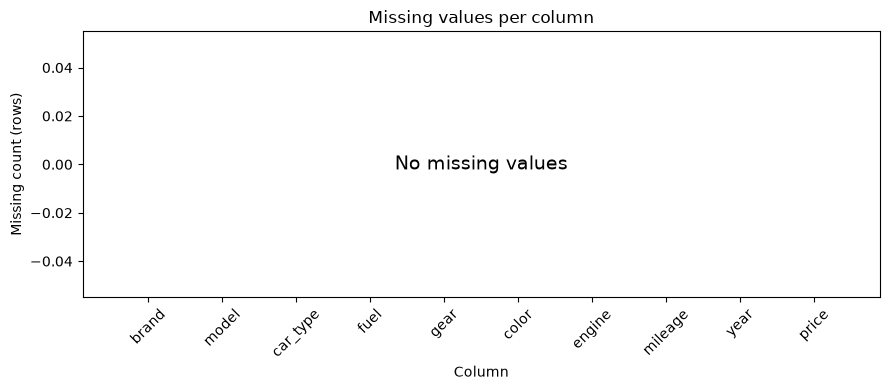

ไม่พบค่าว่าง


In [5]:
# [05] ตรวจคุณภาพ 1: ค่าว่าง
# ==================================================
# ทำอะไร: นับจำนวนและเปอร์เซ็นต์ของ "ค่าว่าง" (missing value, ช่องที่ไม่มีข้อมูล) ในทุกคอลัมน์ของ raw_df
#         แล้ววาดแท่งกราฟจำนวนค่าว่างต่อคอลัมน์
# ทำไม: ส่วนนี้ ([05]–[11]) คือการตรวจคุณภาพข้อมูลก่อนสร้างโมเดล เพราะหลัก "garbage in, garbage out"
#       คือถ้าข้อมูลเข้าไม่ดี (ว่าง ซ้ำ เป็นไปไม่ได้ กระจายแปลก) ต่อให้โมเดลดีแค่ไหน ผลลัพธ์ก็ไม่น่าเชื่อถือ
#       ค่าว่างต้องรู้ก่อนเสมอ เพราะถ้ามีอยู่ ต้องตัดสินใจว่าจะเติม ลบ หรือปล่อยไว้
#       ข้อตกลงของทั้งส่วนนี้:
#       1) ทุกเซลล์ตรวจบน raw_df ทั้งไฟล์ (ก่อนเตรียมข้อมูล) ซึ่งปลอดภัย เพราะไม่มีผลการตรวจใดถูกนำไปเลือก
#          อะไรให้โมเดลเลย (ไม่มี data leakage คือข้อมูลชุดทดสอบไม่รั่วไปมีอิทธิพลต่อการเลือกโมเดล)
#       2) ส่วนนี้ "รายงานอย่างเดียว" ไม่แก้ raw_df และไม่สร้างตัวแปรที่เซลล์อื่นต้องใช้
#          ถ้าพบปัญหา ผู้ใช้เป็นคนตัดสินใจทีหลังว่าจะทำอย่างไร ข้อมูลจึงไม่ถูกเปลี่ยนที่นี่
#          และผลของโมเดลไม่เปลี่ยน
#       3) ข้อสรุปท้ายแต่ละเซลล์ถูกคำนวณโดยโค้ด ไม่ได้พิมพ์ตายตัว
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อคอลัมน์ (10 แถว) บอกจำนวนค่าว่างและเปอร์เซ็นต์ กราฟแท่งจำนวนค่าว่างต่อคอลัมน์
#       ถ้าทุกแท่งเป็นศูนย์ บนกราฟจะมีข้อความ "No missing values" และบรรทัดสุดท้ายบอกว่าไม่พบค่าว่าง
#       ถ้ามีแท่งสูง แสดงว่าคอลัมน์นั้นมีข้อมูลหาย ควรหาสาเหตุก่อนไปต่อ
# ==================================================
print("=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===")

missing_table = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
})

print("ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว")
display(missing_table.style.format({
    "missing_count": "{:,.0f}",
    "missing_percent": "{:.2f}",
}))

total_missing = int(missing_table["missing_count"].sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["missing_count"])
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing count (rows)")
ax.tick_params(axis="x", rotation=45)
if total_missing == 0:
    ax.text(0.5, 0.5, "No missing values", transform=ax.transAxes,
            ha="center", va="center", fontsize=14)
plt.tight_layout()
plt.show()

if total_missing == 0:
    print("ไม่พบค่าว่าง")
else:
    columns_with_missing = int((missing_table["missing_count"] > 0).sum())
    print(f"พบค่าว่างรวม {total_missing:,} ค่า ใน {columns_with_missing} คอลัมน์")

=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===
ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'


,duplicate_rows,percent_of_rows
all columns,0,0.00
all except price,129,0.44
all except color,11,0.04


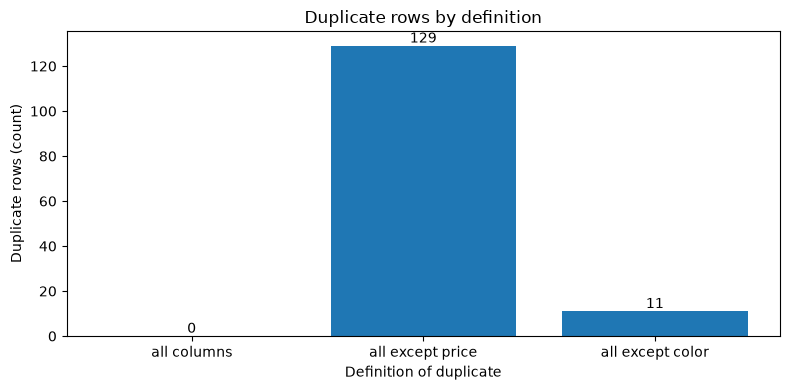

ไม่พบแถวที่ซ้ำกันทุกคอลัมน์
แถวที่ต่างกันแค่ price (ธงเตือน)   : 129 แถว
แถวที่ต่างกันแค่ color (รถคนละคัน) : 11 แถว


In [6]:
# [06] ตรวจคุณภาพ 2: แถวซ้ำ
# ==================================================
# ทำอะไร: นับแถวที่ "ซ้ำกับแถวก่อนหน้า" (ตัวสำเนาส่วนเกิน ไม่นับแถวแรกที่เจอ) ตาม 3 นิยาม
#         1) เหมือนกันทุกคอลัมน์
#         2) เหมือนกันทุกคอลัมน์ ยกเว้น price
#         3) เหมือนกันทุกคอลัมน์ ยกเว้น color
# ทำไม: กฎของโปรเจกต์นี้คือ "แถวที่ต่างกันในคอลัมน์ใดก็ตามที่ไม่ใช่ price ถือว่าเป็นรถคนละคัน"
#       ดังนั้น
#       - นิยาม 1 คือแถวซ้ำจริง ๆ (อาจเป็นข้อมูลที่ถูกบันทึกซ้ำ)
#       - นิยาม 2 คือแถวที่ทุกอย่างเหมือนกันหมดแต่ราคาต่างกัน ตามกฎอาจเป็นรถคันเดียวที่ถูกประกาศขายสองราคา
#         จึงเป็นธงเตือนคุณภาพ (quality flag) ไม่ใช่ข้อผิดพลาดที่ยืนยันแล้ว
#       - นิยาม 3 คือแถวที่ต่างกันแค่สี ตามกฎเป็นรถคนละคัน (สีต่างกัน) จึงไม่ใช่ข้อมูลซ้ำ
#         ข้อนี้เชื่อมกับหมายเหตุในเซลล์ [13] ที่อธิบายเรื่องการแบ่งข้อมูล
#       แถวซ้ำสำคัญเพราะถ้าแถวเดียวกันอยู่ทั้งชุดเทรนและชุดทดสอบ คะแนนทดสอบจะดีเกินจริง
#       เซลล์นี้รายงานอย่างเดียว ไม่ลบแถวใดเลย
# ผลที่ควรเห็น: ตารางสามแถว (นิยามละหนึ่งแถว) บอกจำนวนแถวซ้ำและเปอร์เซ็นต์ กราฟแท่งสามแท่งเขียนตัวเลขบนแท่ง
#       ตัวเลขนิยาม 2 และ 3 จะมากกว่าหรือเท่ากับนิยาม 1 เสมอ (เพราะเทียบน้อยคอลัมน์กว่า เจอซ้ำง่ายกว่า)
# ==================================================
print("=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===")

definitions = {
    "all columns": list(raw_df.columns),
    "all except price": [c for c in raw_df.columns if c != "price"],
    "all except color": [c for c in raw_df.columns if c != "color"],
}

duplicate_counts = {}
for name, columns in definitions.items():
    duplicate_counts[name] = int(raw_df.duplicated(subset=columns, keep="first").sum())

duplicate_table = pd.DataFrame({
    "duplicate_rows": pd.Series(duplicate_counts),
})
duplicate_table["percent_of_rows"] = duplicate_table["duplicate_rows"] / len(raw_df) * 100

print("ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'")
display(duplicate_table.style.format({
    "duplicate_rows": "{:,.0f}",
    "percent_of_rows": "{:.2f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(duplicate_table.index, duplicate_table["duplicate_rows"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Duplicate rows by definition")
ax.set_xlabel("Definition of duplicate")
ax.set_ylabel("Duplicate rows (count)")
plt.tight_layout()
plt.show()

if duplicate_counts["all columns"] == 0:
    print("ไม่พบแถวที่ซ้ำกันทุกคอลัมน์")
else:
    print(f"พบแถวซ้ำทุกคอลัมน์ {duplicate_counts['all columns']:,} แถว")
print(f"แถวที่ต่างกันแค่ price (ธงเตือน)   : {duplicate_counts['all except price']:,} แถว")
print(f"แถวที่ต่างกันแค่ color (รถคนละคัน) : {duplicate_counts['all except color']:,} แถว")

=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===
ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)


,rows_violating
price <= 0,0
engine <= 0,0
mileage < 0,0
year > 2026,0


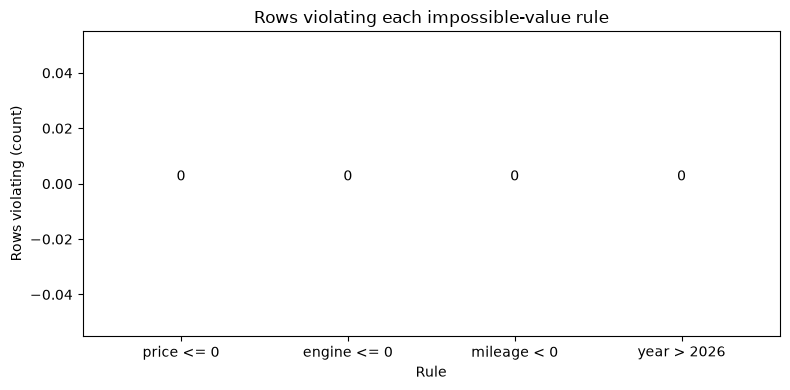

ไม่พบค่าที่เป็นไปไม่ได้


In [7]:
# [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้
# ==================================================
# ทำอะไร: นับแถวที่ฝ่าฝืนกฎ "ค่าที่เป็นไปไม่ได้ในโลกจริง" 4 ข้อ
#         1) price <= 0     ราคาขายต้องมากกว่า 0 บาท
#         2) engine <= 0    ขนาดเครื่องยนต์ (cc) ต้องมากกว่า 0
#         3) mileage < 0    เลขไมล์ติดลบไม่ได้ (ไมล์เป็น 0 ได้ เช่นรถใหม่)
#         4) year > CURRENT_YEAR   ปีของรถต้องไม่เกินปีปัจจุบัน (CURRENT_YEAR กำหนดในเซลล์ [03])
# ทำไม: ค่าที่เป็นไปไม่ได้แปลว่าข้อมูลผิดแน่นอน (เช่นกรอกผิดหรือระบบเก็บพลาด) ไม่เหมือนค่าที่แค่หายาก
#       ถ้ามีอยู่จะทำให้โมเดลเรียนรู้จากข้อมูลเท็จ ใช้เฉพาะกฎที่ตรรกะบังคับเท่านั้น
#       ไม่คิดเกณฑ์ที่ตั้งเองตามใจ เช่น "รถเก่าเกินไป" เพราะรถเก่ามากที่ราคาสูงก็มีจริง (รถคลาสสิก)
# ผลที่ควรเห็น: ตารางแต่ละกฎกับจำนวนแถวที่ฝ่าฝืน และกราฟแท่งของแต่ละกฎ
#       ถ้าทุกกฎเป็น 0 แปลว่าไม่พบค่าที่เป็นไปไม่ได้ ถ้าไม่ใช่ ควรดูแถวนั้นก่อนตัดสินใจว่าจะทำอย่างไร
#       (เซลล์นี้ไม่แก้และไม่ลบข้อมูล)
# ==================================================
print("=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===")

impossible_counts = {
    "price <= 0": int((raw_df["price"] <= 0).sum()),
    "engine <= 0": int((raw_df["engine"] <= 0).sum()),
    "mileage < 0": int((raw_df["mileage"] < 0).sum()),
    f"year > {CURRENT_YEAR}": int((raw_df["year"] > CURRENT_YEAR).sum()),
}

impossible_table = pd.DataFrame({
    "rows_violating": pd.Series(impossible_counts),
})

print("ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)")
display(impossible_table.style.format({"rows_violating": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(impossible_table.index, impossible_table["rows_violating"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Rows violating each impossible-value rule")
ax.set_xlabel("Rule")
ax.set_ylabel("Rows violating (count)")
plt.tight_layout()
plt.show()

total_impossible = sum(impossible_counts.values())
if total_impossible == 0:
    print("ไม่พบค่าที่เป็นไปไม่ได้")
else:
    print(f"พบการฝ่าฝืนกฎรวม {total_impossible:,} ครั้ง (นับซ้ำได้ถ้าแถวเดียวฝ่าฝืนหลายกฎ)")

=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===
ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3


,price,engine,mileage,year
count,"29,571","29,571","29,571","29,571"
mean,"617,473","1,912","110,627","2,018"
std,"647,018",515,"73,033",4
min,"36,000","1,000",1,"2,001"
25%,"319,000","1,500","57,500","2,016"
50%,"459,000","2,000","102,500","2,019"
75%,"699,000","2,400","155,000","2,021"
max,"13,990,000","3,000","746,754","2,026"


C:\Users\putaw\AppData\Local\Temp\ipykernel_3564\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_3564\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_3564\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_3564\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be remove

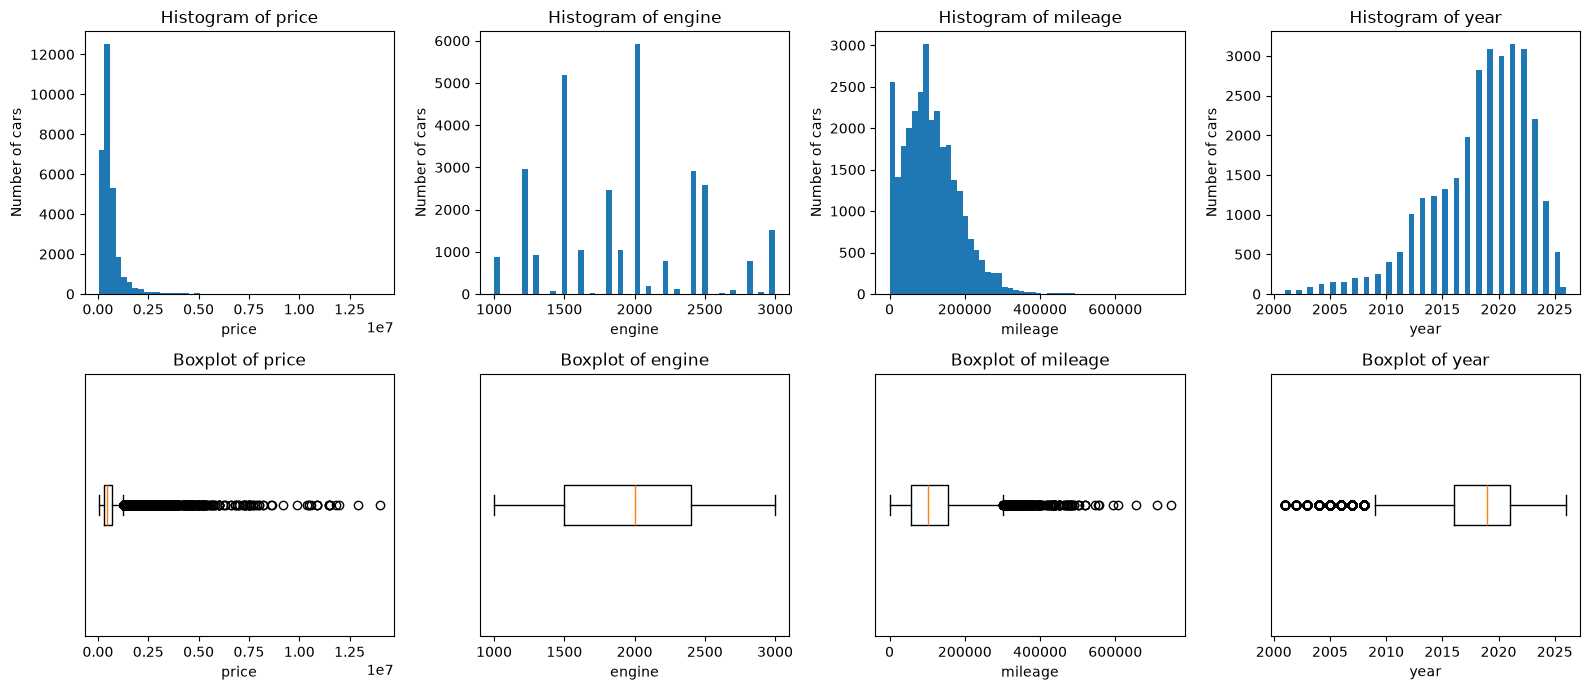

price   : ค่าความเบ้ +6.26 -> เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)
engine  : ค่าความเบ้ +0.28 -> ไม่เบ้มาก
mileage : ค่าความเบ้ +0.85 -> ไม่เบ้มาก
year    : ค่าความเบ้ -1.00 -> เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)


In [8]:
# [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข
# ==================================================
# ทำอะไร: สรุปสถิติ (describe) ของคอลัมน์ตัวเลข 4 ตัว (price, engine, mileage, year)
#         แล้ววาด histogram (แถวบน) และ boxplot (แถวล่าง) ของแต่ละตัว
# ทำไม: การดูรูปร่างการกระจายของข้อมูลช่วยให้เห็นสิ่งที่ตัวเลขสรุปไม่บอก เช่น ข้อมูลเบ้ หรือถูกตัดที่ค่าสูงสุด
# วิธีอ่านกราฟ (เป็นสิ่งที่ควรสังเกต ไม่ใช่ข้อเท็จจริงของการรันครั้งนี้):
#   - Histogram: แบ่งค่าเป็นช่วง (bins = 50 ช่วง) แท่งสูง = มีรถในช่วงราคา/ค่านั้นมาก
#   - Boxplot: กล่อง = ข้อมูลตรงกลาง 50% (จาก Q1 ถึง Q3), เส้นในกล่อง = มัธยฐาน (median คือค่ากลางเมื่อเรียงลำดับ),
#              หนวด (whiskers) = ช่วงที่ยังถือว่าปกติ, จุดนอกหนวด = ค่าที่ห่างมาก (outlier)
#   - ความเบ้ (skew): ถ้าหางยาวไปทางขวา (ส่วนใหญ่ค่าต่ำ มีบางคันแพงมาก) เรียกว่าเบ้ขวา ราคารถมักเป็นแบบนี้
#   - แท่งสูงผิดปกติที่ค่าสูงสุด: อาจหมายถึงข้อมูลถูกตัดเพดาน (capped) ตอนเก็บ เช่น ทุกคันที่แพงกว่าเพดานถูกบันทึกเป็นค่าเพดาน
# ผลที่ควรเห็น: ตารางสถิติ (จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ต่ำสุด quartile สูงสุด) และรูป 2 แถว 4 คอลัมน์
#       ตารางไม่ได้ถูกแก้ข้อมูลใด ๆ เซลล์นี้รายงานอย่างเดียว
# ==================================================
print("=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

print("ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3")
display(raw_df[numeric_check_columns].describe().style.format("{:,.0f}"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for position, column in enumerate(numeric_check_columns):
    axes[0, position].hist(raw_df[column], bins=50)
    axes[0, position].set_title(f"Histogram of {column}")
    axes[0, position].set_xlabel(column)
    axes[0, position].set_ylabel("Number of cars")
    axes[1, position].boxplot(raw_df[column], vert=False)
    axes[1, position].set_title(f"Boxplot of {column}")
    axes[1, position].set_xlabel(column)
    axes[1, position].set_yticks([])
plt.tight_layout()
plt.show()

skewness = raw_df[numeric_check_columns].skew()
for column in numeric_check_columns:
    if skewness[column] > 1:
        shape = "เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)"
    elif skewness[column] < -1:
        shape = "เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)"
    else:
        shape = "ไม่เบ้มาก"
    print(f"{column:<8}: ค่าความเบ้ {skewness[column]:+.2f} -> {shape}")

=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===
ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว


column,q1,q3,iqr,lower_fence,upper_fence,below,above,outlier_percent,outliers
price,"319,000","699,000","380,000","-251,000","1,269,000",0,"2,222",7.51,"2,222"
engine,"1,500","2,400",900,150,"3,750",0,0,0.00,0
mileage,"57,500","155,000","97,500","-88,750","301,250",0,326,1.10,326
year,"2,016","2,021",5,"2,008","2,028","1,022",0,3.46,"1,022"


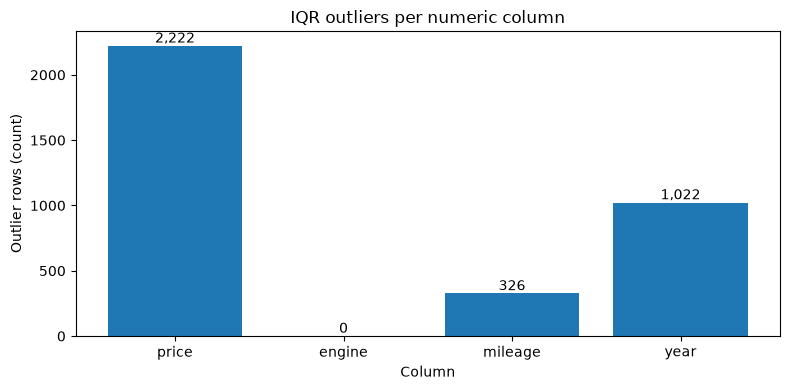

พบค่านอกรั้ว IQR รวม 3,570 ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)


In [9]:
# [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR)
# ==================================================
# ทำอะไร: หาค่าผิดปกติ (outlier คือค่าที่ห่างจากส่วนใหญ่มาก) ของคอลัมน์ตัวเลขแต่ละตัวด้วยกฎ IQR ของ Tukey
#         ขั้นตอน: หา Q1 (ค่าที่ 25% ของข้อมูลต่ำกว่า) และ Q3 (ค่าที่ 75%)
#                  IQR = Q3 - Q1 (ความกว้างของข้อมูลตรงกลาง 50%)
#                  รั้วล่าง = Q1 - 1.5 x IQR, รั้วบน = Q3 + 1.5 x IQR
#                  ค่าที่ต่ำกว่ารั้วล่างหรือสูงกว่ารั้วบนนับเป็น outlier
# ทำไม: 1.5 เป็นค่าที่ John Tukey เสนอไว้เป็นธรรมเนียมปฏิบัติ (convention) ไม่ใช่กฎธรรมชาติ
#       ต้องระวังว่า outlier ไม่ได้แปลว่าข้อมูลผิดเสมอไป รถแพงมากมีอยู่จริง จึงเป็นข้อมูลจริงที่ควรเก็บไว้
#       XGBoost ประกอบด้วยต้นไม้ตัดสินใจ (decision tree) หลายต้น แต่ละต้นแบ่งข้อมูลด้วยลำดับ (มากกว่า/น้อยกว่าเกณฑ์)
#       จึงไม่สนใจว่าค่าฟีเจอร์ที่สุดโต่งนั้นสุดโต่งแค่ไหน ค่าฟีเจอร์ที่สุดโต่งจึงกระทบโมเดลน้อย
#       (ต่างจากโมเดลเชิงเส้นที่ถูกลากง่าย) แต่ราคา (ค่าที่ทาย) ที่สุดโต่งยังมีผล เพราะ XGBoost ในโน้ตบุ๊คนี้
#       เรียนรู้จากความผิดพลาดยกกำลังสอง รถราคาสูงมากที่ทายพลาดจึงดึงต้นไม้ต้นถัดไปได้มากกว่าคันอื่น
#       เซลล์นี้ไม่ลบหรือแก้ค่าใดเลย รายงานอย่างเดียว
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (Q1, Q3, IQR, รั้วล่าง/บน, จำนวนที่ต่ำกว่า/สูงกว่า, เปอร์เซ็นต์ของแถวทั้งหมด)
#       และกราฟแท่งจำนวน outlier ต่อคอลัมน์ ถ้าแท่งสูงให้ดูว่าเป็นค่าจริงที่หายากหรือสัญญาณข้อมูลผิด
# ==================================================
print("=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

rows = []
for column in numeric_check_columns:
    q1 = raw_df[column].quantile(0.25)
    q3 = raw_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    below = int((raw_df[column] < lower_fence).sum())
    above = int((raw_df[column] > upper_fence).sum())
    rows.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below": below,
        "above": above,
        "outlier_percent": (below + above) / len(raw_df) * 100,
    })

outlier_table = pd.DataFrame(rows)
outlier_table["outliers"] = outlier_table["below"] + outlier_table["above"]

print("ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว")
display(outlier_table.style.hide(axis="index").format({
    "q1": "{:,.0f}",
    "q3": "{:,.0f}",
    "iqr": "{:,.0f}",
    "lower_fence": "{:,.0f}",
    "upper_fence": "{:,.0f}",
    "below": "{:,.0f}",
    "above": "{:,.0f}",
    "outlier_percent": "{:.2f}",
    "outliers": "{:,.0f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(outlier_table["column"], outlier_table["outliers"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("IQR outliers per numeric column")
ax.set_xlabel("Column")
ax.set_ylabel("Outlier rows (count)")
plt.tight_layout()
plt.show()

total_outliers = int(outlier_table["outliers"].sum())
if total_outliers == 0:
    print("ไม่พบค่าผิดปกติตามกฎ IQR")
else:
    print(f"พบค่านอกรั้ว IQR รวม {total_outliers:,} ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)")

=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===
ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน


column,levels,most_common,most_common_share_percent,smallest_level_rows
brand,42,TOYOTA,30.68,1
model,450,D-MAX,4.58,1
car_type,5,Sedan,33.21,"1,720"
fuel,3,Benzine,57.00,"4,237"
gear,2,Automatic,89.75,"3,032"
color,21,White,33.48,1


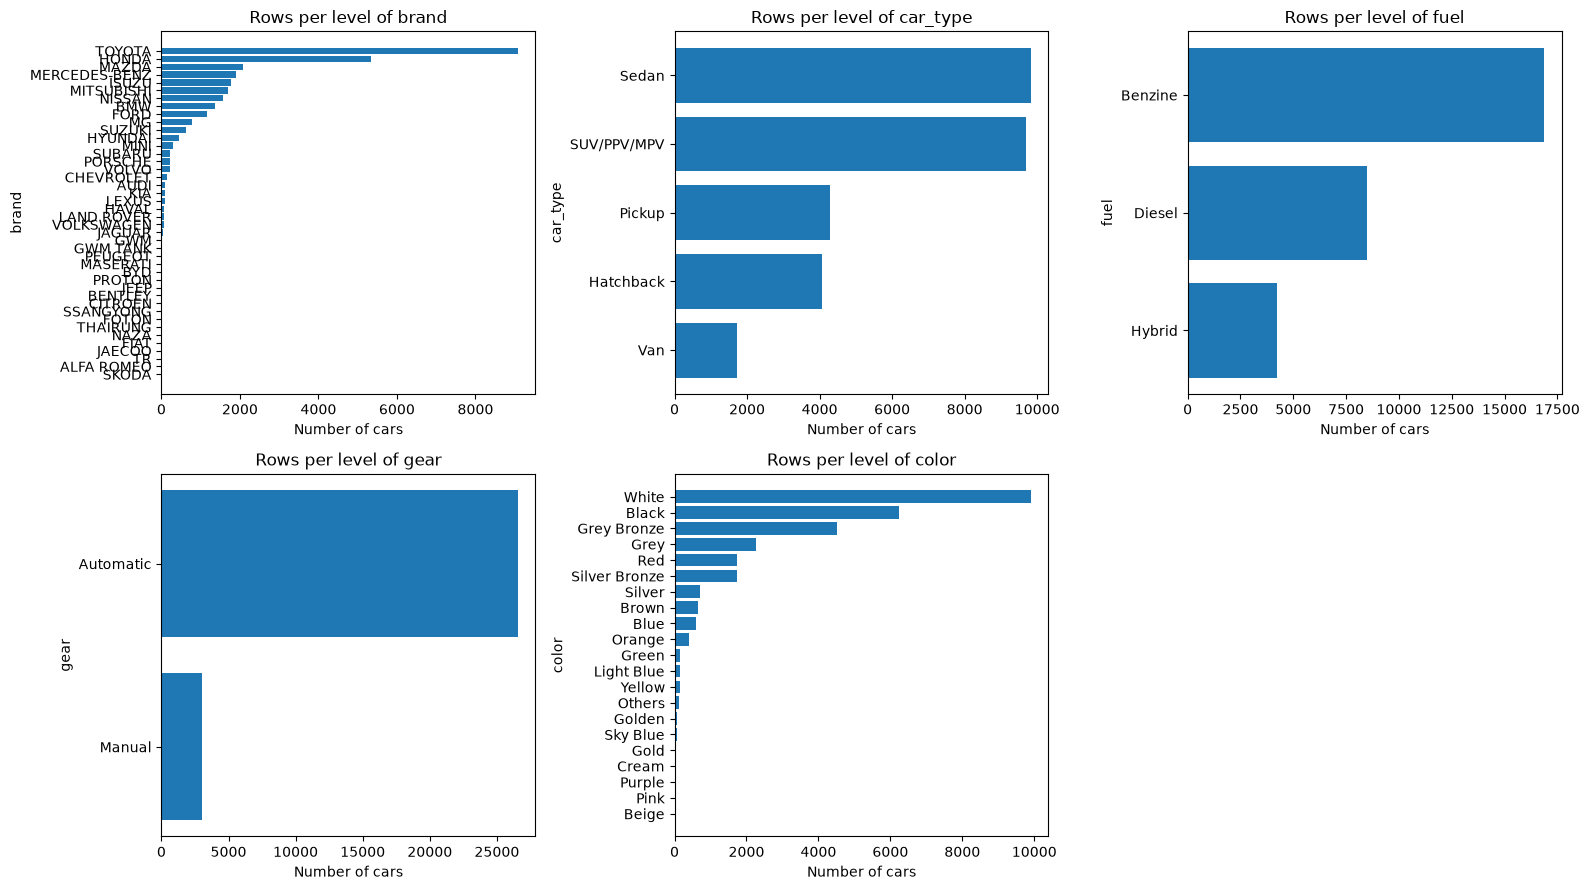

ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี 1 แถว


In [10]:
# [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม
# ==================================================
# ทำอะไร: ดูคอลัมน์ที่เป็นกลุ่ม/ประเภท (categorical) 6 ตัว: brand, model, car_type, fuel, gear, color
#         นับจำนวนระดับ (level คือค่าที่แตกต่างกัน เช่น fuel มี เบนซิน/ดีเซล/...) ระดับที่พบบ่อยที่สุดและสัดส่วนของมัน
#         แล้ววาดแท่งแนวนอนจำนวนแถวต่อระดับ ของ brand, car_type, fuel, gear, color
# ทำไม: ระดับที่หายาก (rare level คือมีแถวน้อยมาก) สร้างปัญหาสองอย่าง
#       1) One-hot encoding (แปลงแต่ละระดับเป็นคอลัมน์ 0/1) จะได้คอลัมน์ที่เกือบทั้งหมดเป็น 0 และเรียนรู้อะไรไม่ได้มาก
#       2) การแบ่งข้อมูลและการแบ่งโหนดของต้นไม้ (XGBoost คือต้นไม้หลายต้น):
#          ถ้าระดับหนึ่งมีไม่กี่แถว อาจไม่มีตัวอย่างในชุดทดสอบ หรือต้นไม้
#          แบ่งตามระดับนั้นแล้วได้ใบ (leaf) เล็กจนไม่น่าเชื่อถือ
#       คอลัมน์ model มีหลายระดับเกินกว่าจะวาดเป็นกราฟแท่ง เซลล์ [11] ดูเรื่องนี้แยกต่างหาก
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (จำนวนระดับ ระดับที่พบมากสุด สัดส่วน) และรูป 2x3 ช่อง ใช้ 5 ช่อง
#       ช่องที่หกถูกลบทิ้ง ในกราฟ แท่งสั้นมาก ๆ คือระดับหายาก
# ==================================================
print("=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===")

categorical_check_columns = ["brand", "model", "car_type", "fuel", "gear", "color"]

rows = []
for column in categorical_check_columns:
    counts = raw_df[column].value_counts()
    rows.append({
        "column": column,
        "levels": len(counts),
        "most_common": counts.index[0],
        "most_common_share_percent": counts.iloc[0] / len(raw_df) * 100,
        "smallest_level_rows": counts.min(),
    })
level_table = pd.DataFrame(rows)

print("ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน")
display(level_table.style.hide(axis="index").format({
    "levels": "{:,.0f}",
    "most_common_share_percent": "{:.2f}",
    "smallest_level_rows": "{:,.0f}",
}))

plot_columns = ["brand", "car_type", "fuel", "gear", "color"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
flat_axes = axes.flatten()
for position, column in enumerate(plot_columns):
    counts = raw_df[column].value_counts().sort_values()
    flat_axes[position].barh(counts.index.astype(str), counts.to_numpy())
    flat_axes[position].set_title(f"Rows per level of {column}")
    flat_axes[position].set_xlabel("Number of cars")
    flat_axes[position].set_ylabel(column)
fig.delaxes(flat_axes[5])
plt.tight_layout()
plt.show()

smallest_level_rows = level_table["smallest_level_rows"].min()
print(f"ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี {smallest_level_rows:,} แถว")

=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===
จำนวนรุ่น (brand|model) : 451
แถวต่อรุ่น ต่ำสุด       : 1
แถวต่อรุ่น มัธยฐาน      : 8
แถวต่อรุ่น สูงสุด       : 1,353
คู่ brand|model ที่มีแถวน้อยกว่า 10: 242
คู่ brand|model ที่มีแถวน้อยกว่า 50: 357
ชื่อ model ที่มีแถวน้อยกว่า 10: 241
ชื่อ model ที่มีแถวน้อยกว่า 50: 356


brand,model,rows
ALFA ROMEO,156,1
AUDI,A1,1
AUDI,A3,1
VOLVO,S40,1
VOLVO,C30,1
BMW,750E,1
BMW,ACTIVEHYBRID 7 L,1
MERCEDES-BENZ,V220,1
MERCEDES-BENZ,V250,1
MG,MG,1


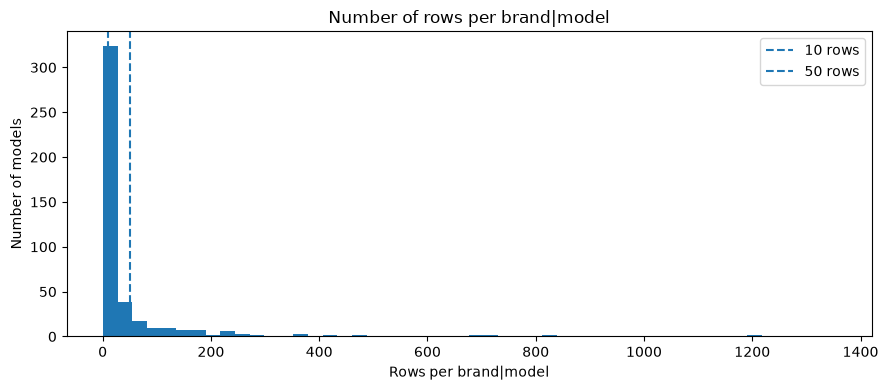

In [11]:
# [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น
# ==================================================
# ทำอะไร: รายงานจำนวนแถวต่อรุ่นและจำนวนรุ่นที่ต่ำกว่า 10 และ 50 แถว
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ข้อมูลชุดนี้ไม่มีข้อกำหนดจำนวนแถวขั้นต่ำต่อรุ่น ไม่ลบแถวในเซลล์ตรวจคุณภาพ
# ==================================================
print("=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===")

rows_per_model = raw_df.groupby(["brand", "model"]).size()
print(f"จำนวนรุ่น (brand|model) : {len(rows_per_model):,}")
print(f"แถวต่อรุ่น ต่ำสุด       : {rows_per_model.min():,.0f}")
print(f"แถวต่อรุ่น มัธยฐาน      : {rows_per_model.median():,.0f}")
print(f"แถวต่อรุ่น สูงสุด       : {rows_per_model.max():,.0f}")
print(f"คู่ brand|model ที่มีแถวน้อยกว่า 10: {(rows_per_model < 10).sum():,}")
print(f"คู่ brand|model ที่มีแถวน้อยกว่า 50: {(rows_per_model < 50).sum():,}")
model_counts_only = raw_df.groupby("model").size()
print(f"ชื่อ model ที่มีแถวน้อยกว่า 10: {(model_counts_only < 10).sum():,}")
print(f"ชื่อ model ที่มีแถวน้อยกว่า 50: {(model_counts_only < 50).sum():,}")
smallest_models = rows_per_model.sort_values().head(10).rename("rows").reset_index()
display(smallest_models.style.hide(axis="index").format({"rows": "{:,.0f}"}))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rows_per_model, bins=50)
for threshold_rows in [10, 50]:
    ax.axvline(threshold_rows, linestyle="--", label=f"{threshold_rows} rows")
ax.set(title="Number of rows per brand|model", xlabel="Rows per brand|model", ylabel="Number of models")
ax.legend()
plt.tight_layout()
plt.show()


In [12]:
# [12] เตรียมข้อมูล: car_age และตัดคอลัมน์
# ==================================================
# ทำอะไร: ทำสำเนาของ raw_df เป็น df แล้ว
#         ใช้กฎ v3 กรองอายุและรวมชื่อรุ่นก่อน โดยเลือกชื่อเดิมที่พบบ่อยที่สุดในแต่ละกลุ่ม
#         (1) สร้างคอลัมน์ car_age = CURRENT_YEAR - year (อายุรถเป็นปี)
#         (2) ตัดคอลัมน์ year และ color ทิ้ง
#         (3) ตรวจว่าคอลัมน์ที่ใช้ทั้งหมดไม่มีค่าว่าง
# ทำไม:
#   - ตัด year เพราะ car_age บอกข้อมูลเดียวกันอยู่แล้ว (ปีที่ผลิตมากขึ้น = อายุน้อยลง)
#     เก็บไว้ทั้งสองจะซ้ำซ้อน
#   - ตัด color เพราะเป็นการตัดสินใจของโปรเจกต์ที่จะไม่ใช้สีเป็น feature
#     (ผลของการตัดนี้ต่อแถวที่ค่าเหมือนกันข้ามชุด อธิบายไว้ในเซลล์ [13])
#   - สร้าง df จาก raw_df.copy() ทุกครั้ง เพื่อให้รันเซลล์นี้ซ้ำได้ ไม่แก้ raw_df
#     ถ้าแก้ df ตรงๆ รอบที่สองจะไม่มีคอลัมน์ year ให้คำนวณแล้ว
#   - ไม่เปลี่ยนชื่อคอลัมน์ engine, fuel, gear เป็น engine_capacity, fuel_type, gear_type
#     ที่ต้นฉบับทำ เพราะผู้ใช้สั่งให้ใช้ชื่อตามไฟล์ข้อมูล การเปลี่ยนชื่อไม่มีผลกับตัวเลขของโมเดล
#     (ทดสอบแล้วได้ R² เท่าเดิมทุกหลัก) ต่างกันแค่ชื่อที่แสดงใน features และ RESULT_JSON
#     ถ้าจะเทียบกับไฟล์โมเดล V4 เดิม (V4_*_min50.json) ต้องจับคู่ชื่อเอง
# ผลที่ควรเห็น: ขนาดตาราง df และรายชื่อคอลัมน์ (ต้องไม่มี year และ color แต่มี car_age)
# ==================================================
print("=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===")

df = raw_df.copy()

before_age = len(df)
df = df.loc[(CURRENT_YEAR - df["year"]) <= MAX_CAR_AGE].copy()
print(f"ขั้นกรองอายุ: ลบ {before_age - len(df):,} แถว เหลือ {len(df):,} แถว")
before_normalize = len(df)
original_models = df["model"].copy()
model_key_clean = df["model"].str.upper().str.replace("[^A-Z0-9]", "", regex=True).replace(MODEL_ALIASES)
best_name = df.groupby(model_key_clean)["model"].agg(lambda names: names.value_counts().index[0])
df["model"] = model_key_clean.map(best_name)
print(f"ขั้นรวมชื่อรุ่น: ลบ {before_normalize - len(df):,} แถว เปลี่ยนชื่อ {(original_models != df['model']).sum():,} แถว")
print(f"หลังรวมชื่อรุ่น: {df.groupby(['brand', 'model']).ngroups:,} คู่ brand|model")
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns=["year", "color"])
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()

print(f"ขนาดตาราง df : {df.shape[0]:,} แถว x {df.shape[1]:,} คอลัมน์")
print(f"คอลัมน์      : {list(df.columns)}")

=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===
ขั้นกรองอายุ: ลบ 0 แถว เหลือ 29,571 แถว
ขั้นรวมชื่อรุ่น: ลบ 0 แถว เปลี่ยนชื่อ 287 แถว
หลังรวมชื่อรุ่น: 445 คู่ brand|model
ขนาดตาราง df : 29,571 แถว x 9 คอลัมน์
คอลัมน์      : ['brand', 'model', 'car_type', 'fuel', 'gear', 'engine', 'mileage', 'price', 'car_age']


In [13]:
# [13] แบ่ง train / validation / test
# ==================================================
# ทำอะไร: บังคับหนึ่งแถวต่อ brand|model เข้า train แล้วสุ่มเติมโควตา train และแบ่ง val/test ครึ่งต่อครึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: มี 242 ชื่อรุ่นที่มีน้อยกว่า 10 แถว จึงแบ่งแบบ stratified ไม่ได้; ใช้กฎ v3 ด้วย SEED เดิม
# ==================================================
print("=== [13] แบ่ง train / validation / test ===")

model_key = df["brand"] + "|" + df["model"]
forced = df.groupby(["brand", "model"]).sample(n=1, random_state=SEED)
rest = df.drop(forced.index)
n_train_left = round(TRAIN_SIZE * len(df)) - len(forced)
train_rest, temp = train_test_split(rest, train_size=n_train_left, random_state=SEED)
train = pd.concat([forced, train_rest])
val, test = train_test_split(temp, test_size=0.5, random_state=SEED)

split_table = pd.DataFrame({
    "ชุด": ["train", "validation", "test"],
    "แถว": [len(train), len(val), len(test)],
    "สัดส่วน (%)": [100 * len(part) / len(df) for part in (train, val, test)],
    "จำนวนรุ่น": [model_key.loc[part.index].nunique() for part in (train, val, test)],
})
print("อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ")
display(
    split_table.style
    .format({"แถว": "{:,.0f}", "สัดส่วน (%)": "{:.2f}", "จำนวนรุ่น": "{:,.0f}"})
    .hide(axis="index")
)


=== [13] แบ่ง train / validation / test ===
อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ


ชุด,แถว,สัดส่วน (%),จำนวนรุ่น
train,"23,657",80.00,445
validation,"2,957",10.00,232
test,"2,957",10.00,246


In [14]:
# [14] สร้าง 5 fold
# ==================================================
# ทำอะไร: แบ่งชุด train เป็น N_FOLDS ส่วน (fold) ด้วย KFold เก็บเป็นรายการ folds
#         แต่ละสมาชิกคือคู่ (แถวที่ใช้สอน, แถวที่ใช้ตรวจ)
# ทำไม:
#   - K-fold cross-validation: แบ่ง train เป็น K ส่วนเท่าๆ กัน แล้วผลัดกันเอา 1 ส่วนเป็นชุดตรวจ
#     อีก K-1 ส่วนเป็นชุดสอน ทำ K รอบ แล้วเฉลี่ยคะแนน ได้ค่าที่เชื่อถือกว่าการตรวจรอบเดียว
#     และไม่ต้องแตะ validation / test
#   - สร้าง folds ครั้งเดียวแล้วให้ทุกขั้นตอนถัดไปใช้ร่วมกัน ทุกการเปรียบเทียบจึงใช้แถวชุดเดียวกัน
#     ผลต่างที่เห็นมาจากตัวเลือกที่เทียบจริง ไม่ใช่จากการแบ่ง fold ที่ต่างกัน
#   - shuffle=True สลับลำดับแถวก่อนแบ่ง เพราะข้อมูลอาจเรียงตามยี่ห้อหรือราคา
#     การแบ่งตามลำดับจะทำให้ fold ไม่เป็นตัวแทนของทั้งชุด
#     และใช้ random_state=SEED ให้สลับแล้วได้ผลเดิมทุกครั้ง
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold บอกจำนวนแถวที่ใช้สอนและแถวที่ใช้ตรวจ
#       ผลรวมสองคอลัมน์ในแต่ละแถวเท่ากับจำนวนแถวของ train
# ข้อควรระวัง: validation และ test ไม่ถูกใช้จนถึงขั้นวัดผลสุดท้าย
# ==================================================
print("=== [14] สร้าง 5 fold ===")

folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))

fold_rows = []
for fold_number, (train_index, valid_index) in enumerate(folds, start=1):
    fold_rows.append({
        "fold": fold_number,
        "แถวสำหรับสอน": len(train_index),
        "แถวสำหรับตรวจ": len(valid_index),
    })
fold_table = pd.DataFrame(fold_rows)
print("อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)")
display(
    fold_table.style
    .format({"fold": "{:.0f}", "แถวสำหรับสอน": "{:,.0f}", "แถวสำหรับตรวจ": "{:,.0f}"})
    .hide(axis="index")
)

=== [14] สร้าง 5 fold ===
อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)


fold,แถวสำหรับสอน,แถวสำหรับตรวจ
1,"18,925","4,732"
2,"18,925","4,732"
3,"18,926","4,731"
4,"18,926","4,731"
5,"18,926","4,731"


In [15]:
# [15] ฟังก์ชันวัดความสัมพันธ์
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน 2 ตัวไว้วัดว่าตัวแปร 2 ตัว "สัมพันธ์กัน" มากแค่ไหน
#   - cramers_v(x, y)              : ใช้กับตัวแปรหมวดหมู่ 2 ตัว (เช่น brand กับ model)
#   - correlation_ratio(cats, vals): ใช้กับตัวแปรหมวดหมู่ 1 ตัว กับตัวเลข 1 ตัว (เช่น brand กับ price)
#   ส่วนตัวเลขกับตัวเลขใช้ Spearman ของ pandas ได้เลย ไม่ต้องสร้างฟังก์ชันเอง
# ทำไม: ข้อมูลรถมีทั้งตัวเลข (engine, mileage, car_age, price) และหมวดหมู่ (brand, model,
#   car_type, fuel, gear) การวัดแบบเดียวไม่เหมาะกับทุกคู่
#   เช่น ค่าสหสัมพันธ์ปกติ (Pearson) ใช้กับ "brand" ไม่ได้เพราะ brand ไม่ใช่ตัวเลข
#   จึงต้องเลือกตัววัดให้ตรงกับชนิดของตัวแปรแต่ละคู่:
#     1) ตัวเลข-ตัวเลข   : Spearman  = สหสัมพันธ์แบบเรียงอันดับ (rank) ค่าจริง -1..1
#                          เซลล์ [16] ใช้ค่าสัมบูรณ์ เพื่อให้อยู่สเกล 0..1 เหมือนตัววัดอื่น
#     2) หมวดหมู่-หมวดหมู่ : Cramér's V = ปรับจากค่าไคสแควร์ (chi-square) ของตารางไขว้
#                          ให้อยู่ในช่วง 0..1
#     3) หมวดหมู่-ตัวเลข  : η (อีตา, correlation ratio)
#                          = รากของ (ความแปรปรวนระหว่างกลุ่ม / ความแปรปรวนรวม)
#                          บอกว่าค่าเฉลี่ยของแต่ละหมวด อธิบายความผันผวนของตัวเลขได้กี่ส่วน
#   ทั้งสามตัววัดตีความเหมือนกัน: 0 = ไม่สัมพันธ์กันเลย, 1 = สัมพันธ์กันสมบูรณ์
#   (รู้ค่าของตัวหนึ่งก็บอกอีกตัวได้แน่นอน)
# ผลที่ควรเห็น: พิมพ์ข้อความว่าสร้างฟังก์ชันแล้ว และผ่านการเช็กตัวเอง (assert) 2 ข้อ
# ข้อควรระวัง: สามตัววัดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ
#   เซลล์นี้ใช้ train เท่านั้น (เช็กตัวเองกับ train) ไม่แตะ val และ test
# ==================================================
print("=== [15] ฟังก์ชันวัดความสัมพันธ์ ===")


def cramers_v(x, y):
    """Cramér's V ของตัวแปรหมวดหมู่ 2 ตัว (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    smaller_side = min(table.shape[0], table.shape[1])
    return np.sqrt(chi2 / (n * (smaller_side - 1)))


def correlation_ratio(categories, values):
    """η ของตัวแปรหมวดหมู่ (Series) กับตัวเลข (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    group_means = values.groupby(categories).transform("mean")
    overall_mean = values.mean()
    between_group = ((group_means - overall_mean) ** 2).sum()
    total = ((values - overall_mean) ** 2).sum()
    return np.sqrt(between_group / total)


# เช็กตัวเอง: ตัวแปรเทียบกับตัวมันเอง ต้องได้ 1
assert abs(cramers_v(train["brand"], train["brand"]) - 1) < 1e-9

# ค่าที่ขึ้นกับ fuel อย่างเดียว (เลขรหัสของแต่ละชนิดเชื้อเพลิง) ต้องได้ η = 1
fuel_codes = {level: code for code, level in enumerate(train["fuel"].unique())}
values_from_fuel = train["fuel"].map(fuel_codes)
assert abs(correlation_ratio(train["fuel"], values_from_fuel) - 1) < 1e-9

print("สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว")
print("เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1")

=== [15] ฟังก์ชันวัดความสัมพันธ์ ===
สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว
เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1


=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===


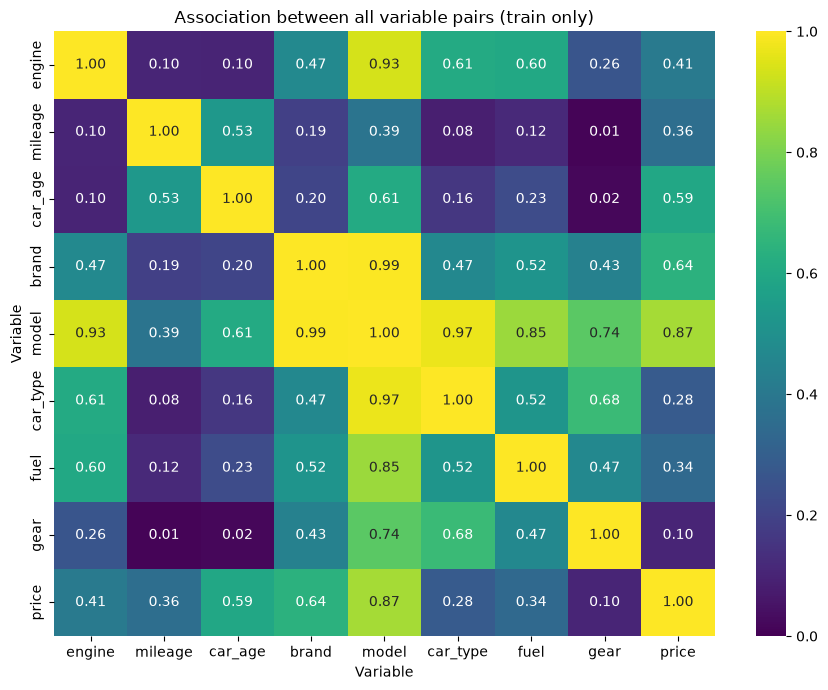

ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)


variable 1,variable 2,method,value
brand,model,Cramér's V,0.9932
model,car_type,Cramér's V,0.9711
engine,model,η,0.9343
model,price,η,0.8656
model,fuel,Cramér's V,0.8505
model,gear,Cramér's V,0.7437
car_type,gear,Cramér's V,0.6783
brand,price,η,0.6399
car_age,model,η,0.6086
engine,car_type,η,0.6072


In [16]:
# [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9)
# ==================================================
# ทำอะไร: วัดความสัมพันธ์ของตัวแปรทุกคู่ใน train (9 ตัว = 8 ฟีเจอร์ที่โมเดลใช้ + price
#   ซึ่งเป็นค่าที่จะทำนาย ได้ 36 คู่) แล้วสรุปเป็นตาราง 9x9 (association_matrix)
#   วาดเป็น heatmap (แผนที่สี) และพิมพ์ตาราง 36 คู่เรียงจากสัมพันธ์มากไปน้อย
#   วิธีวัดเลือกตามชนิดของคู่ (อธิบายไว้ที่เซลล์ [15]):
#     ตัวเลข-ตัวเลข   -> |Spearman| (ค่าสัมบูรณ์ ตัดเครื่องหมายทิ้งให้อยู่ช่วง 0..1)
#     หมวดหมู่-หมวดหมู่ -> Cramér's V
#     หมวดหมู่-ตัวเลข  -> η (correlation ratio)
#   เส้นทแยงมุมเป็น 1 เสมอ (ตัวแปรเทียบกับตัวเอง) แต่ละคู่คำนวณครั้งเดียวแล้วเติมทั้ง 2 ฝั่ง
# ทำไม: ก่อนสร้างโมเดล ควรรู้ว่าฟีเจอร์ไหนเกี่ยวข้องกับ price มาก และฟีเจอร์ไหนซ้ำซ้อนกันเอง
#   ใช้ train เท่านั้น เพราะ val และ test ต้องเป็นข้อมูลที่ไม่เคยเห็น
#   ถ้าเอาไปคำนวณด้วย จะเท่ากับแอบดูคำตอบก่อนวัดผล (data leakage)
# ผลที่ควรเห็น: heatmap 9x9 ยิ่งสีสว่าง (ใกล้ 1) ยิ่งสัมพันธ์กันมาก แล้วตาราง 36 คู่
#   วิธีอ่าน:
#     - แถวหรือคอลัมน์ของ price บอกว่าฟีเจอร์ไหนสัมพันธ์กับราคามากที่สุด
#     - คู่ model กับ brand จะใกล้ 1 เป็นเรื่องปกติ เพราะรุ่นหนึ่งสังกัดยี่ห้อเดียว
#       ไม่ใช่ข้อมูลผิดพลาด
#     - ฟีเจอร์สองตัวสัมพันธ์กันสูง ไม่ได้ทำให้โมเดลต้นไม้อย่าง XGBoost ทำนายแย่ลง
#       แต่ทำให้บอกยากว่าฟีเจอร์ไหน "สำคัญ" จริง เพราะทั้งคู่ให้ข้อมูลซ้ำกัน
#     - ความสัมพันธ์ไม่ใช่เหตุและผล (association is not causation)
#       เช่น รถอายุมากราคาต่ำ ไม่ได้แปลว่าอายุเป็นตัวกำหนดราคาเพียงอย่างเดียว
# ข้อควรระวัง: ตัววัด 3 ชนิดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ
#   จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ เทียบในชนิดเดียวกันแม่นกว่า
# ==================================================
print("=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===")

variables = NUM_COLS + CAT_COLS + ["price"]
numeric_variables = NUM_COLS + ["price"]

association_matrix = pd.DataFrame(np.eye(len(variables)), index=variables, columns=variables)
pair_rows = []
for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        first = variables[i]
        second = variables[j]
        first_is_numeric = first in numeric_variables
        second_is_numeric = second in numeric_variables
        if first_is_numeric and second_is_numeric:
            method = "Spearman"
            value = abs(train[first].corr(train[second], method="spearman"))
        elif not first_is_numeric and not second_is_numeric:
            method = "Cramér's V"
            value = cramers_v(train[first], train[second])
        elif first_is_numeric:
            method = "η"
            value = correlation_ratio(train[second], train[first])
        else:
            method = "η"
            value = correlation_ratio(train[first], train[second])
        association_matrix.loc[first, second] = value
        association_matrix.loc[second, first] = value
        pair_rows.append(
            {"variable 1": first, "variable 2": second, "method": method, "value": value}
        )

plt.figure(figsize=(9, 7))
sns.heatmap(association_matrix, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="viridis")
plt.title("Association between all variable pairs (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

pair_table = pd.DataFrame(pair_rows).sort_values("value", ascending=False)
print("ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)")
display(pair_table.style.format({"value": "{:.4f}"}).hide(axis="index"))

=== [17] Spearman ของตัวแปรตัวเลข ===


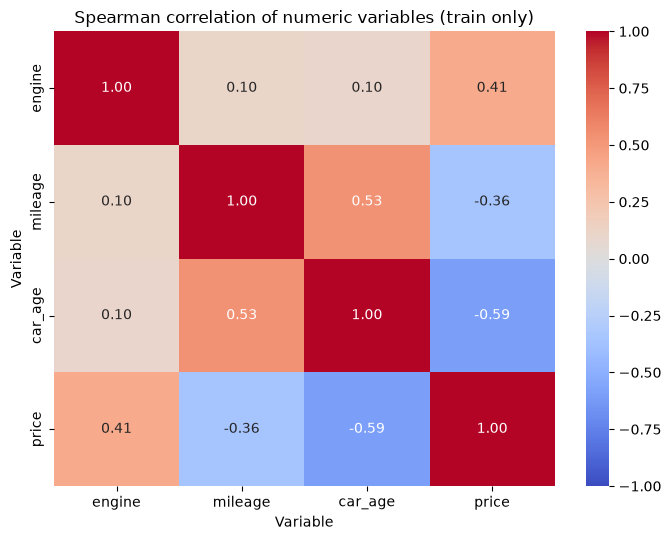

ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)


,engine,mileage,car_age,price
engine,1.0000,0.1025,0.1006,0.4066
mileage,0.1025,1.0000,0.5345,-0.3560
car_age,0.1006,0.5345,1.0000,-0.5948
price,0.4066,-0.3560,-0.5948,1.0000


In [17]:
# [17] Spearman ของตัวแปรตัวเลข
# ==================================================
# ทำอะไร: คำนวณ Spearman ของตัวแปรตัวเลข 4 ตัว (engine, mileage, car_age, price) ใน train
#   แล้ววาด heatmap และแสดงตาราง ต่างจากเซลล์ [16] ตรงที่เก็บเครื่องหมายบวก/ลบไว้ (ช่วง -1..1)
# ทำไม: เครื่องหมายบอกทิศทางที่เซลล์ [16] (ใช้ค่าสัมบูรณ์) มองไม่เห็น
#   Spearman คือสหสัมพันธ์ของ "อันดับ" (rank) ของข้อมูล ไม่ใช่ค่าจริง จึงเลือกใช้แทน Pearson เพราะ
#     - ทนต่อค่าผิดปกติ (outlier) เช่น รถราคาสูงมากไม่กี่คัน Pearson จะถูกดึงไปมาก
#     - จับความสัมพันธ์ที่ไม่เป็นเส้นตรงแต่ไปทางเดียวกันได้ (monotonic)
#       เช่น ราคาลดลงเรื่อย ๆ เมื่อเลขไมล์เพิ่ม แม้ไม่ลดเป็นเส้นตรง
# ผลที่ควรเห็น: heatmap สีแดง-น้ำเงิน (coolwarm) พร้อมตัวเลขในช่อง แล้วตารางตัวเลขชุดเดียวกัน
#   วิธีอ่านเครื่องหมาย:
#     - บวก (สีแดง) = สองตัวนี้เพิ่มไปด้วยกัน
#     - ลบ (สีน้ำเงิน) = ตัวหนึ่งเพิ่มขณะที่อีกตัวลด
#     - ใกล้ 0 (สีขาว) = ไม่มีแนวโน้มทางเดียวกันชัดเจน
#   สิ่งที่ควรดู: (1) แถว price ว่าตัวไหนสัมพันธ์กับราคามากและทิศทางใด
#   (2) ฟีเจอร์ตัวเลขสองตัวที่สัมพันธ์กันเองสูง (เช่น car_age กับ mileage มักไปด้วยกัน)
#   ซึ่งหมายความว่าให้ข้อมูลซ้ำกันบางส่วน ควรเทียบกับผลในเซลล์ [16]
# ข้อควรระวัง: สัมพันธ์ไม่ใช่เหตุและผล และใช้ train เท่านั้นเหมือนเซลล์ [16]
# ==================================================
print("=== [17] Spearman ของตัวแปรตัวเลข ===")

spearman_table = train[NUM_COLS + ["price"]].corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(spearman_table, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlation of numeric variables (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

print("ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)")
display(spearman_table.style.format("{:.4f}"))

In [18]:
# [18] รายชื่อฟีเจอร์
# ==================================================
# ทำอะไร: ประกาศตัวแปร features = รายชื่อคอลัมน์ทั้งหมดที่จะป้อนให้โมเดลใช้ทายราคา
#         "ฟีเจอร์ (feature)" คือคอลัมน์ข้อมูลที่โมเดลใช้เป็นเบาะแสในการทาย
#         เช่น ปีรถ เลขไมล์ ยี่ห้อ ส่วน "ราคา" คือคำตอบที่โมเดลต้องทาย จึงไม่นับเป็นฟีเจอร์
#         ในที่นี้ใช้ NUM_COLS (ตัวเลข: engine, mileage, car_age) รวมกับ CAT_COLS
#         (หมวดหมู่: brand, model, car_type, fuel, gear) จากเซลล์ [03] รวม 8 ตัว
# ทำไม: เวอร์ชันนี้ตัดขั้น "คัดเลือกฟีเจอร์" ออกแล้ว ใช้ทุกตัวเลย เหตุผลคือ
#         1) ในโน้ตบุ๊ค Decision Tree (v4_DT) ขั้นคัดเลือกเดิม (วัด CV MAE กับ permutation importance,
#            backward elimination และตรวจคอลัมน์ตัวเลขซ้ำ) เก็บฟีเจอร์ไว้ครบ 8 ตัวอยู่แล้ว
#            และไม่พบคู่คอลัมน์ซ้ำ โน้ตบุ๊คนี้จึงใช้ฟีเจอร์ชุดเดียวกันตามการตัดสินใจเดียวกัน
#            และไม่ต้องฝึกโมเดลซ้ำหลายรอบ ประหยัดเวลารัน
#            (ยังไม่ได้ทดสอบว่าขั้นคัดเลือกเดิมเมื่อใช้กับ XGBoost จะตัดฟีเจอร์ตัวใดหรือไม่)
#         2) การไม่คัดเลือก ไม่ได้พิสูจน์ว่าทุกฟีเจอร์ช่วยเสมอ ต้นไม้ใน XGBoost อาจเลือกใช้
#            ฟีเจอร์ที่ไม่มีประโยชน์เพราะความบังเอิญในข้อมูล ทำให้ทายข้อมูลใหม่แย่ลงได้
#            (เรียกว่า generalisation แย่ลง) แม้เราจะคุมความซับซ้อนด้วย max_depth,
#            min_child_weight, reg_lambda และจำนวนรอบ (n_estimators) อยู่แล้วก็ตาม
# ผลที่ควรเห็น: บรรทัดบอกจำนวนฟีเจอร์ และรายชื่อฟีเจอร์ทั้งหมด
#               คอลัมน์ตัวเลขมาก่อน แล้วตามด้วยหมวดหมู่
# ข้อควรระวัง: กติกานี้ต่างจากโน้ตบุ๊ค v4_XGB ต้นฉบับที่ยังมีขั้นคัดเลือกฟีเจอร์อยู่
#              ต้องคำนึงถึงความต่างนี้ตอนเปรียบเทียบผลกับโน้ตบุ๊คนั้น
# ==================================================
print("=== [18] รายชื่อฟีเจอร์ ===")

features = NUM_COLS + CAT_COLS

print(f"จำนวนฟีเจอร์ : {len(features)}")
print(f"รายชื่อ      : {features}")

=== [18] รายชื่อฟีเจอร์ ===
จำนวนฟีเจอร์ : 8
รายชื่อ      : ['engine', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel', 'gear']


In [19]:
# [19] คลาส FoldOneHot
# ==================================================
# ทำอะไร: สร้างตัวแปลงข้อมูล (คลาส FoldOneHot) ที่เปลี่ยนคอลัมน์หมวดหมู่ให้เป็นตัวเลข 0/1
#         ด้วยวิธี one-hot encoding แล้วต่อกับคอลัมน์ตัวเลขเดิม
#
#         one-hot คืออะไร: XGBoost ในโน้ตบุ๊คนี้รับได้แต่ตัวเลข แต่ fuel เป็นข้อความ
#         (XGBoost มีโหมดรับข้อมูลกลุ่มโดยตรง แต่ไม่ได้ใช้ เพื่อให้เข้ารหัสเหมือนโน้ตบุ๊ค DT)
#         เราจึงแตกเป็นคอลัมน์ใหม่ที่ตอบแค่ "ใช่ (1) หรือ ไม่ใช่ (0)" ต่อหนึ่งค่า
#         ตัวอย่าง fuel มี 3 ค่า Benzine / Diesel / Hybrid จะได้ 2 คอลัมน์:
#                          fuel=Diesel   fuel=Hybrid
#             รถดีเซล:          1             0
#             รถไฮบริด:        0             1
#             รถเบนซิน:        0             0      <- ศูนย์ทั้งคู่ = ค่าอ้างอิง
#
# ทำไม:
#   - ทิ้ง 1 ค่า (ระดับอ้างอิง หรือ reference level): ค่าที่เจอบ่อยที่สุดในข้อมูลฝึกจะไม่มีคอลัมน์
#     ของตัวเอง เพราะรู้ได้จากการที่คอลัมน์อื่นเป็น 0 หมด ถ้าเก็บครบทุกค่า คอลัมน์จะซ้ำซ้อนกัน
#     ถ้าความถี่เท่ากัน จะเรียงตามชื่อระดับจากน้อยไปมาก เพื่อให้ผลเหมือนเดิมทุกครั้ง
#   - เรียนรู้ (fit) ใน "แต่ละ fold": fold คือการแบ่งข้อมูลฝึกเป็นส่วนย่อย ๆ เพื่อสลับกันเป็น
#     ชุดฝึกและชุดตรวจ (cross-validation) รายชื่อระดับของแต่ละ fold จึงมาจากแถวฝึกของ fold นั้นเท่านั้น
#     ไม่แอบดูแถวที่ใช้ตรวจ ข้อมูลจึงไม่รั่ว (information leak) ผล CV จึงเชื่อถือได้
#   - ระดับที่ไม่เคยเจอตอนฝึก (unseen level) จะได้ศูนย์ทุกคอลัมน์ ไม่ทำให้โปรแกรมพัง
#   - __init__ ต้องเก็บ argument ทั้งสองตัวไว้ตามเดิมโดยไม่แก้ เพราะ sklearn ต้องสร้างสำเนาของ
#     ตัวแปลง (clone) ในทุก fold โดยอ่านค่าเหล่านี้กลับไป
#   - ในเมธอด transform ใช้การเทียบแบบ broadcasting: ดึงค่าของคอลัมน์ออกมาเป็นแนวตั้ง
#     (values[:, None]) แล้วเทียบ "ทุกแถวกับทุกระดับพร้อมกัน" ในคำสั่งเดียว
#     ได้ตารางจริง/เท็จขนาด (จำนวนแถว x จำนวนระดับ) แล้วแปลงเป็น 1/0
#     วิธีนี้เร็วกว่าวนทีละระดับมาก ซึ่งสำคัญเพราะ grid search ฝึก 1,500 ครั้ง และแต่ละครั้ง
#     เรียก transform ประมาณ 3 ครั้ง (แถวฝึก แถวตรวจ และแถวฝึกอีกรอบเพื่อคะแนน train)
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างคลาสแล้ว ยังไม่มีการแปลงข้อมูลในเซลล์นี้
#               เซลล์ที่เรียกใช้จริงคือ pipeline ใน [22] (ผ่าน GridSearchCV ใน [26]) และเซลล์ [38]
# ข้อควรระวัง: ผู้เรียกใช้เขียน FoldOneHot(NUM_COLS, CAT_COLS)
# ==================================================
print("=== [19] คลาส FoldOneHot ===")


class FoldOneHot(TransformerMixin, BaseEstimator):
    """one-hot ที่เรียนรู้ระดับจากแถวที่ fit เท่านั้น (ไม่แอบดูแถวตรวจ)"""

    def __init__(self, numeric_columns, categorical_columns):
        # เก็บไว้ตามเดิมโดยไม่แก้ เพื่อให้ sklearn clone ได้
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns

    def fit(self, X, y=None):
        """จำรายชื่อคอลัมน์ และระดับ (ไม่รวมระดับอ้างอิง) ของแต่ละคอลัมน์หมวดหมู่"""
        self.numeric_ = [c for c in X.columns if c in self.numeric_columns]
        self.categorical_ = [c for c in X.columns if c in self.categorical_columns]
        self.levels_ = {}
        for col in self.categorical_:
            counts = X[col].value_counts()
            # เรียงชื่อก่อน แล้วเรียงตามความถี่แบบ stable ชื่อจึงตัดสินเมื่อความถี่เท่ากัน
            ordered = counts.sort_index().sort_values(ascending=False, kind="stable")
            self.levels_[col] = list(ordered.index[1:])  # ตัดระดับที่พบบ่อยที่สุด = ระดับอ้างอิง
        return self

    def transform(self, X):
        """แปลงด้วยระดับที่จำไว้ตอน fit (ไม่เรียนรู้เพิ่ม)"""
        parts = [X[self.numeric_].astype(float)]
        for col in self.categorical_:
            levels = self.levels_[col]
            values = X[col].to_numpy(dtype=object)
            # เทียบทุกแถวกับทุกระดับพร้อมกัน ได้ตาราง True/False ระดับที่ไม่เคยเจอจะเป็น False หมด
            matches = values[:, None] == np.asarray(levels, dtype=object)
            dummies = pd.DataFrame(
                matches.astype(float),
                index=X.index,
                columns=[f"{col}={level}" for level in levels],
            )
            parts.append(dummies)
        return pd.concat(parts, axis=1)

    def get_feature_names_out(self, input_features=None):
        """รายชื่อคอลัมน์ผลลัพธ์ตามลำดับเดียวกับ transform"""
        names = list(self.numeric_)
        for col in self.categorical_:
            names += [f"{col}={level}" for level in self.levels_[col]]
        return np.asarray(names, dtype=object)


print("สร้างคลาส FoldOneHot แล้ว")

=== [19] คลาส FoldOneHot ===
สร้างคลาส FoldOneHot แล้ว


In [20]:
# [20] ฟังก์ชัน make_model
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน make_model() ที่คืนโมเดล XGBoost (XGBRegressor) ตัวใหม่
#         พร้อมค่า hyperparameter ที่มีผลต่อโมเดลนี้ เขียนไว้ครบทุกตัวที่สำคัญ
#         hyperparameter = ค่าที่เราต้องตั้งเองก่อนให้โมเดลเรียน (โมเดลไม่ได้เรียนรู้ค่าพวกนี้จากข้อมูล)
#         ส่วนสิ่งที่โมเดลเรียนเองจากข้อมูลคือเงื่อนไขแตกกิ่งและค่าในใบของต้นไม้ทุกต้น
# ทำไม:
#   - XGBoost มีค่าตั้งหลายสิบตัว ที่นี่เขียน 19 ตัวที่มีผลกับโมเดลนี้ พร้อมคอมเมนต์ทุกตัว
#     ไม่ว่าจะปรับใน grid หรือไม่ เพราะผู้ใช้ต้องการเห็นค่าที่โมเดลใช้จริง ตัวที่ไม่ได้เขียน
#     ใช้ค่าเริ่มต้นของ XGBoost และไม่เกี่ยวกับงานนี้ (เช่น ตัวเลือกของข้อมูลแบบ categorical หรือ GPU)
#   - ตัวที่มีป้าย [grid] (n_estimators, max_depth, min_child_weight, reg_lambda) จะถูก GridSearchCV
#     เขียนทับด้วยค่าใน PARAM_GRID (เซลล์ [21]) ค่าที่เขียนในฟังก์ชันใช้แค่กับโมเดลทดลองในเซลล์ [22]
#   - learning_rate คงที่ = LEARNING_RATE (เซลล์ [03]) แล้วให้ grid ปรับจำนวนรอบ (n_estimators) แทน
#     เพราะสองค่านี้แลกกันได้: learning rate เล็กลงครึ่งหนึ่งต้องใช้รอบประมาณสองเท่า
#     การปรับทั้งคู่พร้อมกันจึงเปลืองเวลาโดยได้ผลใกล้เดิม (เหตุผลของค่า 0.1 อยู่ที่เซลล์ [03])
#   - subsample และ colsample_bytree คงที่ 0.8 (ค่าเดียวกับโน้ตบุ๊ค v4_XGB ต้นฉบับ และอยู่ในช่วง
#     0.5-1 ที่เอกสาร XGBoost และแนวปฏิบัติทั่วไปแนะนำ) การสุ่มให้แต่ละต้นเห็นแถว 80% และคอลัมน์ 80%
#     ทำให้ต้นไม้แต่ละต้นต่างกันเล็กน้อย ลดการจำข้อมูล ยังไม่ได้ทดสอบค่าอื่น
#   - objective="reg:squarederror" (ค่าเริ่มต้น) คือเรียนรู้โดยลดความผิดพลาดยกกำลังสอง
#     ยังไม่ได้ทดสอบ objective อื่น เช่น "reg:absoluteerror" ที่ตรงกับ MAE มากกว่า
#   - ไม่ใช้ early stopping (early_stopping_rounds=None) เพราะการหยุดก่อนต้องดูคะแนนจากชุดตรวจ
#     ถ้าใช้ validation หรือ test จะเท่ากับเลือกจำนวนรอบจากข้อมูลที่ต้องกันไว้ จำนวนรอบจึงเลือกด้วย
#     cross-validation บน train ผ่าน grid เท่านั้น
#   - random_state=SEED ทำให้ผลซ้ำได้ (การสุ่มแถว/คอลัมน์ได้ชุดเดิมทุกครั้ง)
#   - n_jobs=MODEL_THREADS: ผลของ XGBoost เปลี่ยนเล็กน้อยตามจำนวน thread (ลำดับการบวกเลขทศนิยม
#     ในแต่ละ thread ต่างกัน) จึงใช้ค่าเดียวกันทั้งโน้ตบุ๊ค จำนวน thread เท่าเดิม = ผลเดิมทุกครั้ง
#     (pilot 2026-10-23: ฝึกซ้ำ 2 ครั้งด้วย thread เท่ากันได้คำทำนายเท่ากันทุกตัว)
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างฟังก์ชันแล้ว ยังไม่ฝึกโมเดลในเซลล์นี้
# ข้อควรระวัง: make_model() ไม่รับ argument
# ==================================================
print("=== [20] ฟังก์ชัน make_model ===")


def make_model():
    """สร้าง XGBRegressor ใหม่พร้อม hyperparameter ที่ใช้ในโน้ตบุ๊คนี้"""
    return XGBRegressor(
        objective="reg:squarederror",  # เรียนรู้จากความผิดพลาดยกกำลังสอง (ค่าเริ่มต้น)
        n_estimators=100,  # [grid] จำนวนรอบ = จำนวนต้นไม้ (1 ต้นต่อรอบ)
        learning_rate=LEARNING_RATE,  # ย่อขนาดการแก้ของแต่ละต้น (คงที่ ดูเซลล์ [03])
        max_depth=6,  # [grid] ความลึกสูงสุดของต้นไม้แต่ละต้น
        min_child_weight=1,  # [grid] น้ำหนักขั้นต่ำต่อใบ ที่นี่ = จำนวนรถขั้นต่ำต่อใบ
        reg_lambda=1.0,  # [grid] บทลงโทษ L2 ที่ดึงค่าในใบเข้าหาศูนย์ (ยิ่งมากยิ่งระวัง)
        reg_alpha=0.0,  # บทลงโทษ L1 ของค่าในใบ 0 = ไม่ใช้ (ค่าเริ่มต้น)
        gamma=0.0,  # error ต้องลดอย่างน้อยเท่านี้จึงแตกกิ่ง 0 = ไม่บังคับ (ค่าเริ่มต้น)
        max_delta_step=0.0,  # จำกัดขนาดค่าในใบ 0 = ไม่จำกัด (ค่าเริ่มต้น)
        subsample=0.8,  # แต่ละต้นสุ่มเห็นแถว 80% ของข้อมูลฝึก
        colsample_bytree=0.8,  # แต่ละต้นสุ่มเห็นคอลัมน์ 80%
        tree_method="hist",  # แบ่งค่าเป็นช่วง (histogram) ก่อนหาจุดตัด เร็วกว่าวิธี exact มาก
        max_bin=256,  # จำนวนช่วงต่อคอลัมน์ของ hist (ค่าเริ่มต้น)
        grow_policy="depthwise",  # โตทีละชั้นจนถึง max_depth (ค่าเริ่มต้น)
        booster="gbtree",  # ใช้ต้นไม้เป็นตัวเรียนรู้ย่อย (ค่าเริ่มต้น)
        eval_metric="mae",  # ใช้เฉพาะตอนส่ง eval_set ในเซลล์ [38] เพื่อวาดกราฟรายรอบ
        early_stopping_rounds=None,  # ไม่หยุดก่อนครบรอบ (จำนวนรอบเลือกด้วย CV ใน grid)
        random_state=SEED,  # เลขสุ่มคงที่ ให้ผลซ้ำได้
        n_jobs=MODEL_THREADS,  # จำนวน thread ภายในโมเดล (คงที่ทั้งโน้ตบุ๊ค)
    )


print("สร้างฟังก์ชัน make_model แล้ว")

=== [20] ฟังก์ชัน make_model ===
สร้างฟังก์ชัน make_model แล้ว


In [21]:
# [21] PARAM_GRID
# ==================================================
# ทำอะไร: กำหนด PARAM_GRID = ตารางค่าที่ grid search จะลองครบทุกคู่
#         grid search = วิธีค้นหาค่า hyperparameter ที่ดี โดยลองทุกชุดผสมของค่าที่เราเตรียมไว้
#         ฝึกและวัดผลด้วย cross-validation ทีละชุด แล้วเลือกชุดที่ผ่านเกณฑ์
#         ปรับ 4 พารามิเตอร์: 5 x 3 x 4 x 5 = 300 ชุด (x 5 fold = 1,500 ครั้งที่ฝึก)
# ทำไม: ค่าทั้งหมดเลือกจากการทดลองนำร่อง (pilot) บน train ก่อนเปลี่ยนมาใช้ไฟล์สะอาด (2026-10-23, fold 1-2 ครบทุก
#   ค่าที่สำรวจ และครบ 5 fold สำหรับชุดที่ดีที่สุด) หลักการคือ grid ต้อง "คร่อม" ค่าที่ดีที่สุด
#   คือมีค่าที่แย่ลงทั้งสองฝั่ง (เซลล์ [28] ตรวจให้อัตโนมัติ) และต้องรันจบในเวลาที่รับได้
#   ตัวเลขในวงเล็บด้านล่างเป็นผล pilot ครั้งนั้น ไม่ใช่ผลของการรันครั้งนี้
#
#   | พารามิเตอร์      | ต้นฉบับ v4_XGB | ตอนนี้                  | ค่าเริ่มต้นของ XGBoost |
#   |------------------|----------------|-------------------------|------------------------|
#   | max_depth        | 6, 8           | 8, 12, 16, 20, 24       | 6                      |
#   | min_child_weight | 5, 20          | 1, 5, 20                | 1                      |
#   | reg_lambda       | 1, 10          | 0, 1, 10, 100           | 1                      |
#   | n_estimators     | 600, 1500      | 25, 50, 100, 200, 300   | 100                    |
#   | learning_rate    | 0.03 (คงที่)   | 0.1 (คงที่ เซลล์ [03])  | 0.3                    |
#
#   เหตุผลของแต่ละ grid
#   - max_depth (ความลึกสูงสุดของต้นไม้แต่ละต้น): ค่าที่นิยมทั่วไปคือ 3-10 แต่ข้อมูลนี้มีรุ่นรถหลายระดับ
#     ที่ถูกแตกเป็นคอลัมน์ 0/1 ต้นไม้ต้องใช้หลายชั้นกว่าจะแยกรุ่นแล้วแยกต่อด้วยอายุและเลขไมล์ได้
#     ต้นไม้ลึกจึงทายได้ดีกว่าที่นี่ pilot: CV MAE ดีขึ้นจากความลึก 4 ไปจนถึง 16-20 แล้วความลึก 24
#     แย่ลงเล็กน้อย (ประมาณ 100-300 บาทที่จำนวนรอบเท่ากัน) ส่วนความลึก 8 แย่กว่าชัดเจนภายใน 300 รอบ
#     จึงลองทุก 4 ชั้นจาก 8 ถึง 24 ให้ 8 และ 24 เป็นขอบที่คร่อมช่วงที่ดีที่สุดไว้
#   - min_child_weight: กับความผิดพลาดยกกำลังสอง ทุกแถวมีน้ำหนัก (hessian) = 1 ค่านี้จึงเท่ากับ
#     "จำนวนรถขั้นต่ำต่อใบ" ใบใหญ่ขึ้น = ต้นไม้เรียบขึ้นและมีใบน้อยลง
#     1 = ค่าเริ่มต้น และเป็นขอบธรรมชาติ (น้อยกว่านี้ไม่มีความหมาย) 5 = ปานกลาง 20 = แรง
#     pilot: 1 กับ 5 ใกล้กัน ส่วน 20 แย่กว่าประมาณ 600-900 บาท จึงเป็นขอบบนที่คร่อมไว้
#   - reg_lambda (บทลงโทษ L2): ดึงค่าในใบเข้าหาศูนย์ ใบที่มีรถน้อยถูกดึงมาก ทำให้ต้นไม้ลึกไม่จำ
#     รถไม่กี่คันมากเกินไป และเรียนได้หลายรอบขึ้นก่อนเริ่ม overfit
#     ลองเป็นขั้นละ 10 เท่า (นิยมกับค่าบทลงโทษ เพราะผลเปลี่ยนตามสัดส่วน ไม่ใช่ตามผลต่าง)
#     0 = ไม่มีบทลงโทษ (ขอบธรรมชาติ) 1 = ค่าเริ่มต้น pilot: 10 ดีที่สุดกับต้นไม้ลึก
#     0 แย่ชัดเจนกับต้นไม้ลึก และ 100 แย่กว่าประมาณ 300 บาทขึ้นไปภายใน 300 รอบ
#   - n_estimators (จำนวนรอบ = จำนวนต้นไม้): ปรับด้วย CV บน train ใน grid นี้ (ไม่ใช้ early stopping)
#     ใช้ขั้นละราว 2 เท่า (ขั้นสุดท้าย 200 -> 300 เพื่อคุมเวลารัน) pilot ที่ learning_rate 0.1: ต้นไม้ลึกได้ CV MAE ดีที่สุดราว 75-200 รอบ
#     แล้วแย่ลงเมื่อเพิ่มรอบ (ที่ 300 รอบแย่กว่าจุดดีที่สุดราว 200-1,900 บาท
#     และที่ 400 รอบแย่กว่าราว 700-2,000 บาท = overfit จากรอบที่มากไป)
#     ส่วน 25 รอบน้อยเกินชัดเจน (แต่ละต้นแก้แค่ 10% ของส่วนที่ผิด 25 รอบจึงยังเรียนไม่ทัน)
#     ต้นไม้ตื้น (ความลึก 8) อยากได้รอบมากกว่า 300 แต่ pilot ให้ถึง 2,000 รอบแล้วก็ยังแย่กว่า
#     ต้นไม้ลึกราว 500 บาท การจำกัดที่ 300 จึงไม่เปลี่ยนผู้ชนะ และช่วยคุมเวลารัน
#   - ไม่ลองค่าระหว่างกลาง (เช่น reg_lambda 30 หรือความลึก 18) เพื่อคุมเวลารัน pilot พบว่าบริเวณ
#     ที่ดีที่สุดค่อนข้างแบน ค่าระหว่างกลางต่างกันไม่เกินความแกว่งของ CV
# ผลที่ควรเห็น: แสดง grid และจำนวนชุดที่ผสมได้ (300 ชุด)
# ข้อควรระวัง: ผู้ชนะไม่ได้เลือกจาก CV MAE ต่ำสุด แต่เลือกด้วยกฎ 1-SE ในเซลล์ [23]-[27]
#              (เลือกโมเดลที่มีใบรวมน้อยที่สุดในกลุ่มที่ผลไม่ต่างจากที่ดีที่สุดเกินความคลาดเคลื่อน)
#              ตารางอันดับในเซลล์ถัด ๆ ไปจะมีเครื่องหมาย * ที่แถวผู้ชนะตามกฎ 1-SE ซึ่งอาจไม่ใช่
#              อันดับ 1 ไม่ต้องเลือกชุดที่เรียบง่ายกว่าเองจากตาราง
# ==================================================
print("=== [21] PARAM_GRID ===")

PARAM_GRID = {
    "max_depth": [8, 12, 16, 20, 24],
    "min_child_weight": [1, 5, 20],
    "reg_lambda": [0.0, 1.0, 10.0, 100.0],
    "n_estimators": [25, 50, 100, 200, 300],
}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)

for name, values in PARAM_GRID.items():
    print(f"{name:<17}: {values}")
print(f"จำนวนชุดที่ผสมได้ : {combinations}")

=== [21] PARAM_GRID ===
max_depth        : [8, 12, 16, 20, 24]
min_child_weight : [1, 5, 20]
reg_lambda       : [0.0, 1.0, 10.0, 100.0]
n_estimators     : [25, 50, 100, 200, 300]
จำนวนชุดที่ผสมได้ : 300


In [22]:
# [22] Pipeline และตัวนับใบ
# ==================================================
# ทำอะไร: ต่อขั้นตอน "แปลงข้อมูล -> โมเดล" เป็น Pipeline ชุดเดียว
#         แล้วสร้างฟังก์ชัน count_leaves_scorer(estimator, X, y) ที่บอกว่าโมเดล XGBoost
#         ที่ฝึกแล้วใน pipeline มีใบ (leaf) รวมกันกี่ใบ นับจากต้นไม้ทุกต้น
#         ท้ายเซลล์ตรวจตัวนับใบกับโมเดลทดลองเล็ก ๆ หนึ่งตัว
# ทำไม:
#   - Pipeline คือสายพานต่อขั้นตอนเข้าด้วยกัน ที่นี่มี 2 ขั้น ชื่อ "encode" (FoldOneHot จากเซลล์ [19])
#     และ "model" (XGBoost จาก make_model ในเซลล์ [20]) ชื่อทั้งสองต้องคงไว้ เพราะ grid ใช้ prefix
#     "model__" ชี้เข้าไปตั้งค่าพารามิเตอร์ของโมเดล (เช่น model__max_depth)
#   - ใน CV ทุก fold จะ fit Pipeline ใหม่ทั้งสาย ทำให้ encoder เรียนรู้จากแถวฝึกของ fold นั้นเท่านั้น
#     ข้อมูลฝั่งตรวจจึงไม่รั่วเข้ามา
#   - ใบ (leaf) คือปลายสุดของต้นไม้ที่ให้คำตอบ XGBoost มีต้นไม้หลายสิบถึงหลายร้อยต้น
#     จำนวนใบรวมทุกต้นจึงวัดความซับซ้อนของทั้งโมเดลได้ตรงตัว (ใบรวมน้อย = เรียบง่าย)
#     กฎ 1-SE (เซลล์ [23]) ใช้ตัวเลขนี้เลือกโมเดลที่เรียบง่ายที่สุด
#   - วิธีนับ: ต้นไม้ของ XGBoost เป็นต้นไม้ทวิภาค (ทุกจุดแบ่งแตกเป็น 2 กิ่งพอดี)
#     ต้นไม้ที่มีจุดแบ่ง s จุด จะมีใบ s + 1 ใบเสมอ (ต้นที่ไม่แบ่งเลยมี 1 ใบ)
#     get_score(importance_type="weight") บอกว่าแต่ละฟีเจอร์ถูกใช้เป็นจุดแบ่งกี่ครั้งในทุกต้นรวมกัน
#     ผลรวมจึงเท่ากับจำนวนจุดแบ่งทั้งหมด แล้วบวกจำนวนต้น (num_boosted_rounds = 1 ต้นต่อรอบ)
#     ได้จำนวนใบรวม วิธีนี้เร็วมาก ส่วนวิธีตรงไปตรงมาคือพิมพ์ต้นไม้ทุกต้นเป็นข้อความ
#     (get_dump) แล้วนับคำว่า "leaf=" ให้ผลเท่ากันแต่ช้ากว่าหลายสิบเท่าเมื่อโมเดลใหญ่
#     (pilot 2026-10-23: โมเดลประมาณ 300,000 ใบ get_dump ใช้ราว 1.3 วินาที get_score ราว 0.01 วินาที
#      และ GridSearchCV เรียกตัวนับใบ 2 ครั้งต่อ fit คือฝั่ง train และฝั่งตรวจ)
#     ท้ายเซลล์จึงเทียบสองวิธีกับโมเดลทดลอง 20 ต้นด้วย assert ให้เห็นว่านับได้เท่ากันจริง
#   - ทำไมเป็น "scorer": GridSearchCV เรียก scorer หลังฝึกโมเดลของแต่ละ fold อยู่แล้ว (รูปแบบ
#     scorer(estimator, X, y)) ถ้าใส่ตัวนับใบเป็น scorer อีกตัว sklearn จะเก็บจำนวนใบของทุก fold
#     ไว้ใน cv_results_ ให้เอง (คีย์ mean_test_leaves = ค่าเฉลี่ยของ 5 fold)
#     จึงไม่ต้องฝึกโมเดลเพิ่มแม้แต่ครั้งเดียว ต่างจากโน้ตบุ๊ค DT ที่ฝึกต้นไม้ของแต่ละชุดใหม่บน
#     train ทั้งชุดเพื่อนับใบ (สำหรับ XGBoost การฝึกซ้ำแบบนั้นจะเพิ่มเวลารันมาก)
#     X และ y ไม่ได้ใช้ แต่ต้องรับไว้เพราะ sklearn ส่งมาเสมอ
# ผลที่ควรเห็น: ข้อความว่าสร้าง pipeline กับฟังก์ชันแล้ว และบรรทัดยืนยันว่าตัวนับใบผ่านการตรวจ
# ข้อควรระวัง: จำนวนใบใน cv_results_ เป็นของโมเดลที่ฝึกบนแถวฝึกของแต่ละ fold (ประมาณ 80% ของ train)
#         ไม่ใช่โมเดลที่ฝึกบน train ทั้งชุด แต่ใช้เทียบความซับซ้อนระหว่างชุดพารามิเตอร์ได้ยุติธรรม
#         เพราะทุกชุดใช้ fold เดียวกัน โมเดลทดลองท้ายเซลล์ฝึกบน train เท่านั้น ไม่แตะ validation / test
# ==================================================
print("=== [22] Pipeline และตัวนับใบ ===")

pipeline = Pipeline([
    ("encode", FoldOneHot(NUM_COLS, CAT_COLS)),
    ("model", make_model()),
])


def count_leaves_scorer(estimator, X, y):
    """จำนวนใบรวมของต้นไม้ทุกต้นในโมเดล XGBoost ของ pipeline ที่ฝึกแล้ว (ไม่ได้ใช้ X, y)"""
    booster = estimator.named_steps["model"].get_booster()
    split_counts = booster.get_score(importance_type="weight")  # จำนวนจุดแบ่งของแต่ละฟีเจอร์
    return int(sum(split_counts.values())) + booster.num_boosted_rounds()


# ตรวจตัวนับใบ: เทียบกับการนับคำว่า "leaf=" ในข้อความของต้นไม้ทุกต้น (โมเดลทดลอง 20 ต้น)
check_pipeline = clone(pipeline).set_params(model__n_estimators=20)
check_pipeline.fit(train[features], train["price"])
dump_leaves = 0
for tree_text in check_pipeline.named_steps["model"].get_booster().get_dump():
    dump_leaves = dump_leaves + tree_text.count("leaf=")
assert count_leaves_scorer(check_pipeline, None, None) == dump_leaves

print("สร้าง pipeline และฟังก์ชัน count_leaves_scorer แล้ว")
print(f"ตรวจตัวนับใบผ่าน: โมเดลทดลอง 20 ต้นมี {dump_leaves:,} ใบ นับได้เท่ากันทั้งสองวิธี")

=== [22] Pipeline และตัวนับใบ ===


สร้าง pipeline และฟังก์ชัน count_leaves_scorer แล้ว
ตรวจตัวนับใบผ่าน: โมเดลทดลอง 20 ต้นมี 865 ใบ นับได้เท่ากันทั้งสองวิธี


In [23]:
# [23] ฟังก์ชันกฎ 1-SE
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน select_1se ที่รับผลของ GridSearchCV (cv_results) แล้วคืน "ลำดับ index"
#         ของชุดพารามิเตอร์ที่ชนะตามกฎ 1-SE GridSearchCV จะเรียกฟังก์ชันนี้เองผ่าน refit=select_1se
# แนวคิด (เปรียบเทียบง่าย ๆ): ลองนึกถึงการเลือกร้านอาหารที่คะแนนรีวิวต่างกันนิดเดียว
#         ถ้าร้านที่คะแนนสูงสุดได้ 4.80 และร้านอื่นต่างกันไม่เกินความผันผวนปกติของคะแนน
#         ก็ถือว่า "ดีพอ ๆ กัน" เราจึงเลือกร้านที่เมนูน้อยและเรียบง่ายที่สุดในกลุ่มนั้น
#         เหมือนกัน ถ้าโมเดลหลายแบบให้ error เกือบเท่ากัน ให้เลือกโมเดลที่เรียบง่ายที่สุด
#         เพราะมักทำนายข้อมูลใหม่ได้เสถียรกว่า
#         สำหรับ XGBoost "เรียบง่าย" วัดด้วยจำนวนใบรวมของต้นไม้ทุกต้น (คำนวณในเซลล์ [22])
#         ใบรวมน้อยลงได้จากรอบน้อยลง ต้นไม้ตื้นลง min_child_weight มากขึ้น หรือ reg_lambda มากขึ้น
# หลักการ: มาจาก Breiman, Friedman, Olshen & Stone, Classification and Regression Trees (1984)
#         และ Hastie, Tibshirani & Friedman, The Elements of Statistical Learning, ฉบับที่ 2,
#         §7.10 หน้า 244 คือเลือกโมเดลที่เรียบง่ายที่สุดในช่วงหนึ่ง SE ของความผิดพลาดต่ำสุด
#         เป็น heuristic ไม่ใช่การพิสูจน์ว่าสองชุดเท่ากันทางสถิติ
#         ต้นฉบับใช้กับต้นไม้ต้นเดียว ที่นี่นำแนวคิดเดียวกันมาใช้กับต้นไม้หลายต้นรวมกัน
#         อ้างอิง:
#           CART (1984), สำนักพิมพ์:
#             https://www.routledge.com/Classification-and-RegressionTrees/Breiman-Friedman-Stone-Olshen/p/book/9780412048418
#           ESL ฉบับที่ 2, เว็บไซต์ผู้เขียนและหนังสือ:
#             https://hastie.su.domains/ElemStatLearn/main.html
# ขั้นตอนของกฎ (ตรรกะเดียวกับโน้ตบุ๊ค Decision Tree ทุกขั้น):
#   1. CV MAE = -mean_test_MAE (sklearn เก็บเป็นค่าติดลบ จึงกลับเครื่องหมายให้เป็นบาทบวก)
#   2. หาชุดที่ CV MAE ต่ำสุด (ถ้าเสมอ ใช้ index แรก)
#   3. เกณฑ์ (threshold) = CV MAE ต่ำสุด + std_test_MAE ของชุดนั้น / sqrt(n_splits)
#      std คือส่วนเบี่ยงเบนมาตรฐานของคะแนนแต่ละ fold, n_splits คือจำนวน fold
#      (นับจากชื่อ split0_test_MAE, split1_test_MAE, ...) ส่วน SE = std / sqrt(n_splits)
#      sd ของ sklearn คำนวณแบบ ddof=0 (หารด้วย n ไม่ใช่ n-1)
#   4. ทุกชุดที่ CV MAE ไม่เกินเกณฑ์ ถือว่า eligible (มีสิทธิ์ถูกเลือก)
#   5. จำนวนใบของแต่ละชุดอ่านจาก mean_test_leaves = ใบรวมเฉลี่ยของโมเดล 5 fold ของชุดนั้น
#      (ตัวนับใบในเซลล์ [22] นับไว้ระหว่าง CV แล้ว จึงไม่ต้องฝึกใหม่ ต่างจากโน้ตบุ๊ค DT
#       ที่ต้องฝึกต้นไม้ของทุกชุด eligible ใหม่บน train ทั้งชุดเพื่อนับใบ)
#   6. ลำดับตัดสิน: จำนวนใบน้อยสุดก่อน -> ถ้าเสมอดู CV MAE ต่ำกว่า -> ถ้ายังเสมอดู index ต่ำกว่า
# ทำไมต้องเป็นฟังก์ชัน: GridSearchCV รับ refit เป็นฟังก์ชันได้ โดยจะส่ง cv_results ให้เพียงตัวเดียว
#         แล้วคาดว่าได้ index ของชุดที่ชนะกลับมา และเซลล์ [24] ใช้ฟังก์ชันเดียวกันนี้ทดสอบกับ
#         ข้อมูลจำลองได้ เพราะทุกอย่างที่ฟังก์ชันต้องใช้ (รวมจำนวนใบ) อยู่ใน cv_results แล้ว
# ข้อควรระวัง: เลือกด้วยผล CV บน train เท่านั้น ไม่ใช้ validation หรือ test
#         และเมื่อ refit เป็นฟังก์ชัน sklearn จะไม่มี search.best_score_
#         gap = CV MAE - train MAE เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting
#         ด้วยตัวเอง (gap เล็กอาจเพราะ fit บน train แย่ลง) จึงไม่ใช้ gap ตัดสินผู้ชนะ
# ==================================================
print("=== [23] ฟังก์ชันกฎ 1-SE ===")


def select_1se(cv_results):
    """เลือก index ของชุดที่เรียบง่ายที่สุดในช่วง 1 SE (ใบรวมน้อยสุด, แล้ว CV MAE, แล้ว index)"""
    n_splits = 0
    for key in cv_results:
        if key.startswith("split") and key.endswith("_test_MAE"):
            n_splits = n_splits + 1
    cv_mae = -np.asarray(cv_results["mean_test_MAE"], dtype=float)
    best = int(np.argmin(cv_mae))
    standard_error = float(cv_results["std_test_MAE"][best]) / np.sqrt(n_splits)
    limit = cv_mae[best] + standard_error
    eligible = np.flatnonzero(cv_mae <= limit)
    leaves = np.asarray(cv_results["mean_test_leaves"], dtype=float)
    chosen = None
    chosen_key = None
    for index in eligible:
        key = (leaves[index], cv_mae[index], index)
        if chosen_key is None or key < chosen_key:  # เสมอกันให้ตัวแรกชนะ
            chosen = index
            chosen_key = key
    return int(chosen)


print("สร้างฟังก์ชัน select_1se แล้ว")

=== [23] ฟังก์ชันกฎ 1-SE ===
สร้างฟังก์ชัน select_1se แล้ว


In [24]:
# [24] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก
# ==================================================
# ทำอะไร: ลองฟังก์ชัน select_1se จากเซลล์ [23] กับข้อมูลจำลอง 4 ชุดพารามิเตอร์
#         ที่เราคำนวณคำตอบด้วยมือได้ แล้วใช้ assert (คำสั่งตรวจว่าเงื่อนไขเป็นจริง
#         ถ้าไม่จริงจะหยุดพร้อมแจ้ง error) ยืนยันว่าฟังก์ชันตอบถูก
# ทำไม: กฎ 1-SE เป็นตรรกะที่ผิดง่ายแต่ไม่มี error เตือน และการรัน GridSearchCV จริงใช้เวลานาน
#         จึงทดสอบกับตัวอย่างเล็กก่อน ใช้จำนวนใบจำลอง (mean_test_leaves) แทนโมเดลจริง
# ตัวอย่างข้อมูลจำลอง (4 ชุด A, B, C, D และ 4 fold):
#         CV MAE (บวก)  = 100, 104, 120, 101   (mean_test_MAE เก็บเป็นลบ)
#         std ของทุกชุด = 8
#   คำนวณด้วยมือ:
#     ชุดที่ CV MAE ต่ำสุดคือ A (100)
#     SE = 8 / sqrt(4) = 8 / 2 = 4
#     เกณฑ์ = 100 + 4 = 104
#     eligible = A (100), B (104 ไม่เกิน 104 จึงผ่าน), D (101) ส่วน C (120) เกินเกณฑ์
#   จำนวนใบจำลองครั้งที่ 1: A=50, B=30, C=5, D=40
#     กรณี 1: C มีใบน้อยที่สุด (5) แต่อยู่นอกช่วง 1 SE จึงต้องไม่ถูกเลือก
#     กรณี 2: ในกลุ่ม eligible B มีใบน้อยสุด (30) จึงต้องชนะ -> index 1
#   จำนวนใบจำลองครั้งที่ 2: A=50, B=30, C=5, D=30 (B กับ D มีใบเท่ากัน)
#     กรณี 3: เสมอที่จำนวนใบ จึงดู CV MAE ที่ต่ำกว่า D (101) ชนะ B (104) -> index 3
# ผลที่ควรเห็น: ข้อความว่าผ่านทั้ง 3 กรณี ถ้ามี assert ไม่ผ่านจะเห็น AssertionError
# ==================================================
print("=== [24] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก ===")

fake_cv_results = {
    "split0_test_MAE": [-95, -100, -118, -99],
    "split1_test_MAE": [-105, -108, -122, -103],
    "split2_test_MAE": [-98, -102, -119, -100],
    "split3_test_MAE": [-102, -106, -121, -102],
    "mean_test_MAE": [-100.0, -104.0, -120.0, -101.0],
    "std_test_MAE": [8.0, 8.0, 8.0, 8.0],
    "mean_test_leaves": [50, 30, 5, 40],  # จำนวนใบจำลองครั้งที่ 1
}
chosen_one = select_1se(fake_cv_results)
assert chosen_one != 2, "ชุดนอกช่วง 1 SE ต้องไม่ถูกเลือก"
assert chosen_one == 1, "ในชุด eligible ต้องเลือกชุดที่ใบน้อยสุด (B)"

fake_cv_results["mean_test_leaves"] = [50, 30, 5, 30]  # ครั้งที่ 2: B กับ D ใบเท่ากัน
chosen_two = select_1se(fake_cv_results)
assert chosen_two == 3, "ใบเท่ากัน ต้องเลือกชุดที่ CV MAE ต่ำกว่า (D)"
print("ผ่านทั้ง 3 กรณี: ไม่เลือกชุดนอก 1 SE, ใบน้อยสุดชนะ, ใบเท่ากันดู CV MAE")

=== [24] ทดสอบกฎ 1-SE ด้วยตัวอย่างเล็ก ===
ผ่านทั้ง 3 กรณี: ไม่เลือกชุดนอก 1 SE, ใบน้อยสุดชนะ, ใบเท่ากันดู CV MAE


In [25]:
# [25] ตั้งค่า GridSearchCV
# ==================================================
# ทำอะไร: สร้างตัวค้นหา GridSearchCV (ยังไม่ฝึก) ที่จะลองทุกชุดค่าใน PARAM_GRID
#         ด้วย 5 fold จาก train แล้วใช้กฎ 1-SE (เซลล์ [23]) เลือกผู้ชนะ
# ทำไม:
#   - GridSearchCV คือการลองทุกชุดผสมของพารามิเตอร์ (grid) วัดผลด้วย cross-validation
#     (แบ่ง train เป็น fold ผลัดกันเป็นชุดตรวจ) แล้วเฉลี่ยคะแนน
#   - search_grid ใส่ prefix "model__" ให้ชื่อพารามิเตอร์ เพื่อชี้เข้าไปที่ขั้น "model" ใน Pipeline
#   - จำนวน fit ทั้งหมด = จำนวนชุดผสม x จำนวน fold (พิมพ์ให้ดูก่อนรัน)
#     แล้ว refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง (ไม่มี refit เพิ่มเพื่อนับใบ เพราะนับระหว่าง CV แล้ว)
#   - scoring วัด 4 ค่า (ทุกค่าเป็นราคาจริงในหน่วยบาท ไม่ได้แปลง log):
#       MAE  = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย (เช่น ทำนาย 500,000 จริง 450,000 พลาด 50,000)
#       RMSE = รากของค่าเฉลี่ยความคลาดเคลื่อนกำลังสอง ลงโทษพลาดหนัก ๆ มากกว่า MAE
#       MAPE = ความคลาดเคลื่อนเป็นสัดส่วนของราคาจริง
#       R2   = สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ (1 ดีที่สุด)
#     และค่าที่ 5 "leaves" = จำนวนใบรวมจาก count_leaves_scorer (เซลล์ [22]) ไม่ใช่คะแนนความแม่น
#     แต่ใช้ช่องทาง scoring เพื่อให้ sklearn เก็บจำนวนใบของทุก fold ให้กฎ 1-SE อ่าน
#     (sklearn จะจัดอันดับ rank_test_leaves ให้ด้วย ซึ่งไม่มีความหมายและไม่ได้ใช้)
#   - sklearn ถือว่า "ค่ามากคือดี" จึงเก็บ error เป็นค่าติดลบ (neg_...) ค่า -50,000 ดีกว่า -80,000
#     ตอนสรุปผลเราจะกลับเครื่องหมายให้เป็นบาทบวก
#   - error_score="raise" คือถ้าชุดไหนฝึกพัง ให้หยุดทันทีแทนที่จะเงียบ
#   - return_train_score=True เก็บคะแนนบน train ของแต่ละ fold ไว้ดู gap
#   - n_jobs และ pre_dispatch ใช้ SEARCH_JOBS (เซลล์ [03]) เพื่อจำกัดงานที่ทำพร้อมกัน
#     (แต่ละงานคือ 1 process ที่ถือสำเนาข้อมูลและโมเดลของตัวเอง จึงกินหน่วยความจำตามจำนวนงาน)
# ข้อควรระวัง: ส่งเฉพาะ train เข้า search เท่านั้น validation และ test ถูกกันไว้ตรวจภายนอก
# ผลที่ควรเห็น: จำนวนชุดผสม และจำนวน fit ของ CV
# ==================================================
print("=== [25] ตั้งค่า GridSearchCV ===")

search_grid = {"model__" + name: values for name, values in PARAM_GRID.items()}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)
fits = combinations * len(folds)
print(f"จำนวนชุดผสมพารามิเตอร์ : {combinations:,}")
print(f"จำนวน CV fits         : {fits:,} ({combinations:,} ชุด x {len(folds)} fold)")
print("(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง)")

search = GridSearchCV(
    pipeline,
    param_grid=search_grid,
    cv=folds,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "MAPE": "neg_mean_absolute_percentage_error",
        "R2": "r2",
        "leaves": count_leaves_scorer,
    },
    refit=select_1se,
    return_train_score=True,
    error_score="raise",
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    verbose=0,
)
print("สร้าง search แล้ว (ยังไม่ได้ฝึก)")

=== [25] ตั้งค่า GridSearchCV ===
จำนวนชุดผสมพารามิเตอร์ : 300
จำนวน CV fits         : 1,500 (300 ชุด x 5 fold)
(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง)
สร้าง search แล้ว (ยังไม่ได้ฝึก)


In [26]:
# [26] รัน GridSearchCV
# ==================================================
# ทำอะไร: สั่ง search.fit บน train เพื่อลองทุกชุดพารามิเตอร์ใน grid ทุก fold
#         แล้วให้กฎ 1-SE (เซลล์ [23]) เลือกผู้ชนะ และ refit ผู้ชนะบน train ทั้งชุด
# ทำไม: ตรงนี้คือขั้นที่ใช้เวลามากที่สุดของโน้ตบุ๊ค
#         parallel_backend("loky", ...) จำกัดจำนวน thread ภายในแต่ละ worker ตาม MODEL_THREADS
#         (เซลล์ [03]) เพื่อไม่ให้ CPU ถูกแย่งกันเอง รวมแล้วใช้ SEARCH_JOBS x MODEL_THREADS core
#         max_nbytes=None ส่งข้อมูลให้แต่ละ worker เป็นสำเนาธรรมดา (ข้อมูลเล็ก ไม่ต้องใช้ไฟล์ชั่วคราว)
# ผลที่ควรเห็น: เซลล์ไม่พิมพ์อะไรจนกว่าจะเสร็จ ช่วงรันจึงเงียบเป็นเรื่องปกติ
#         เวลาที่คาดบนเครื่องนี้อยู่ในหัวข้อ "วิธีรัน" ของเซลล์ [01] ท้ายเซลล์พิมพ์เวลาที่ใช้จริง
# ข้อควรระวัง: อย่าหยุดรันกลางคัน ถ้าหยุดต้องเริ่มใหม่ทั้งเซลล์
#         ระหว่างรันเครื่องจะทำงานเต็มที่และกินหน่วยความจำมากที่สุดของโน้ตบุ๊ค ควรปิดโปรแกรมหนัก ๆ ก่อน
# ==================================================
print("=== [26] รัน GridSearchCV ===")

started = time.monotonic()
with parallel_backend("loky", inner_max_num_threads=MODEL_THREADS, max_nbytes=None):
    search.fit(train[features], train["price"])
search_seconds = time.monotonic() - started

minutes, seconds = divmod(search_seconds, 60)
print(f"ค้นหาเสร็จแล้ว ใช้เวลา {int(minutes)} นาที {seconds:.0f} วินาที")

=== [26] รัน GridSearchCV ===


ค้นหาเสร็จแล้ว ใช้เวลา 26 นาที 5 วินาที


In [27]:
# [27] สรุปผลกฎ 1-SE
# ==================================================
# ทำอะไร: สรุปว่ากฎ 1-SE เลือกอะไรจากผล search ในเซลล์ [26] โดยเทียบกับชุดที่ CV MAE ต่ำสุด
#         แสดงเกณฑ์ (threshold) จำนวนชุด eligible และตารางของชุด eligible พร้อมจำนวนใบรวม
# ทำไม: เพื่อให้เห็นว่าผู้ชนะไม่ใช่ชุดที่ MAE ต่ำสุดเสมอไป แต่เป็นชุดที่เรียบง่ายที่สุดในช่วงที่ error
#         ต่างกันไม่เกิน 1 SE (คำนวณซ้ำด้วยสูตรเดียวกับเซลล์ [23])
#         ทุกชุดใน grid ถูกเก็บไว้ครบ ไม่ตัดค่าทิ้งทีละตัว เพราะพารามิเตอร์มีผลร่วมกัน
#         (เช่น ต้นไม้ลึกต้องการรอบน้อย ต้นไม้ตื้นต้องการรอบมาก)
# คำอธิบายตาราง (เรียงตามลำดับที่กฎ 1-SE ใช้ตัดสิน: ใบน้อยก่อน แล้ว CV MAE แล้ว index
#   แถวแรกจึงควรเป็นผู้ชนะ):
#   candidate = index ของชุดใน cv_results_   cv_mae = CV MAE (บาท)
#   gap = CV MAE - train MAE (บาท)           leaves = ใบรวมของโมเดล เฉลี่ย 5 fold (ยิ่งน้อยยิ่งเรียบง่าย)
#   chosen = เครื่องหมาย * ที่ชุดผู้ชนะ
# ข้อควรระวัง: gap เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting ด้วยตัวเอง
#         (gap เล็กอาจเพราะ train fit แย่ลง) เราไม่ใช้ gap ตัดสิน สำหรับ XGBoost gap กว้างเป็นปกติ
#         เพราะ boosting ลด error บน train ลงทุกรอบ
#         ผล CV หลังเลือกไม่ใช่การประเมินอิสระ ส่วน validation/test ถูกกันไว้ประเมินภายนอกใน [30]
# ผลที่ควรเห็น: บรรทัดสรุป 1) ชุด CV ต่ำสุด 2) เกณฑ์ 1-SE 3) จำนวน eligible 4) ชุดที่เลือก
#         และตาราง eligible ที่แถวแรกคือผู้ชนะ (ใบน้อยสุด หรือเสมอแล้วมี CV MAE ต่ำกว่า)
# ==================================================
print("=== [27] สรุปผลกฎ 1-SE ===")

cv_results = search.cv_results_
cv_mae_all = -np.asarray(cv_results["mean_test_MAE"])
train_mae_all = -np.asarray(cv_results["mean_train_MAE"])
leaves_all = np.asarray(cv_results["mean_test_leaves"])
min_index = int(np.argmin(cv_mae_all))
n_splits = 0
for key in cv_results:
    if key.startswith("split") and key.endswith("_test_MAE"):
        n_splits = n_splits + 1
threshold = cv_mae_all[min_index] + cv_results["std_test_MAE"][min_index] / np.sqrt(n_splits)
eligible_indices = np.flatnonzero(cv_mae_all <= threshold)
best_params = {}
for key, value in search.best_params_.items():
    best_params[key.removeprefix("model__")] = value

chosen_index = search.best_index_
min_params = {}
for key, value in cv_results["params"][min_index].items():
    min_params[key.removeprefix("model__")] = value

print("ชุดที่ CV MAE ต่ำสุด")
print(f"  params       : {min_params}")
print(f"  CV MAE       : {cv_mae_all[min_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[min_index] - train_mae_all[min_index]:,.0f} บาท")
print(f"  leaves       : {leaves_all[min_index]:,.0f}")
print(f"เกณฑ์ 1-SE      : {threshold:,.0f} บาท")
print(f"จำนวน eligible  : {len(eligible_indices):,} ชุด")
print("ชุดที่กฎ 1-SE เลือก")
print(f"  index        : {chosen_index}")
print(f"  params       : {best_params}")
print(f"  CV MAE       : {cv_mae_all[chosen_index]:,.0f} บาท")
print(f"  gap          : {cv_mae_all[chosen_index] - train_mae_all[chosen_index]:,.0f} บาท")
print(f"  leaves       : {leaves_all[chosen_index]:,.0f}")
print(f"เวลาที่ใช้ค้นหา  : {search_seconds:,.0f} วินาที")

rows = []
for index in eligible_indices:
    params = cv_results["params"][index]
    row = {"candidate": int(index)}
    for name in PARAM_GRID:
        row[name] = params["model__" + name]
    row["cv_mae"] = cv_mae_all[index]
    row["gap"] = cv_mae_all[index] - train_mae_all[index]
    row["leaves"] = leaves_all[index]
    row["chosen"] = "*" if index == chosen_index else ""
    rows.append(row)
eligible_table = pd.DataFrame(rows).sort_values(["leaves", "cv_mae", "candidate"])

print("ตารางชุดที่อยู่ในช่วง 1 SE เรียงตามกฎ (ใบน้อยก่อน): แถวแรกคือผู้ชนะ")
display(
    eligible_table.style.format({
        "reg_lambda": "{:g}",
        "cv_mae": "{:,.0f}",
        "gap": "{:,.0f}",
        "leaves": "{:,.0f}",
    }).hide(axis="index")
)

=== [27] สรุปผลกฎ 1-SE ===
ชุดที่ CV MAE ต่ำสุด
  params       : {'max_depth': 24, 'min_child_weight': 1, 'n_estimators': 200, 'reg_lambda': 10.0}
  CV MAE       : 73,092 บาท
  gap          : 29,383 บาท
  leaves       : 78,945
เกณฑ์ 1-SE      : 74,218 บาท
จำนวน eligible  : 15 ชุด
ชุดที่กฎ 1-SE เลือก
  index        : 77
  params       : {'max_depth': 12, 'min_child_weight': 1, 'n_estimators': 300, 'reg_lambda': 1.0}
  CV MAE       : 73,564 บาท
  gap          : 28,927 บาท
  leaves       : 37,671
เวลาที่ใช้ค้นหา  : 1,565 วินาที
ตารางชุดที่อยู่ในช่วง 1 SE เรียงตามกฎ (ใบน้อยก่อน): แถวแรกคือผู้ชนะ


candidate,max_depth,min_child_weight,reg_lambda,n_estimators,cv_mae,gap,leaves,chosen
77,12,1,1,300,"73,564","28,927","37,671",*
129,16,1,1,100,"73,764","30,627","41,937",
138,16,1,10,300,"73,989","23,400","43,656",
194,20,1,10,200,"73,629","25,119","52,510",
250,24,1,10,100,"73,758","24,188","53,689",
185,20,1,1,50,"73,931","33,279","54,894",
133,16,1,1,200,"73,265","35,847","61,671",
189,20,1,1,100,"73,227","38,160","72,370",
198,20,1,10,300,"73,259","29,199","74,293",
254,24,1,10,200,"73,092","29,383","78,945",


In [28]:
# [28] ตรวจขอบ grid
# ==================================================
# ทำอะไร: ตรวจทีละพารามิเตอร์ว่าค่าของผู้ชนะ 1-SE อยู่ "ขอบ" ของ grid หรือไม่
#         (ขอบ = ค่าน้อยที่สุดหรือมากที่สุดที่ลอง) แล้วพิมพ์ PASS หรือ WARN
#         และบอกตำแหน่งของชุดที่ CV MAE ต่ำสุดด้วยเกณฑ์เดียวกัน
# ทำไม: ถ้าค่าที่ชนะอยู่ที่ขอบ ค่าที่ดีกว่าอาจอยู่นอกช่วงที่ลอง (เช่น ชนะที่ max_depth สูงสุด
#       อาจแปลว่าลึกกว่านี้ยังดีขึ้นอีก) grid ที่ดีต้อง "คร่อม" ค่าที่ดีที่สุดไว้ คือมีค่าที่แย่ลง
#       ทั้งสองฝั่งของผู้ชนะ จึงมั่นใจได้ว่าเลือกจากช่วงที่ครอบคลุมพอ
#       ยกเว้น "ขอบธรรมชาติ" ที่ไปต่อไม่ได้แล้ว:
#         - min_child_weight = 1 : กับ objective ความผิดพลาดยกกำลังสอง ทุกแถวมีน้ำหนัก (hessian) = 1
#           ค่า 1 จึงแปลว่า "ใบต้องมีรถอย่างน้อย 1 คัน" ซึ่งเป็นจริงเสมอ ค่าที่น้อยกว่า 1 ไม่ต่างกัน
#         - reg_lambda = 0 : คือไม่มีบทลงโทษเลย ค่าติดลบใช้ไม่ได้ (มีผลเฉพาะเมื่อใส่ 0 ไว้ใน grid)
#       max_depth และ n_estimators ไม่มีขอบธรรมชาติในช่วงที่ลอง
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อพารามิเตอร์ คอลัมน์ grid ค่าที่ลอง, ค่าของผู้ชนะ 1-SE และตำแหน่ง,
#       ผลตรวจ (PASS/WARN), ค่าของชุด CV MAE ต่ำสุดและตำแหน่ง แล้วบรรทัดสรุป
#       ตำแหน่ง: "inside" = อยู่ด้านใน, "min edge" / "max edge" = อยู่ขอบล่าง / ขอบบน
# ข้อควรระวัง:
#   - ถ้าเห็น WARN ให้ขยาย grid ของพารามิเตอร์นั้นไปทางขอบที่ชนะ (เซลล์ [21]) แล้วรันใหม่
#     อย่าเลือกค่าใหม่จาก validation หรือ test
#   - PASS ไม่ได้รับประกันว่าเป็นค่าที่ดีที่สุดในโลก แค่บอกว่ามีค่าที่ลองทั้งสองฝั่งของผู้ชนะ
# ==================================================
print("=== [28] ตรวจขอบ grid ===")

natural_bounds = {"min_child_weight": 1, "reg_lambda": 0}

rows = []
warnings = []
for name in PARAM_GRID:
    values = sorted(PARAM_GRID[name])
    row = {"parameter": name, "grid": ", ".join(f"{value:g}" for value in values)}
    for label, params in [("1-SE winner", best_params), ("lowest CV MAE", min_params)]:
        value = params[name]
        if value == values[0]:
            position = "min edge"
        elif value == values[-1]:
            position = "max edge"
        else:
            position = "inside"
        if position == "inside":
            check = "PASS"
        elif natural_bounds.get(name) == value:
            check = "PASS (natural bound)"
        else:
            check = "WARN"
        row[label] = f"{value:g}"
        row[f"{label} position"] = position
        row[f"{label} check"] = check
        if label == "1-SE winner" and check == "WARN":
            warnings.append(name)
    rows.append(row)
edge_table = pd.DataFrame(rows)

print("อ่านตาราง: แถวละพารามิเตอร์, PASS = ไม่อยู่ขอบ (หรืออยู่ขอบธรรมชาติ), WARN = อยู่ขอบที่ไปต่อได้")
display(edge_table.style.hide(axis="index"))

if warnings:
    print(f"WARN: ผู้ชนะ 1-SE อยู่ที่ขอบของ {', '.join(warnings)} ควรขยาย grid ไปทางนั้นแล้วรันใหม่")
else:
    print("PASS: ผู้ชนะ 1-SE ไม่อยู่ที่ขอบของ grid ในพารามิเตอร์ใดเลย (หรืออยู่ขอบธรรมชาติ)")

=== [28] ตรวจขอบ grid ===
อ่านตาราง: แถวละพารามิเตอร์, PASS = ไม่อยู่ขอบ (หรืออยู่ขอบธรรมชาติ), WARN = อยู่ขอบที่ไปต่อได้


parameter,grid,1-SE winner,1-SE winner position,1-SE winner check,lowest CV MAE,lowest CV MAE position,lowest CV MAE check
max_depth,"8, 12, 16, 20, 24",12,inside,PASS,24,max edge,WARN
min_child_weight,"1, 5, 20",1,min edge,PASS (natural bound),1,min edge,PASS (natural bound)
reg_lambda,"0, 1, 10, 100",1,inside,PASS,10,inside,PASS
n_estimators,"25, 50, 100, 200, 300",300,max edge,WARN,200,inside,PASS


WARN: ผู้ชนะ 1-SE อยู่ที่ขอบของ n_estimators ควรขยาย grid ไปทางนั้นแล้วรันใหม่


In [29]:
# [29] ฟังก์ชัน score
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน score(actual, predicted) ที่คำนวณ 4 metric เทียบราคาจริงกับราคาที่ทำนาย
# ทำไม: ใช้ซ้ำกับ train, validation และ test ในเซลล์ [30] จึงสร้างเป็นฟังก์ชัน ลำดับ key คงที่
#         (RMSE, MAE, MAPE, R2) เพื่อให้ตารางและ RESULT_JSON เรียงเหมือนเดิม
#   ตัวอย่างสมมติ: รถราคาจริง 500,000 บาท โมเดลทำนาย 450,000 บาท
#   - MAE  (Mean Absolute Error) เฉลี่ยของ |จริง - ทำนาย| เป็นบาท ตัวอย่างนี้พลาด 50,000 บาท
#   - RMSE (Root Mean Squared Error) ยกกำลังสองก่อนเฉลี่ยแล้วถอดรากที่สอง จึงลงโทษข้อพลาดใหญ่หนักกว่า
#          MAE ถ้า RMSE สูงกว่า MAE มาก แปลว่ามีบางคันที่ทำนายพลาดมาก
#   - MAPE (Mean Absolute Percentage Error) พลาดเป็นสัดส่วนของราคาจริง ตัวอย่างนี้ 50,000 / 500,000
#          = 0.10 (10%) ทำให้เทียบรถถูกกับรถแพงได้ยุติธรรมกว่า
#   - R2 (R-squared) สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ 1 คือสมบูรณ์ 0 คือไม่ดีกว่าเดาค่าเฉลี่ย
# ผลที่ควรเห็น: บอกว่าสร้างฟังก์ชันแล้ว ยังไม่มีตัวเลข
# ==================================================
print("=== [29] ฟังก์ชัน score ===")


def score(actual, predicted):
    """คำนวณ RMSE, MAE, MAPE และ R2 เทียบราคาจริงกับราคาที่ทำนาย (ไม่ปัดเศษ)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }


print("สร้างฟังก์ชัน score แล้ว")

=== [29] ฟังก์ชัน score ===
สร้างฟังก์ชัน score แล้ว


In [30]:
# [30] วัดผล train / validation / test
# ==================================================
# ทำอะไร: ใช้โมเดลผู้ชนะ (search.best_estimator_ ซึ่งถูก refit บน train ทั้งชุดแล้ว) ทำนายราคา
#         ของ 3 ชุดข้อมูล แล้วคำนวณ 4 metric ด้วย score จากเซลล์ [29]
# ทำไม: เทียบผลของ 3 ชุดเพื่อดูว่าโมเดลเรียนรู้พอดีหรือไม่
# วิธีอ่านตาราง (หน่วยเงินเป็นบาท):
#   - validation ใกล้เคียง test แปลว่าโมเดลทำนายข้อมูลใหม่ได้สม่ำเสมอ (generalise ได้)
#   - ถ้า train ดีกว่า validation มาก (error ต่ำกว่ามาก) แสดงว่าอาจ overfit คือจำข้อมูลฝึกแต่ทำนาย
#     ข้อมูลใหม่ได้แย่กว่า ให้อ่านส่วนต่างคู่กับระดับของ error ไม่ใช่ดูส่วนต่างอย่างเดียว
#   - สำหรับ XGBoost train MAE ต่ำกว่า validation / test มากเป็นเรื่องปกติ เพราะทุกรอบของ boosting
#     สร้างต้นไม้ใหม่มาแก้ส่วนที่ยังทายผิดบน train โดยตรง error บน train จึงลดลงเรื่อย ๆ
#     ส่วนต่างนี้ลำพังไม่ใช่หลักฐานของ overfit การตรวจที่ตรงกว่าคือ CV MAE (จาก train)
#     ใกล้กับ validation / test MAE หรือไม่ ซึ่งเซลล์ [40] สรุปให้เป็น PASS / WARN
#   - test ใช้รายงานผลเท่านั้น ไม่เคยใช้เลือกพารามิเตอร์หรือโมเดลใด ๆ
# ผลที่ควรเห็น: ตาราง 3 แถว (train, validation, test) 4 คอลัมน์ metric
#         MAE/RMSE เป็นบาท MAPE/R2 ทศนิยม 4 ตำแหน่ง
# ==================================================
print("=== [30] วัดผล train / validation / test ===")

model = search.best_estimator_
results = {}
for name, part in [("train", train), ("validation", val), ("test", test)]:
    results[name] = score(part["price"], model.predict(part[features]))

print("ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)")
display(
    pd.DataFrame.from_dict(results, orient="index").style.format({
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}",
        "MAPE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

=== [30] วัดผล train / validation / test ===


ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)


,RMSE,MAE,MAPE,R2
train,"68,888","45,412",0.0925,0.9888
validation,"186,052","69,484",0.1165,0.9218
test,"144,547","64,228",0.1098,0.9398


In [31]:
# [31] พิมพ์ RESULT_JSON
# ==================================================
# ทำอะไร: พิมพ์ผลสรุปของการทดลองเป็นข้อความ JSON บรรทัดเดียวขึ้นต้นด้วย "RESULT_JSON="
# ทำไม: บรรทัดนี้ออกแบบให้เครื่องอ่าน โน้ตบุ๊คอื่นหรือสคริปต์อื่นค้นหาบรรทัดที่ขึ้นต้นด้วย
#         "RESULT_JSON=" แล้วแปลง JSON เพื่อเทียบผลของหลายโมเดลได้ ค่าทั้งหมดพิมพ์เต็มความละเอียด
#         (ไม่ปัดเศษ) คีย์เรียงตาม: model, version, features, best_params, train, validation, test
# ผลที่ควรเห็น: บรรทัดสุดท้ายของเซลล์คือ RESULT_JSON=... ยาวบรรทัดเดียว
# ข้อควรระวัง: ให้เป็นผลลัพธ์สุดท้ายของเซลล์ อย่าเพิ่ม print อื่นต่อท้าย
#         default=float แปลงตัวเลขชนิดของ NumPy ให้ JSON รองรับ
# ==================================================
print("=== [31] พิมพ์ RESULT_JSON ===")

print("RESULT_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "dataset": DATASET,
    "variant": VARIANT,
    "model": MODEL_NAME,
    "version": VERSION,
    "features": features,
    "best_params": best_params,
    "train": results["train"],
    "validation": results["validation"],
    "test": results["test"],
}, default=float))

=== [31] พิมพ์ RESULT_JSON ===
RESULT_JSON={"run_id": "XGB_new_cardb", "dataset": "new_car_dataset.csv", "variant": "base", "model": "XGB", "version": "v5", "features": ["engine", "mileage", "car_age", "brand", "model", "car_type", "fuel", "gear"], "best_params": {"max_depth": 12, "min_child_weight": 1, "n_estimators": 300, "reg_lambda": 1.0}, "train": {"RMSE": 68888.2559512142, "MAE": 45411.6640625, "MAPE": 0.09253146412269388, "R2": 0.9888212084770203}, "validation": {"RMSE": 186052.3810973673, "MAE": 69484.21875, "MAPE": 0.11654520422648122, "R2": 0.9218228459358215}, "test": {"RMSE": 144546.56805334397, "MAE": 64228.0703125, "MAPE": 0.1097904576454413, "R2": 0.9397590756416321}}


In [32]:
# [32] ตาราง 10 อันดับแรก
# ==================================================
# ทำอะไร: แสดง 10 ชุดพารามิเตอร์ที่ CV MAE ต่ำสุดจาก GridSearchCV (เซลล์ [26]) พร้อมพารามิเตอร์
#         ทุกตัว, จำนวนใบรวม, ส่วนเบี่ยงเบนมาตรฐานข้าม fold (cv_mae_sd), train MAE และ gap
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: ดูว่าผู้ชนะตามกฎ 1-SE ต่างจากชุดที่ CV MAE ต่ำสุดอย่างไร และชุดคะแนนใกล้เคียงกันมากแค่ไหน
#       (1-SE = เลือกโมเดลที่ใบรวมน้อยที่สุดที่ CV MAE ไม่แย่กว่าค่าต่ำสุดเกิน 1 SE)
# ผลที่ควรเห็น: ตารางประมาณ 10 แถว (บวกอีก 1 แถวถ้าผู้ชนะอยู่นอก 10 อันดับ) คอลัมน์:
#   - candidate : ลำดับของชุดพารามิเตอร์ใน grid
#   - chosen    : เครื่องหมาย * คือผู้ชนะตามกฎ 1-SE (ใบรวมน้อยที่สุดในช่วง 1-SE ถ้าเสมอเลือก
#                 CV MAE ต่ำกว่า แล้วเลือกดัชนีต่ำกว่า)
#   - eligible  : "yes" คือชุดที่อยู่ในเกณฑ์ 1-SE
#   - leaves    : ใบรวมของโมเดล เฉลี่ยจากโมเดล 5 fold (นับระหว่าง CV ทุกชุด จึงมีครบทุกแถว
#                 ต่างจากโน้ตบุ๊ค DT ที่มีเฉพาะแถว eligible)
#   - rank      : อันดับตาม CV MAE (1 = ต่ำสุด)
#   - max_depth, min_child_weight, reg_lambda, n_estimators : ค่าพารามิเตอร์ของชุดนั้น
#   - cv_mae, cv_mae_sd, train_mae : MAE ตรวจสอบเฉลี่ย, ความแกว่งข้าม fold, MAE บนส่วนที่ใช้ฝึก
#   - gap       : cv_mae - train_mae
#   ผู้ชนะ "ไม่จำเป็นต้องเป็น rank 1" เพราะกฎ 1-SE ชอบโมเดลที่เรียบง่ายกว่า ซึ่งเป็นเรื่องปกติ
# ข้อควรระวัง:
#   - gap เป็นแค่อาการ ต้องอ่านคู่กับระดับของ CV MAE และ cv_mae_sd gap ต่ำอาจเกิดจากการที่
#     train ฟิตได้แย่ลง จึงไม่ใช่หลักฐานว่า overfit (จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี)
#     น้อยกว่าเพียงลำพัง และกับ XGBoost gap กว้างเป็นปกติ (boosting ลด error บน train ทุกรอบ)
#   - ถ้าผู้ชนะอยู่นอก 10 อันดับ จะมีแถวเสริมต่อท้ายตาราง
#   - ถ้าค่าของผู้ชนะอยู่ที่ขอบของ grid ค่าที่ดีที่สุดอาจอยู่นอกช่วงที่ลอง (เซลล์ [28] ตรวจแล้ว)
#   - เซลล์นี้ไม่เปลี่ยนโมเดลหรือ RESULT_JSON
# ==================================================
print("=== [32] ตาราง 10 อันดับแรก ===")

all_results = pd.DataFrame(search.cv_results_)
# mean_test_MAE เป็นค่าลบ จึงเรียงจากมากไปน้อย = MAE ต่ำสุดก่อน, stable คงลำดับเดิมเมื่อเสมอ
top = all_results.sort_values("mean_test_MAE", ascending=False, kind="stable").head(10)
if search.best_index_ not in top.index:  # ผู้ชนะอาจอยู่นอก 10 อันดับ
    top = pd.concat([top, all_results.loc[[search.best_index_]]])

rows = []
for index in top.index:
    result = all_results.loc[index]
    params = result["params"]
    cv_mae = -result["mean_test_MAE"]
    train_mae = -result["mean_train_MAE"]
    row = {
        "candidate": index,
        "chosen": "*" if index == search.best_index_ else "",
        "eligible": "yes" if index in eligible_indices else "",
        "leaves": result["mean_test_leaves"],
        "rank": result["rank_test_MAE"],
    }
    for name in PARAM_GRID:
        row[name] = params["model__" + name]
    row["cv_mae"] = cv_mae
    row["cv_mae_sd"] = result["std_test_MAE"]
    row["train_mae"] = train_mae
    row["gap"] = cv_mae - train_mae
    rows.append(row)

top10 = pd.DataFrame(rows)

print("อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ 1-SE, แถวท้ายอาจเป็นแถวเสริมของผู้ชนะ")
display(
    top10.style
    .format({
        "leaves": "{:,.0f}",
        "rank": "{:.0f}",
        "reg_lambda": "{:g}",
        "cv_mae": "{:,.0f}",
        "cv_mae_sd": "{:,.0f}",
        "train_mae": "{:,.0f}",
        "gap": "{:,.0f}",
    })
    .hide(axis="index")
)

=== [32] ตาราง 10 อันดับแรก ===
อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ 1-SE, แถวท้ายอาจเป็นแถวเสริมของผู้ชนะ


candidate,chosen,eligible,leaves,rank,max_depth,min_child_weight,reg_lambda,n_estimators,cv_mae,cv_mae_sd,train_mae,gap
254,,yes,"78,945",1,24,1,10,200,"73,092","2,518","43,709","29,383"
258,,yes,"118,172",2,24,1,10,300,"73,173","2,656","38,333","34,840"
189,,yes,"72,370",3,20,1,1,100,"73,227","2,776","35,068","38,160"
198,,yes,"74,293",4,20,1,10,300,"73,259","2,563","44,060","29,199"
133,,yes,"61,671",5,16,1,1,200,"73,265","2,598","37,418","35,847"
77,*,yes,"37,671",6,12,1,1,300,"73,564","2,474","44,637","28,927"
137,,yes,"84,282",7,16,1,1,300,"73,596","2,658","33,007","40,589"
194,,yes,"52,510",8,20,1,10,200,"73,629","2,558","48,510","25,119"
193,,yes,"111,439",9,20,1,1,200,"73,710","2,829","28,815","44,894"
250,,yes,"53,689",10,24,1,10,100,"73,758","2,455","49,570","24,188"


In [33]:
# [33] learning curve: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะซ้ำหลายรอบบนข้อมูล train ที่มีขนาดเพิ่มขึ้นตาม LC_FRACTIONS
#         (10%, 20%, ... 100%) แล้ววัด MAE และ R² บนชุดย่อยที่ใช้ฝึกกับบน test
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด,
#          sd = ส่วนเบี่ยงเบนมาตรฐาน บอกว่าค่าแกว่งแค่ไหนระหว่างรอบ)
# ทำไม: learning curve ตอบคำถามว่า "ถ้ามีข้อมูลเพิ่ม โมเดลจะดีขึ้นไหม"
#       ถ้า test MAE ยังลดลงเรื่อย ๆ เมื่อเพิ่มแถว อาจได้ประโยชน์จากข้อมูลเพิ่ม
#       ถ้าเส้นนิ่งแล้ว ข้อมูลเพิ่มอาจช่วยน้อย
#       ทำซ้ำ LC_REPEATS (5) รอบ แต่ละรอบสุ่มลำดับแถวของ train ใหม่ด้วย seed ที่กำหนดจาก
#       [SEED, เลขรอบ] จึงทำซ้ำได้เหมือนเดิมทุกครั้ง ภายในรอบเดียวกันชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
#       (ซ้อนกัน) เพื่อให้เทียบขนาดต่าง ๆ ได้เป็นธรรม แล้วรายงานค่าเฉลี่ยและ sd ข้ามรอบ
#       (pandas คำนวณ sd แบบ ddof=1)
# ผลที่ควรเห็น: ข้อความ "รอบที่ k/5 เสร็จ" ทีละบรรทัด จากนั้นได้
#   - lc_runs  : ผลดิบ หนึ่งแถวต่อรอบและขนาด
#   - lc_table : ผลสรุปต่อขนาด (mean และ sd ของ train/test MAE และ R², จำนวนรอบ repeats)
#   เซลล์ [34] แสดงตารางและกราฟ
# ข้อควรระวัง:
#   - ผลเป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่รับประกันผลนอกขนาดและข้อมูลที่ลอง
#   - ใช้ test เพื่ออธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์หรือย้อนปรับโมเดล
#   - ไม่เปลี่ยน RESULT_JSON
#   - ทุกขนาดใช้พารามิเตอร์ของผู้ชนะชุดเดิม รวมจำนวนรอบ (n_estimators) เดิม ไม่ได้เลือกใหม่ต่อขนาด
#   - ฝึกทีละโมเดลตามลำดับ (50 โมเดล) จึงใช้เวลาสักครู่ เซลล์ [40] ใช้ช่องว่าง test - train
#     ของขนาดเล็กสุดเทียบกับขนาดเต็มเป็นหนึ่งในการตรวจ overfit
# ==================================================
print("=== [33] learning curve: คำนวณ ===")

# ขนาดที่ใช้ฝึก: ปัดลง และมีอย่างน้อย 2 แถวเพื่อให้คำนวณ R² ได้
sizes = np.unique(np.clip((LC_FRACTIONS * len(train)).astype(int), 2, len(train)))

records = []
for repeat in range(LC_REPEATS):
    seed_sequence = np.random.SeedSequence([SEED, repeat])
    order = np.random.default_rng(seed_sequence).permutation(len(train))
    for size in sizes:
        subset = train.iloc[order[:size]]  # ชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
        estimator = clone(search.best_estimator_)  # พารามิเตอร์ผู้ชนะ ไม่แก้ search
        estimator.fit(subset[features], subset["price"])
        train_pred = estimator.predict(subset[features])
        test_pred = estimator.predict(test[features])
        records.append({
            "repeat": repeat + 1,
            "rows": int(size),
            "train MAE": mean_absolute_error(subset["price"], train_pred),
            "test MAE": mean_absolute_error(test["price"], test_pred),
            "train R2": r2_score(subset["price"], train_pred),
            "test R2": r2_score(test["price"], test_pred),
        })
    print(f"รอบที่ {repeat + 1}/{LC_REPEATS} เสร็จ")

lc_runs = pd.DataFrame(records)
metric_columns = ["train MAE", "test MAE", "train R2", "test R2"]
lc_table = lc_runs.groupby("rows")[metric_columns].agg(["mean", "std"])

# ทำชื่อคอลัมน์สองชั้นให้เป็นชั้นเดียว เช่น "train MAE mean", "train MAE sd"
flat_columns = []
for metric, statistic in lc_table.columns:
    flat_columns.append(f"{metric} {'sd' if statistic == 'std' else 'mean'}")
lc_table.columns = flat_columns

lc_table["repeats"] = lc_runs.groupby("rows")["repeat"].nunique()
lc_table = lc_table.reset_index()
print(f"ได้ผลครบ {len(lc_runs)} แถว ใน lc_runs และสรุป {len(lc_table)} ขนาดใน lc_table")

=== [33] learning curve: คำนวณ ===


รอบที่ 1/5 เสร็จ


รอบที่ 2/5 เสร็จ


รอบที่ 3/5 เสร็จ


รอบที่ 4/5 เสร็จ


รอบที่ 5/5 เสร็จ
ได้ผลครบ 50 แถว ใน lc_runs และสรุป 10 ขนาดใน lc_table


=== [34] learning curve: ตารางและกราฟ ===
อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก


rows,train MAE mean,train MAE sd,test MAE mean,test MAE sd,train R2 mean,train R2 sd,test R2 mean,test R2 sd,repeats
"2,365","17,601","2,253","89,188","3,446",0.9985,0.0002,0.8702,0.0269,5
"4,731","29,796","1,788","76,981","2,023",0.9955,0.0015,0.9123,0.0095,5
"7,097","35,003",912,"72,482",918,0.9943,0.0008,0.9219,0.0096,5
"9,462","38,600","1,293","69,899","1,076",0.9928,0.0005,0.9290,0.0085,5
"11,828","40,871",553,"69,104",857,0.9918,0.0003,0.9286,0.0102,5
"14,194","42,805",393,"67,216","1,251",0.9909,0.0003,0.9335,0.0073,5
"16,559","44,383",766,"66,106","1,212",0.9900,0.0003,0.9372,0.0087,5
"18,925","45,071",515,"65,255","1,012",0.9893,0.0006,0.9382,0.0054,5
"21,291","45,582",693,"65,497",727,0.9890,0.0007,0.9384,0.0041,5
"23,657","46,033",329,"63,840",423,0.9885,0.0002,0.9400,0.0019,5


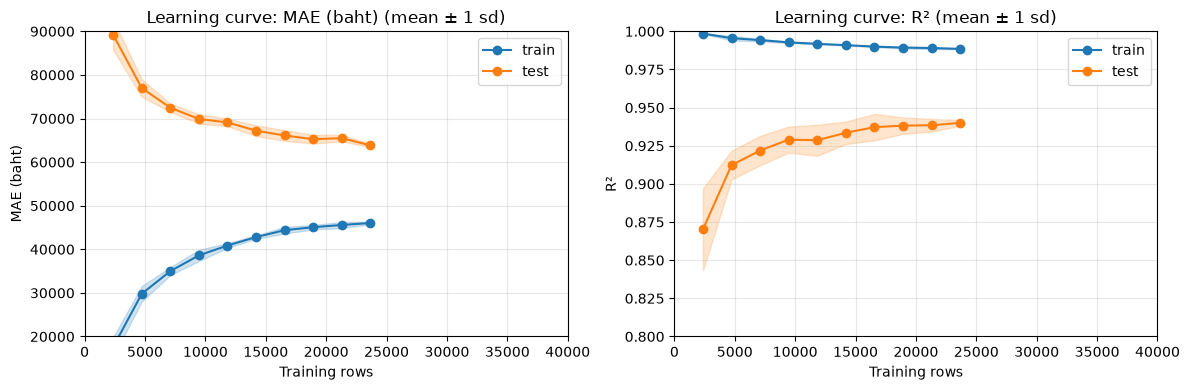

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]


In [34]:
# [34] learning curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง lc_table จากเซลล์ [33] เป็นตาราง แล้ววาดกราฟ 2 ช่องเคียงกัน (MAE และ R²)
#         แต่ละช่องมีเส้นค่าเฉลี่ยของ train และ test พร้อมแถบ ±1 sd
# ทำไม: ดูแนวโน้มว่าเมื่อเพิ่มแถวฝึกแล้วคะแนนเปลี่ยนอย่างไร และช่องว่างระหว่าง train กับ test
#       เปลี่ยนอย่างไร
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อขนาด และกราฟ 2 ช่อง
#   - ถ้า test MAE ยังลดลง (หรือ test R² ยังเพิ่ม) ที่ขนาดมาก ๆ อาจได้ประโยชน์จากข้อมูลเพิ่ม
#   - ถ้า train ดีกว่า test มาก แปลว่าโมเดลจำข้อมูลฝึกได้ดีกว่าข้อมูลใหม่ (อาการ overfit)
#     แต่สำหรับ XGBoost train MAE ต่ำกว่า test มากเป็นปกติ (boosting แก้ error บน train ทุกรอบ)
#     สิ่งที่ควรดูคือช่องว่างแคบลงเมื่อเพิ่มแถว (ข้อมูลมากขึ้น โมเดลจำทีละคันได้ยากขึ้น)
#     ถ้าช่องว่างกว้างขึ้นเมื่อเพิ่มแถว จึงเป็นสัญญาณที่น่าห่วง เซลล์ [40] ตรวจข้อนี้ให้
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS, R2_AXIS, ROWS_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - เป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่ใช่คำยืนยัน
#   - test ใช้อธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์
#   - แถบ ±1 sd คือความแกว่งจากการเลือกชุดย่อยต่างกัน ไม่ใช่ confidence interval
#     (ช่วงความเชื่อมั่น) และไม่รวมความไม่แน่นอนจากการสุ่ม test ชุดใหม่
#   - ที่ขนาดเต็ม ทุกรอบใช้แถวชุดเดียวกันแต่เรียงลำดับต่างกัน สำหรับ XGBoost ลำดับแถวเปลี่ยนว่า
#     แถวไหนถูกสุ่มเลือก (subsample) ให้ต้นไม้แต่ละต้น โมเดลจึงต่างกันเล็กน้อย sd จึงไม่เป็นศูนย์
#     (ต่างจากโน้ตบุ๊ค DT) และค่าที่ขนาดเต็มอาจไม่ตรงกับผลในเซลล์ [30] ทุกหลัก
#   - ช่องว่าง (gap) ต้องอ่านคู่กับระดับคะแนน ไม่ใช้วัด overfit เพียงลำพัง
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS, R2_AXIS, ROWS_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [34] learning curve: ตารางและกราฟ ===")

table_formats = {"rows": "{:,.0f}", "repeats": "{:.0f}"}
for column in lc_table.columns:
    if "MAE" in column:
        table_formats[column] = "{:,.0f}"
    elif "R2" in column:
        table_formats[column] = "{:.4f}"

print(f"อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม {LC_REPEATS} รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก")
display(lc_table.style.format(table_formats).hide(axis="index"))

out_of_axis = False
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ["MAE", "R2"], ["MAE (baht)", "R²"]):
    limits = MAE_AXIS if metric == "MAE" else R2_AXIS
    for part in ["train", "test"]:
        mean = lc_table[f"{part} {metric} mean"].to_numpy()
        sd = lc_table[f"{part} {metric} sd"].to_numpy()
        line, = ax.plot(lc_table["rows"], mean, marker="o", label=part)
        ax.fill_between(lc_table["rows"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < limits[0] or (mean + sd).max() > limits[1] or lc_table["rows"].max() > ROWS_AXIS[1]:
            out_of_axis = True
    ax.set(xlabel="Training rows", ylabel=ylabel, title=f"Learning curve: {ylabel} (mean ± 1 sd)")
    ax.set_xlim(*ROWS_AXIS)
    ax.set_ylim(*limits)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]")

=== [35] ตาราง CV train เทียบ validation ===


อ่านตาราง: หนึ่งแถวต่อ fold, MAE เป็นบาท, gap = validation - train (R² gap = train - validation)


,train MAE,validation MAE,MAE gap,gap % of validation MAE,train R2,validation R2,R2 gap
1,"45,452","72,207","26,755",37.05,0.9885,0.9352,0.0533
2,"45,037","76,739","31,703",41.31,0.9886,0.9073,0.0813
3,"43,888","75,303","31,415",41.72,0.9905,0.9249,0.0656
4,"43,738","73,946","30,208",40.85,0.9904,0.9134,0.0770
5,"45,071","69,624","24,554",35.27,0.9894,0.9059,0.0836
mean,"44,637","73,564","28,927",39.24,0.9895,0.9173,0.0721
sd,690,"2,474","2,806",2.59,0.0008,0.0112,0.0113


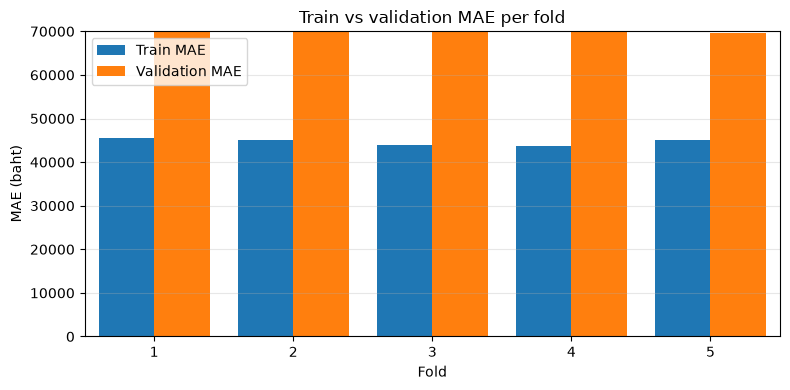

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]


In [35]:
# [35] ตาราง CV train เทียบ validation
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะใหม่ในแต่ละ fold ของ train แล้วเทียบคะแนนบนแถวที่ใช้ฝึก (train)
#         กับแถวที่กันไว้ตรวจ (validation) ของ fold นั้น ทั้ง MAE (บาท) และ R²
#         (fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด)
# ทำไม: ดูขนาดและความสม่ำเสมอของช่องว่างระหว่าง train กับ validation
#       - train ดีกว่า validation มาก อาจเป็นสัญญาณ overfit (จำข้อมูลฝึกมากเกินไป)
#       - ถ้าทั้งสองแย่และใกล้กัน อาจเป็น underfit (โมเดลง่ายเกินไป)
#       เซลล์นี้ไม่ตัดสินให้อัตโนมัติ ให้ดูระดับคะแนนและความกระจายร่วมกัน
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold (เลข fold เริ่มที่ 1) คอลัมน์ train MAE, validation MAE,
#              MAE gap (validation - train), gap เป็น % ของ validation MAE, train R²,
#              validation R², R² gap (train - validation) และท้ายตารางมีแถว mean กับ sd
#              (sd แบบ ddof=0 คำนวณจากแถว fold เท่านั้น) กับกราฟแท่งเทียบ train/validation MAE
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_BAR_AXIS, FOLD_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - ใช้เฉพาะ train และ folds ไม่ใช้ val หรือ test และเป็นการตรวจผู้ชนะที่เลือกจาก fold เดิม
#     จึงไม่ใช่ผลประเมินอิสระจากการเลือกพารามิเตอร์
#   - ช่วงค่าใน grid (เซลล์ [21]) ออกแบบจาก pilot บน train ก่อนเปลี่ยนไฟล์ ซึ่งรวมแถว held-out ของ fold ในครั้งนั้นด้วย
#     และผู้ชนะถูกเลือกจาก fold เดิม CV MAE จึงอาจดีเกินจริงเล็กน้อย
#     ควรใช้ test ที่ยังไม่แตะ (และ val) ตรวจอิสระ ซึ่งเซลล์ [40] เทียบให้
#   - โมเดลแต่ละ fold ที่นี่เหมือนกับที่ GridSearchCV ฝึกให้ผู้ชนะทุกประการ (fold เดิม พารามิเตอร์เดิม
#     จำนวน thread เดิม) ค่าเฉลี่ย validation MAE จึงควรเท่ากับ CV MAE ของผู้ชนะในเซลล์ [27]
#   - สำหรับ XGBoost train MAE ต่ำกว่า validation มากเป็นปกติ (boosting แก้ error บน train ทุกรอบ)
#     ช่องว่างเป็นอาการที่ต้องอ่านคู่กับระดับ CV และความกระจาย ไม่ใช่มาตรวัด overfit เพียงลำพัง
#   - learning curve (เซลล์ [33]-[34]) และกราฟรายรอบ (เซลล์ [38]-[39]) เป็นการตรวจเพิ่ม
#     ช่วยดูว่าเพิ่มแถวฝึกหรือเพิ่มรอบแล้วคะแนนและช่องว่างเปลี่ยนอย่างไร
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_BAR_AXIS, FOLD_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [35] ตาราง CV train เทียบ validation ===")

scores = cross_validate(
    clone(search.best_estimator_),
    train[features],
    train["price"],
    cv=folds,
    scoring={"MAE": "neg_mean_absolute_error", "R2": "r2"},
    return_train_score=True,
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    error_score="raise",
)

train_mae = -scores["train_MAE"]  # คะแนนเป็นค่าลบ จึงกลับเครื่องหมายให้เป็น MAE บวก
validation_mae = -scores["test_MAE"]  # "test" ของ sklearn คือแถว validation ใน fold
mae_gap = validation_mae - train_mae

fold_table = pd.DataFrame(
    {
        "train MAE": train_mae,
        "validation MAE": validation_mae,
        "MAE gap": mae_gap,
        "gap % of validation MAE": mae_gap * 100 / validation_mae,
        "train R2": scores["train_R2"],
        "validation R2": scores["test_R2"],
        "R2 gap": scores["train_R2"] - scores["test_R2"],
    },
    index=pd.Index(range(1, len(train_mae) + 1), name="fold"),
)

summary_rows = pd.DataFrame(
    [fold_table.mean(), fold_table.std(ddof=0)],
    index=["mean", "sd"],
)
cv_check_table = pd.concat([fold_table, summary_rows])

table_formats = {
    "train MAE": "{:,.0f}",
    "validation MAE": "{:,.0f}",
    "MAE gap": "{:,.0f}",
    "gap % of validation MAE": "{:.2f}",
    "train R2": "{:.4f}",
    "validation R2": "{:.4f}",
    "R2 gap": "{:.4f}",
}
print("อ่านตาราง: หนึ่งแถวต่อ fold, MAE เป็นบาท, gap = validation - train (R² gap = train - validation)")
display(cv_check_table.style.format(table_formats))

positions = np.arange(len(fold_table))
bar_width = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - bar_width / 2, fold_table["train MAE"], bar_width, label="Train MAE")
ax.bar(positions + bar_width / 2, fold_table["validation MAE"], bar_width, label="Validation MAE")
ax.set_xticks(positions, fold_table.index)
ax.set(xlabel="Fold", ylabel="MAE (baht)", title="Train vs validation MAE per fold")
ax.set_xlim(*FOLD_AXIS)
ax.set_ylim(*MAE_BAR_AXIS)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if (
    fold_table[["train MAE", "validation MAE"]].max().max() > MAE_BAR_AXIS[1]
    or len(fold_table) - 1 + bar_width > FOLD_AXIS[1]
):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]")

In [36]:
# [36] validation curve: คำนวณ
# ==================================================
# ทำอะไร: เปลี่ยนพารามิเตอร์ของโมเดลทีละตัว (max_depth, min_child_weight, reg_lambda, n_estimators)
#         ตามทุกค่าใน PARAM_GRID โดยคงพารามิเตอร์ตัวอื่นไว้ตามผู้ชนะ แล้ววัด MAE บนส่วนฝึกและ
#         ส่วนตรวจสอบ (validation) ของแต่ละ fold เก็บลง vc_results
#         (validation curve = กราฟคะแนนเมื่อเปลี่ยนพารามิเตอร์หนึ่งตัว,
#          fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ,
#          MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          sd = ส่วนเบี่ยงเบนมาตรฐานข้าม fold แบบ ddof=0)
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวทำให้โมเดลซับซ้อนขึ้น/ง่ายลงแล้ว MAE ฝึกกับ MAE ตรวจสอบ
#       ห่างกันอย่างไร เพื่ออ่านความซับซ้อนร่วมกับช่องว่างของคะแนน
# ผลที่ควรเห็น: ข้อความหนึ่งบรรทัดต่อพารามิเตอร์ จากนั้น vc_results พร้อมให้เซลล์ [37]
#              แสดงตารางและกราฟ (ไม่มีผลลัพธ์อื่นในเซลล์นี้)
# ข้อควรระวัง:
#   - ฝึกสำเนาของ Pipeline บน train ด้วย folds เดิมเท่านั้น ไม่เปลี่ยน search
#   - ค่าที่ลองคือทุกค่าใน PARAM_GRID ตามลำดับเดิม ทุกจุดบนเส้นจึงเป็นชุดที่ GridSearchCV เคยลองแล้ว
#     ค่า CV MAE จึงตรงกับแถวเดียวกันใน cv_results_ (คำนวณซ้ำเพื่อให้ได้ train MAE และ sd ครบทุกจุด)
#   - เส้นของ n_estimators คือการดูจำนวนรอบเพียงไม่กี่จุด เซลล์ [38]-[39] ดูละเอียดทุกรอบ
# ==================================================
print("=== [36] validation curve: คำนวณ ===")

vc_results = {}
for name in PARAM_GRID:
    values = list(PARAM_GRID[name])
    train_scores, valid_scores = validation_curve(
        clone(search.best_estimator_),
        train[features],
        train["price"],
        param_name="model__" + name,
        param_range=values,
        cv=folds,
        scoring="neg_mean_absolute_error",
        n_jobs=SEARCH_JOBS,
        pre_dispatch=SEARCH_JOBS,
        error_score="raise",
    )
    train_mae = -train_scores  # หนึ่งแถวต่อค่า หนึ่งคอลัมน์ต่อ fold
    valid_mae = -valid_scores
    vc_results[name] = {
        "values": values,
        "train_mean": train_mae.mean(axis=1),
        "train_sd": train_mae.std(axis=1, ddof=0),
        "cv_mean": valid_mae.mean(axis=1),
        "cv_sd": valid_mae.std(axis=1, ddof=0),
    }
    print(f"{name} เสร็จ ({len(values)} ค่า)")

=== [36] validation curve: คำนวณ ===


max_depth เสร็จ (5 ค่า)


min_child_weight เสร็จ (3 ค่า)


reg_lambda เสร็จ (4 ค่า)


n_estimators เสร็จ (5 ค่า)


=== [37] validation curve: ตารางและกราฟ ===
อ่านตาราง max_depth: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
8,"59,411","78,138","2,581","18,727"
12,"44,637","73,564","2,474","28,927"
16,"33,007","73,596","2,658","40,589"
20,"23,400","74,807","2,896","51,406"
24,"16,078","76,676","3,020","60,599"


อ่านตาราง min_child_weight: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
1,"44,637","73,564","2,474","28,927"
5,"56,401","76,942","3,213","20,540"
20,"69,352","88,274","3,120","18,922"


อ่านตาราง reg_lambda: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
0,"34,550","74,290","2,349","39,740"
1,"44,637","73,564","2,474","28,927"
10,"58,784","76,332","2,712","17,548"
100,"69,306","81,864","2,285","12,558"


อ่านตาราง n_estimators: MAE เป็นบาท, gap = CV MAE - train MAE


value,train MAE mean,CV MAE mean,CV MAE sd,gap
25,"80,266","93,755","2,318","13,489"
50,"61,815","80,604","2,473","18,789"
100,"54,403","76,495","2,587","22,092"
200,"48,531","74,364","2,441","25,833"
300,"44,637","73,564","2,474","28,927"


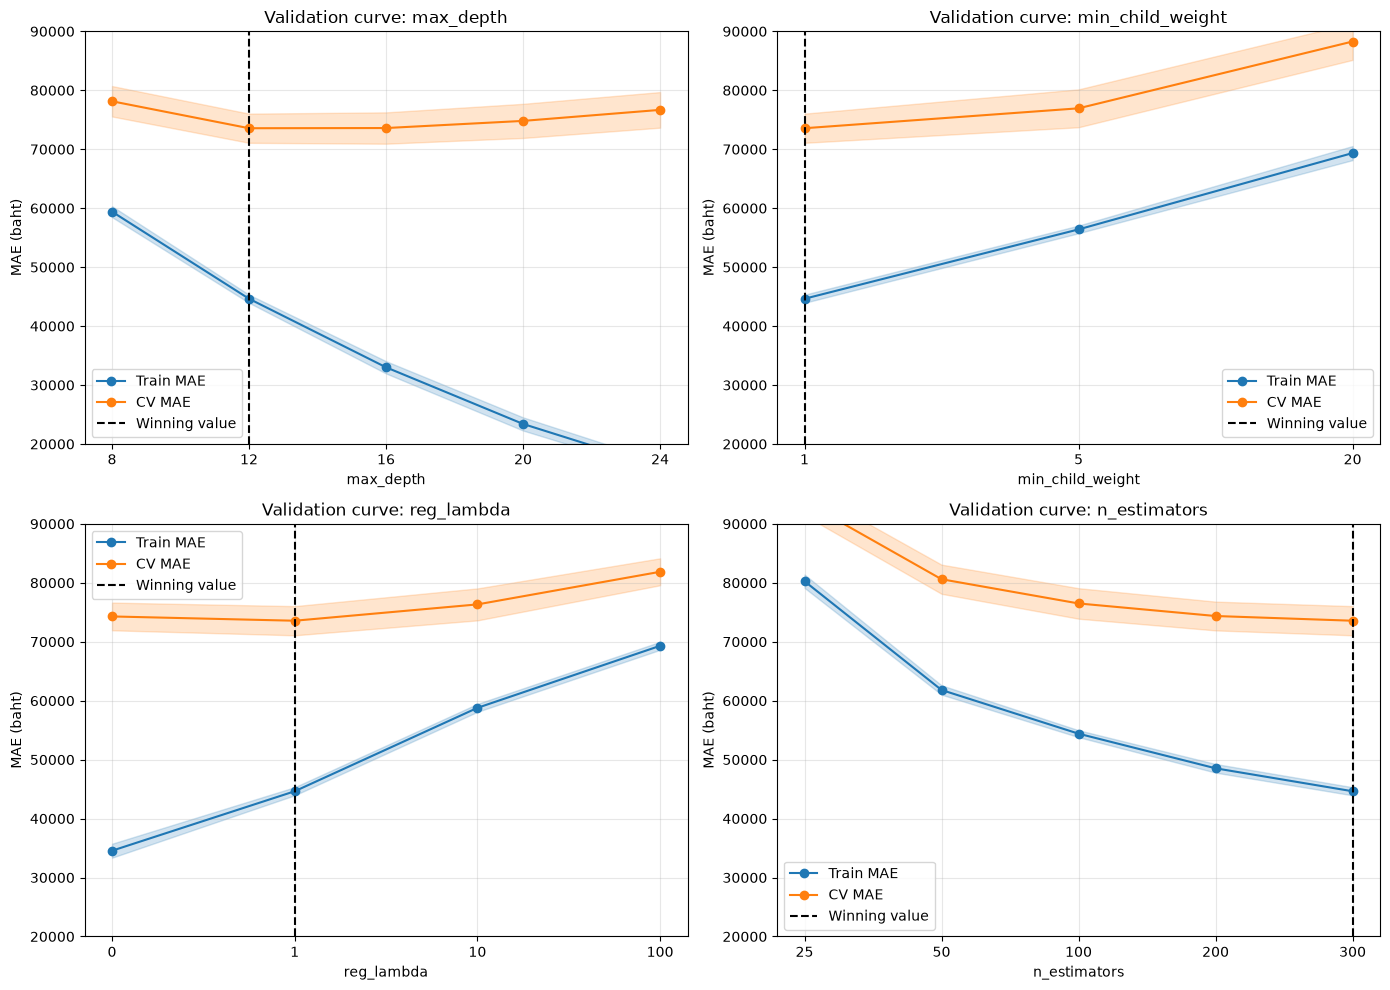

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]


In [37]:
# [37] validation curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดงตารางของแต่ละพารามิเตอร์จาก vc_results (เซลล์ [36]) แล้ววาดกราฟ 4 ช่อง (2 x 2)
#         เส้น train และ CV MAE เฉลี่ย พร้อมแถบ ±1 sd และเส้นประแนวตั้งที่ค่าของผู้ชนะ
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวพาโมเดลไปทาง overfit หรือ underfit
#       (overfit = จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี, underfit = ง่ายเกินจนจับแบบแผนไม่ได้)
# วิธีอ่าน:
#   - ทิศทางความซับซ้อน: max_depth ยิ่งลึก, min_child_weight ยิ่งเล็ก, reg_lambda ยิ่งเล็ก
#     และ n_estimators ยิ่งมาก โมเดลยิ่งซับซ้อน
#     (บนกราฟ ตำแหน่ง x เรียงตามลำดับค่าใน PARAM_GRID ไม่ใช่ระยะห่างจริง)
#   - overfit: train MAE ต่ำมากแต่ CV MAE สูงกว่ามาก และ CV MAE เริ่มแย่ลงเมื่อซับซ้อนขึ้น
#     มักเกิดทางด้านซับซ้อน (เช่น n_estimators มากเกินไปกับต้นไม้ลึก)
#   - underfit: ทั้ง train และ CV MAE สูงและใกล้กัน มักเกิดทางด้านง่าย (เช่น n_estimators = 25)
#   - ผู้ชนะ (เส้นประ) ไม่จำเป็นต้องอยู่ที่จุดต่ำสุดของ CV MAE เพราะกฎ 1-SE
#     (เลือกโมเดลที่ใบรวมน้อยที่สุดที่ CV MAE ไม่แย่กว่าค่าต่ำสุดเกิน 1 SE) ชอบรุ่นที่ง่ายกว่า
#   - เส้นแต่ละเส้นเปลี่ยนค่าทีละตัว ขณะที่ grid search เปลี่ยนพร้อมกันทุกตัว จุดต่ำสุดของเส้น
#     จึงอาจไม่ตรงกับชุดที่ CV MAE ต่ำสุดของ grid
# ผลที่ควรเห็น: ตาราง 4 ตาราง (คอลัมน์ value, train MAE mean, CV MAE mean, CV MAE sd, gap
#              โดย gap = CV MAE - train MAE) และรูปเดียวที่มี 4 กราฟ
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ตารางและกราฟนี้ใช้ train กับ folds เดิม จึงไม่ใช่ผลประเมินอิสระ
#              gap กว้างเป็นปกติของ XGBoost ให้ดูว่า CV MAE แย่ลงหรือไม่เป็นหลัก
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [37] validation curve: ตารางและกราฟ ===")

for name in PARAM_GRID:
    result = vc_results[name]
    value_labels = []
    for value in result["values"]:
        value_labels.append(f"{value:g}")
    table = pd.DataFrame(
        {
            "value": value_labels,
            "train MAE mean": result["train_mean"],
            "CV MAE mean": result["cv_mean"],
            "CV MAE sd": result["cv_sd"],
            "gap": result["cv_mean"] - result["train_mean"],
        }
    )
    print(f"อ่านตาราง {name}: MAE เป็นบาท, gap = CV MAE - train MAE")
    display(
        table.style
        .format(
            {
                "train MAE mean": "{:,.0f}",
                "CV MAE mean": "{:,.0f}",
                "CV MAE sd": "{:,.0f}",
                "gap": "{:,.0f}",
            }
        )
        .hide(axis="index")
    )

out_of_axis = False
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, name in zip(axes.flatten(), PARAM_GRID):
    result = vc_results[name]
    values = result["values"]
    positions = np.arange(len(values))  # ใช้ตำแหน่งแทนค่าจริง ระยะห่างของค่าจึงไม่เท่ากัน

    tick_labels = []
    for value in values:
        tick_labels.append(f"{value:g}")

    for mean, sd, label in [
        (result["train_mean"], result["train_sd"], "Train MAE"),
        (result["cv_mean"], result["cv_sd"], "CV MAE"),
    ]:
        line, = ax.plot(positions, mean, marker="o", label=label)
        ax.fill_between(positions, mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < MAE_AXIS[0] or (mean + sd).max() > MAE_AXIS[1]:
            out_of_axis = True

    winner_value = search.best_params_["model__" + name]
    ax.axvline(values.index(winner_value), color="black", linestyle="--", label="Winning value")
    ax.set_xticks(positions, tick_labels)
    ax.set(xlabel=name, ylabel="MAE (baht)", title=f"Validation curve: {name}")
    ax.set_ylim(*MAE_AXIS)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]")

In [38]:
# [38] MAE รายรอบ: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลด้วยพารามิเตอร์ของผู้ชนะใหม่ในแต่ละ fold ของ train ให้ครบจำนวนรอบสูงสุดใน grid
#         แล้วเก็บ MAE "ทุกรอบ" ทั้งบนแถวที่ใช้ฝึก (train fold) และแถวที่กันไว้ตรวจ (CV fold)
#         เก็บไว้ใน round_curves ให้เซลล์ [39] แสดงตารางและกราฟ
#         (รอบ = boosting round = การเพิ่มต้นไม้ 1 ต้น, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: จำนวนรอบ (n_estimators) เป็นตัวที่ทำให้ XGBoost overfit ได้ง่ายที่สุด ทุกรอบที่เพิ่ม error บน
#       train ลดลงเสมอ แต่ error บนข้อมูลที่ไม่เคยเห็นจะลดลงช่วงแรก แล้วนิ่ง แล้วเริ่มแย่ลง
#       กราฟรายรอบแสดงให้เห็นว่าจำนวนรอบที่เลือกอยู่ตรงไหนของเส้นนี้ (ละเอียดกว่า grid ที่มีแค่ 5 จุด)
#       วิธีคำนวณ: ส่งแถวของ fold เข้า eval_set ตอนฝึก XGBoost จะวัด MAE ของโมเดลที่มี 1, 2, 3, ...
#       ต้นแรกให้ทุกรอบ ฝึกครั้งเดียวจึงได้ทั้งเส้น ผลที่รอบ k เท่ากับโมเดลที่ฝึก n_estimators = k
#       (pilot 2026-10-23 ยืนยันแล้วว่าต้นไม้ k ต้นแรกของโมเดลที่ยาวกว่า เหมือนโมเดล k ต้นทุกประการ)
#       eval_set ใช้วัดผลอย่างเดียว ไม่ได้ใช้หยุดก่อน (ไม่มี early stopping) และไม่เปลี่ยนการฝึก
# ผลที่ควรเห็น: ข้อความ "fold k/5 เสร็จ" ทีละบรรทัด และบรรทัดสรุปจำนวนรอบที่คำนวณ
# ข้อควรระวัง:
#   - ใช้ train และ folds เดิมเท่านั้น ไม่ใช้ validation หรือ test (กราฟนี้ "train data only")
#   - แต่ละ fold เข้ารหัส one-hot จากแถวฝึกของ fold นั้นเอง เหมือนที่ Pipeline ทำใน GridSearchCV
#   - ใช้พารามิเตอร์ของผู้ชนะทุกตัว ยกเว้น n_estimators ที่ตั้งเป็นค่าสูงสุดใน grid เพื่อดูทั้งช่วง
# ==================================================
print("=== [38] MAE รายรอบ: คำนวณ ===")

curve_rounds = max(PARAM_GRID["n_estimators"])
train_fold_curves = []
cv_fold_curves = []
for fold_number, (fit_index, check_index) in enumerate(folds, start=1):
    fit_part = train.iloc[fit_index]
    check_part = train.iloc[check_index]
    encoder = FoldOneHot(NUM_COLS, CAT_COLS).fit(fit_part[features])
    encoded_fit = encoder.transform(fit_part[features])
    encoded_check = encoder.transform(check_part[features])
    round_model = clone(search.best_estimator_.named_steps["model"])
    round_model.set_params(n_estimators=curve_rounds)
    round_model.fit(
        encoded_fit,
        fit_part["price"],
        eval_set=[(encoded_fit, fit_part["price"]), (encoded_check, check_part["price"])],
        verbose=False,
    )
    history = round_model.evals_result()  # validation_0 = แถวฝึก, validation_1 = แถวตรวจ
    train_fold_curves.append(history["validation_0"]["mae"])
    cv_fold_curves.append(history["validation_1"]["mae"])
    print(f"fold {fold_number}/{len(folds)} เสร็จ")

round_curves = pd.DataFrame({
    "round": np.arange(1, curve_rounds + 1),
    "train MAE mean": np.mean(train_fold_curves, axis=0),
    "train MAE sd": np.std(train_fold_curves, axis=0),
    "CV MAE mean": np.mean(cv_fold_curves, axis=0),
    "CV MAE sd": np.std(cv_fold_curves, axis=0),
})
print(f"ได้ MAE รายรอบครบ {curve_rounds:,} รอบ เฉลี่ยจาก {len(folds)} fold")

=== [38] MAE รายรอบ: คำนวณ ===


fold 1/5 เสร็จ


fold 2/5 เสร็จ


fold 3/5 เสร็จ


fold 4/5 เสร็จ


fold 5/5 เสร็จ
ได้ MAE รายรอบครบ 300 รอบ เฉลี่ยจาก 5 fold


=== [39] MAE รายรอบ: ตารางและกราฟ ===
อ่านตาราง: MAE เฉลี่ย 5 fold (บาท) ที่จำนวนรอบใน grid, gap = CV MAE - train MAE


round,train MAE mean,train MAE sd,CV MAE mean,CV MAE sd,gap
25,"80,266","1,134","93,755","2,318","13,489"
50,"61,815",791,"80,604","2,473","18,789"
100,"54,403",590,"76,495","2,587","22,092"
200,"48,531",732,"74,364","2,441","25,833"
300,"44,637",690,"73,564","2,474","28,927"


รอบที่ CV MAE ต่ำสุด     : 300 (CV MAE 73,564 บาท)
รอบของผู้ชนะ 1-SE        : 300 (CV MAE 73,564 บาท)
ส่วนต่างจากจุดต่ำสุด      : 0 บาท
CV MAE ผู้ชนะจาก search  : 73,564 บาท (ควรเท่ากับบรรทัดรอบของผู้ชนะ)


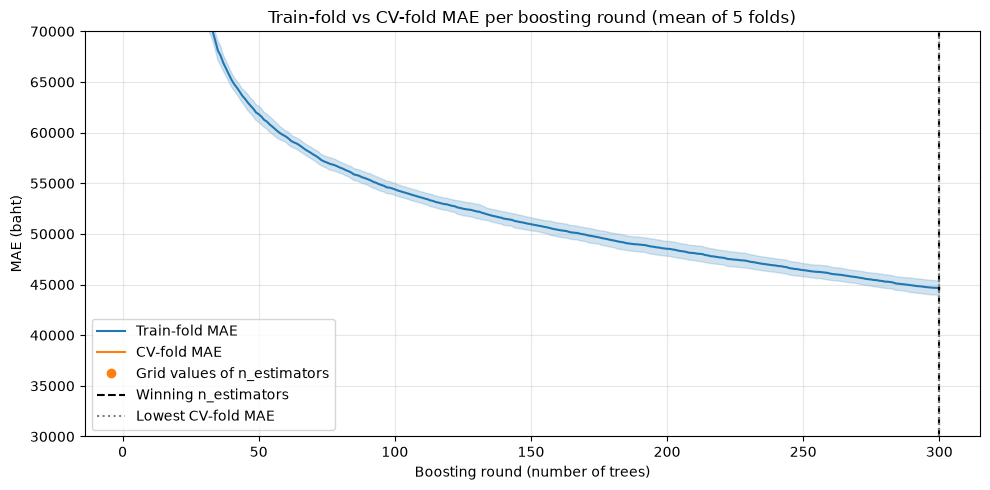

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟ MAE รายรอบ) ให้ขยาย MAE_ROUND_AXIS ในเซลล์ [03]


In [39]:
# [39] MAE รายรอบ: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง round_curves จากเซลล์ [38] เป็นตาราง (เฉพาะจำนวนรอบที่อยู่ใน grid) และกราฟเส้น
#         MAE เฉลี่ย 5 fold ของแถวฝึก (train fold) และแถวตรวจ (CV fold) ทุกรอบ พร้อมแถบ ±1 sd
#         (sd แบบ ddof=0 ข้าม fold) เส้นประแนวตั้งที่จำนวนรอบของผู้ชนะ และเส้นจุดที่รอบที่ CV MAE ต่ำสุด
#         แล้วพิมพ์สรุปรอบที่ดีที่สุดเทียบกับรอบของผู้ชนะ
# ทำไม: ดูว่าจำนวนรอบที่ผู้ชนะใช้ อยู่ก่อน ตรง หรือหลังจุดที่ CV MAE ต่ำสุด
#       - เส้น train fold ลดลงเรื่อย ๆ เสมอ (boosting แก้ error บนแถวฝึกทุกรอบ) จึงบอกเรื่อง overfit ไม่ได้
#       - เส้น CV fold คือสิ่งที่ต้องดู: ช่วงแรกลดลงเร็ว (underfit = รอบน้อยไป) แล้วแบน แล้วค่อย ๆ
#         สูงขึ้น (overfit = รอบมากไป ต้นไม้ใหม่เริ่มจำรายละเอียดเฉพาะของแถวฝึก)
#       - ผู้ชนะ 1-SE มักอยู่ก่อนจุดต่ำสุดเล็กน้อย เพราะกฎชอบโมเดลที่มีต้นไม้น้อยกว่าเมื่อผลต่างกัน
#         ไม่เกิน 1 SE ซึ่งเป็นทางที่ปลอดภัยจาก overfit
#       - ตรวจความถูกต้องไปด้วย: CV MAE ที่รอบของผู้ชนะจากเส้นนี้ ควรเท่ากับ CV MAE ของผู้ชนะจาก
#         GridSearchCV (เซลล์ [27]) เพราะเป็นโมเดลเดียวกัน ต่างกันได้แค่เศษทศนิยม
# ผลที่ควรเห็น: ตาราง 5 แถว (หนึ่งแถวต่อจำนวนรอบใน grid) บรรทัดสรุป และกราฟ 1 รูป
#       แกน y ตัดช่วงแรก ๆ ที่ MAE สูงมากออก (ขอบบน = CV MAE ที่จำนวนรอบน้อยสุดใน grid) เพื่อให้เห็นส่วนที่สำคัญ
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_ROUND_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง: ใช้ train และ folds เดิม จึงไม่ใช่ผลประเมินอิสระ เซลล์ [40] ใช้ผลนี้ในการตรวจ overfit
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_ROUND_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [39] MAE รายรอบ: ตารางและกราฟ ===")

winner_rounds = search.best_params_["model__n_estimators"]
grid_rounds = round_curves[round_curves["round"].isin(PARAM_GRID["n_estimators"])].copy()
grid_rounds["gap"] = grid_rounds["CV MAE mean"] - grid_rounds["train MAE mean"]

print("อ่านตาราง: MAE เฉลี่ย 5 fold (บาท) ที่จำนวนรอบใน grid, gap = CV MAE - train MAE")
display(
    grid_rounds.style
    .format({
        "round": "{:,.0f}",
        "train MAE mean": "{:,.0f}",
        "train MAE sd": "{:,.0f}",
        "CV MAE mean": "{:,.0f}",
        "CV MAE sd": "{:,.0f}",
        "gap": "{:,.0f}",
    })
    .hide(axis="index")
)

best_row = round_curves.loc[round_curves["CV MAE mean"].idxmin()]
winner_row = round_curves.loc[round_curves["round"] == winner_rounds].iloc[0]
best_mae = best_row["CV MAE mean"]
winner_mae = winner_row["CV MAE mean"]
print(f"รอบที่ CV MAE ต่ำสุด     : {best_row['round']:,.0f} (CV MAE {best_mae:,.0f} บาท)")
print(f"รอบของผู้ชนะ 1-SE        : {winner_rounds:,} (CV MAE {winner_mae:,.0f} บาท)")
print(f"ส่วนต่างจากจุดต่ำสุด      : {winner_mae - best_mae:,.0f} บาท")
print(f"CV MAE ผู้ชนะจาก search  : {cv_mae_all[chosen_index]:,.0f} บาท (ควรเท่ากับบรรทัดรอบของผู้ชนะ)")

fig, ax = plt.subplots(figsize=(10, 5))
for column, label in [("train MAE", "Train-fold MAE"), ("CV MAE", "CV-fold MAE")]:
    mean = round_curves[f"{column} mean"].to_numpy()
    sd = round_curves[f"{column} sd"].to_numpy()
    line, = ax.plot(round_curves["round"], mean, label=label)
    ax.fill_between(round_curves["round"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
ax.plot(grid_rounds["round"], grid_rounds["CV MAE mean"], "o", color="tab:orange",
        label="Grid values of n_estimators")
ax.axvline(winner_rounds, color="black", linestyle="--", label="Winning n_estimators")
ax.axvline(best_row["round"], color="gray", linestyle=":", label="Lowest CV-fold MAE")
ax.set_ylim(*MAE_ROUND_AXIS)  # รอบแรกๆ ที่ MAE สูงมากถูกตัดออกจากภาพเหมือนเดิม
ax.set(
    xlabel="Boosting round (number of trees)",
    ylabel="MAE (baht)",
    title="Train-fold vs CV-fold MAE per boosting round (mean of 5 folds)",
)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ตรวจเฉพาะรอบตั้งแต่รอบแรกใน grid เป็นต้นไป (รอบก่อนหน้านั้นตั้งใจตัดทิ้ง)
shown = round_curves[round_curves["round"] >= grid_rounds["round"].min()]
for column in ["train MAE", "CV MAE"]:
    if (
        (shown[f"{column} mean"] - shown[f"{column} sd"]).min() < MAE_ROUND_AXIS[0]
        or (shown[f"{column} mean"] + shown[f"{column} sd"]).max() > MAE_ROUND_AXIS[1]
    ):
        print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟ MAE รายรอบ) ให้ขยาย MAE_ROUND_AXIS ในเซลล์ [03]")
        break

In [40]:
# [40] สรุปการตรวจ overfit
# ==================================================
# ทำอะไร: รวมหลักฐานจากเซลล์ก่อนหน้าเป็นบรรทัด PASS / WARN 4 ข้อ ตามเกณฑ์ที่ประกาศไว้ล่วงหน้า
#         โน้ตบุ๊คจึงตัดสินตัวเลขของตัวเองได้ โดยไม่ต้องจำค่าจากการรันครั้งก่อน
# ความจริงเฉพาะของ XGBoost (อ่านก่อนดูผล):
#   - train MAE ต่ำกว่า CV / validation / test มากเสมอ เพราะทุกรอบของ boosting สร้างต้นไม้ใหม่มาแก้
#     ส่วนที่ยังทายผิด "บนแถวฝึก" โดยตรง error บน train จึงลดลงทุกรอบจนเกือบจำได้หมด
#     ช่องว่าง train กับ test ลำพังจึงไม่ใช่หลักฐานของ overfit
#   - การตรวจที่ซื่อตรงคือ (ก) ค่าที่ CV สัญญาไว้ (CV MAE จาก train) ตรงกับผลบนข้อมูลที่ไม่เคยแตะ
#     (validation และ test) หรือไม่ (ข) จำนวนรอบอยู่ในช่วงที่ CV MAE ยังไม่แย่ลง (ค) เมื่อเพิ่มข้อมูลฝึก
#     ช่องว่างแคบลงตามที่ควรเป็น
# เกณฑ์และเหตุผล:
#   1-2) |validation MAE - CV MAE| และ |test MAE - CV MAE| ไม่เกิน 5% ของ CV MAE
#        เหตุผล: MAE ที่วัดจากรถใน validation หรือ test มีความแกว่งจากการสุ่มตัวอย่าง (SE = sd ของ |ความผิดพลาด|
#        หาร sqrt(จำนวนคัน)) เซลล์นี้คำนวณและพิมพ์ SE จากชุดข้อมูลที่ใช้จริงให้ดูด้วย
#        และ CV MAE เองก็แกว่งได้เช่นกัน ใช้เกณฑ์ 5% เป็นหลักปฏิบัติ โดยอ่านร่วมกับ SE ถ้าต่างเกินนี้
#        ไม่น่าใช่ความบังเอิญ แปลว่าโมเดลทำได้แย่กว่าที่ CV สัญญาไว้ (อาจ overfit กับการเลือกบน train)
#   3) CV MAE ที่รอบของผู้ชนะ สูงกว่าจุดต่ำสุดของเส้นรายรอบ (เซลล์ [39]) ไม่เกิน 1 SE ของผู้ชนะ
#      (SE = std ของ CV MAE ข้าม fold / sqrt(จำนวน fold) ตัวเดียวกับกฎ 1-SE)
#      เหตุผล: ถ้าเกิน แปลว่าจำนวนรอบที่เลือกน้อยไป (underfit) หรือมากไป (overfit) อย่างมีนัย
#   4) ช่องว่าง test MAE - train MAE ของ learning curve ที่ขนาดเต็ม แคบกว่าที่ขนาดเล็กสุด
#      เหตุผล: โมเดลที่พอดีจะจำทีละคันได้ยากขึ้นเมื่อข้อมูลมากขึ้น ช่องว่างจึงควรแคบลง
#      ถ้าช่องว่างไม่แคบลงหรือกว้างขึ้น เป็นสัญญาณว่าโมเดลยังจำข้อมูลฝึกมากเกินไป
# ผลที่ควรเห็น: ตัวเลขประกอบแต่ละข้อ บรรทัด PASS / WARN 4 บรรทัด และบรรทัดสรุปรวม
# ข้อควรระวัง: เกณฑ์เหล่านี้เป็นหลักปฏิบัติที่สมเหตุสมผล ไม่ใช่การทดสอบทางสถิติที่เข้มงวด
#         เซลล์นี้ไม่เปลี่ยนโมเดลและไม่ใช้ผลเหล่านี้ย้อนไปเลือกพารามิเตอร์ใหม่
#         ถ้ามี WARN ให้อ่านตัวเลขประกอบและกราฟของเซลล์ที่เกี่ยวข้องก่อนสรุป
# ==================================================
print("=== [40] สรุปการตรวจ overfit ===")

tolerance_percent = 5.0
cv_mae_winner = cv_mae_all[chosen_index]
winner_se = cv_results["std_test_MAE"][chosen_index] / np.sqrt(n_splits)

checks = []
for name, part in [("validation", val), ("test", test)]:
    errors = np.abs(part["price"].to_numpy() - model.predict(part[features]))
    noise_percent = errors.std(ddof=1) / np.sqrt(len(errors)) / errors.mean() * 100
    difference_percent = (results[name]["MAE"] - cv_mae_winner) / cv_mae_winner * 100
    print(f"{name:<10} MAE {results[name]['MAE']:,.0f} บาท เทียบ CV MAE {cv_mae_winner:,.0f} บาท"
          f" ต่าง {difference_percent:+.2f}% (ความแกว่งจากการสุ่ม 1 SE ประมาณ {noise_percent:.2f}%)")
    checks.append((
        abs(difference_percent) <= tolerance_percent,
        f"{name} MAE ต่างจาก CV MAE ไม่เกิน {tolerance_percent:.0f}% (generalisation)",
    ))

rounds_excess = winner_row["CV MAE mean"] - best_row["CV MAE mean"]
if winner_rounds < best_row["round"]:
    side = "ก่อนจุดต่ำสุด (ฝั่งรอบน้อย ปลอดภัยจาก overfit)"
elif winner_rounds > best_row["round"]:
    side = "หลังจุดต่ำสุด (ฝั่งรอบมาก)"
else:
    side = "ตรงจุดต่ำสุดพอดี"
print(f"จำนวนรอบของผู้ชนะ {winner_rounds:,} อยู่{side} สูงกว่าจุดต่ำสุด {rounds_excess:,.0f} บาท"
      f" (1 SE = {winner_se:,.0f} บาท)")
checks.append((
    rounds_excess <= winner_se,
    "จำนวนรอบอยู่ในช่วง 1 SE ของจุดที่ CV MAE ต่ำสุด (ไม่น้อยหรือมากเกินไป)",
))

smallest = lc_table.iloc[0]
largest = lc_table.iloc[-1]
gap_smallest = smallest["test MAE mean"] - smallest["train MAE mean"]
gap_largest = largest["test MAE mean"] - largest["train MAE mean"]
print(f"ช่องว่าง test - train ของ learning curve: {smallest['rows']:,.0f} แถว = {gap_smallest:,.0f} บาท,"
      f" {largest['rows']:,.0f} แถว = {gap_largest:,.0f} บาท")
checks.append((
    gap_largest < gap_smallest,
    "ช่องว่าง test - train แคบลงเมื่อเพิ่มข้อมูลฝึก (learning curve)",
))

print()
warn_count = 0
for passed, description in checks:
    print(f"{'PASS' if passed else 'WARN'} : {description}")
    if not passed:
        warn_count = warn_count + 1
if warn_count == 0:
    print("สรุป: ผ่านทุกข้อ ไม่พบสัญญาณ overfit ตามเกณฑ์ที่ตั้งไว้")
else:
    print(f"สรุป: มี WARN {warn_count} ข้อ ให้อ่านตัวเลขประกอบและกราฟของเซลล์ที่เกี่ยวข้องก่อนสรุป")

=== [40] สรุปการตรวจ overfit ===
validation MAE 69,484 บาท เทียบ CV MAE 73,564 บาท ต่าง -5.55% (ความแกว่งจากการสุ่ม 1 SE ประมาณ 4.57%)
test       MAE 64,228 บาท เทียบ CV MAE 73,564 บาท ต่าง -12.69% (ความแกว่งจากการสุ่ม 1 SE ประมาณ 3.71%)
จำนวนรอบของผู้ชนะ 300 อยู่ตรงจุดต่ำสุดพอดี สูงกว่าจุดต่ำสุด 0 บาท (1 SE = 1,107 บาท)
ช่องว่าง test - train ของ learning curve: 2,365 แถว = 71,586 บาท, 23,657 แถว = 17,807 บาท

WARN : validation MAE ต่างจาก CV MAE ไม่เกิน 5% (generalisation)
WARN : test MAE ต่างจาก CV MAE ไม่เกิน 5% (generalisation)
PASS : จำนวนรอบอยู่ในช่วง 1 SE ของจุดที่ CV MAE ต่ำสุด (ไม่น้อยหรือมากเกินไป)
PASS : ช่องว่าง test - train แคบลงเมื่อเพิ่มข้อมูลฝึก (learning curve)
สรุป: มี WARN 2 ข้อ ให้อ่านตัวเลขประกอบและกราฟของเซลล์ที่เกี่ยวข้องก่อนสรุป


=== [41] ความสำคัญแบบ permutation บน test ===


Permutation importance: increase in test MAE (baht)
variable        mean       std  share (%)
 car_age 165590.7531 3373.0924    27.6421
  engine 163707.3594 4065.3795    27.3277
   brand 113415.0203 2148.4828    18.9324
car_type  59881.4563 2349.8037     9.9960
   model  42755.8703  810.5205     7.1372
 mileage  29853.6516 1746.7898     4.9835
    fuel  16832.9273 1206.3753     2.8099
    gear   7016.7234  374.5674     1.1713


,variable,mean,std,share (%)
0,car_age,165590.753125,3373.092429,27.642052
1,engine,163707.359375,4065.379476,27.327657
2,brand,113415.020312,2148.482794,18.932361
3,car_type,59881.456250,2349.803714,9.996007
4,model,42755.870313,810.520530,7.137234
5,mileage,29853.651562,1746.789825,4.983468
6,fuel,16832.927344,1206.375315,2.809919
7,gear,7016.723437,374.567371,1.171301


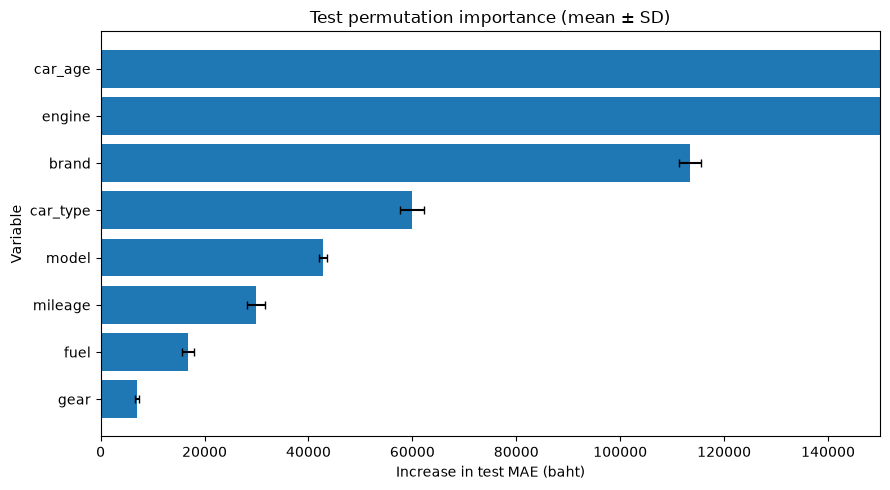

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]


In [41]:
# [41] ความสำคัญแบบ permutation บน test
# ==================================================
# ทำอะไร: สลับตัวแปรต้นฉบับทีละคอลัมน์ก่อน encoding สิบรอบแล้ววัด MAE ที่เพิ่มเป็นบาท
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ค่าติดลบเกิดได้; share ใช้ผลรวมมีเครื่องหมาย ไม่ตัดค่าลบทิ้ง; ถ้าผลรวมศูนย์ให้ share เป็นศูนย์
# ==================================================
print("=== [41] ความสำคัญแบบ permutation บน test ===")

importance_estimator = search.best_estimator_
X_test = test[features]
y_test = test["price"]
assert len(features) == 8 and list(X_test.columns) == features
permutation_result = permutation_importance(
    importance_estimator, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=SEED,
)
permutation_table = pd.DataFrame({"variable": features, "mean": permutation_result.importances_mean,
                                  "std": permutation_result.importances_std})
# ใช้ผลรวมแบบมีเครื่องหมาย ค่าลบหมายถึงสลับแล้วดีขึ้น; ถ้าผลรวมเป็นศูนย์ให้ share เป็นศูนย์
total_increase = permutation_table["mean"].sum()
permutation_table["share (%)"] = (100 * permutation_table["mean"] / total_increase
                                   if total_increase != 0 else 0.0)
permutation_table = permutation_table.sort_values("mean", ascending=False, kind="stable").reset_index(drop=True)
print("Permutation importance: increase in test MAE (baht)")
print(permutation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(permutation_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(permutation_table["variable"], permutation_table["mean"], xerr=permutation_table["std"], capsize=3)
ax.invert_yaxis()
ax.set(xlabel="Increase in test MAE (baht)", ylabel="Variable", title="Test permutation importance (mean ± SD)")
ax.set_xlim(*PERM_AXIS)
plt.tight_layout()
plt.show()
if ((permutation_table["mean"] - permutation_table["std"]).min() < PERM_AXIS[0]
        or (permutation_table["mean"] + permutation_table["std"]).max() > PERM_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]")


=== [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===
Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)
variable  model_based
   model     0.446996
   brand     0.443085
car_type     0.084721
  engine     0.009485
    fuel     0.008878
 car_age     0.003654
    gear     0.002387
 mileage     0.000792


,variable,model_based
4,model,0.446996
3,brand,0.443085
5,car_type,0.084721
0,engine,0.009485
6,fuel,0.008878
2,car_age,0.003654
7,gear,0.002387
1,mileage,0.000792


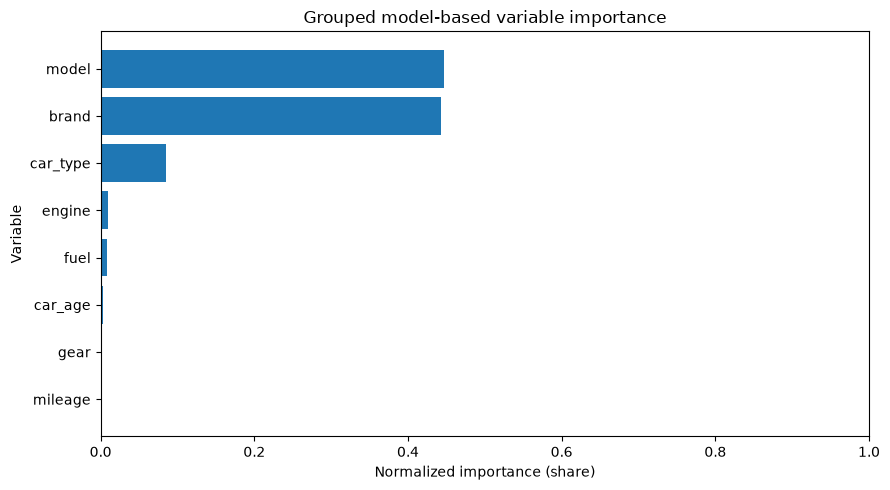

In [42]:
# [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร
# ==================================================
# ทำอะไร: รวม impurity หรือ gain ของ dummy กลับเป็นแปดตัวแปรและ normalize ให้รวมเป็นหนึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ใช้ผู้ชนะที่ fit บน train แล้ว; gain ขอผ่าน booster อย่างชัดเจน; ระดับมากอาจได้เปรียบ
# ==================================================
print("=== [42] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===")

fitted_model = importance_estimator.named_steps["model"]
if isinstance(fitted_model, TransformedTargetRegressor):
    fitted_model = fitted_model.regressor_
encoded_names = importance_estimator.named_steps["encode"].get_feature_names_out()
if MODEL_NAME == "XGB":
    # ขอ gain อย่างชัดเจนและจับคู่ชื่อตามลำดับจริงของ encoder (รองรับทั้งชื่อจริงและ f0, f1)
    booster = fitted_model.get_booster()
    gains = booster.get_score(importance_type="gain")
    booster_names = booster.feature_names
    if booster_names is None:
        booster_names = [f"f{i}" for i in range(len(encoded_names))]
    else:
        assert booster_names == list(encoded_names), "Booster feature order differs from encoder output"
    assert len(booster_names) == len(encoded_names)
    assert set(gains).issubset(booster_names), "Unknown booster feature name"
    weights = np.asarray([gains.get(name, 0.0) for name in booster_names], dtype=float)
else:
    weights = np.asarray(fitted_model.feature_importances_, dtype=float)
assert len(weights) == len(encoded_names)
grouped_importance = {name: 0.0 for name in features}
for encoded_name, weight in zip(encoded_names, weights):
    original_name = str(encoded_name).split("=", 1)[0]
    assert original_name in grouped_importance, f"Unknown encoded variable: {encoded_name}"
    grouped_importance[original_name] += float(weight)
total_weight = sum(grouped_importance.values())
assert total_weight > 0, "โมเดลไม่มีความสำคัญที่เป็นบวกให้ normalize"
grouped_importance = {name: weight / total_weight for name, weight in grouped_importance.items()}
assert np.isclose(sum(grouped_importance.values()), 1.0)
model_importance_table = pd.DataFrame({"variable": features,
    "model_based": [grouped_importance[name] for name in features]}).sort_values("model_based", ascending=False, kind="stable")
print("Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)")
print(model_importance_table.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
display(model_importance_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(model_importance_table["variable"], model_importance_table["model_based"])
ax.invert_yaxis()
ax.set(xlabel="Normalized importance (share)", ylabel="Variable", title="Grouped model-based variable importance")
ax.set_xlim(*SHARE_AXIS)
plt.tight_layout()
plt.show()
if (model_importance_table["model_based"].min() < SHARE_AXIS[0]
        or model_importance_table["model_based"].max() > SHARE_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (model importance) ให้ขยาย SHARE_AXIS ในเซลล์ [03]")


In [43]:
# [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON
# ==================================================
# ทำอะไร: แสดงความสำคัญและอันดับทั้งสองวิธีเคียงกันแล้วพิมพ์ JSON หนึ่งบรรทัด
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: เมื่อผลสองวิธีขัดกันควรเชื่อ permutation บนข้อมูลที่ไม่เคยเห็นมากกว่า
# ==================================================
print("=== [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===")

# impurity/gain เอนเอียงไปหาตัวแปรที่มีหลายระดับ เช่น model ซึ่งมี dummy หลายร้อยตัว และคำนวณจากแถวฝึก
# permutation วัดว่า error เพิ่มบนแถวที่ไม่เคยเห็นเท่าใด เมื่อสองวิธีขัดกันควรเชื่อ permutation มากกว่า
importance_comparison = permutation_table.merge(model_importance_table, on="variable", validate="one_to_one")
importance_comparison["permutation rank"] = importance_comparison["mean"].rank(method="min", ascending=False).astype(int)
importance_comparison["model rank"] = importance_comparison["model_based"].rank(method="min", ascending=False).astype(int)
importance_comparison = importance_comparison[["variable", "mean", "std", "share (%)", "permutation rank", "model_based", "model rank"]]
print(importance_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(importance_comparison)
print("IMPORTANCE_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "permutation": {row["variable"]: {"mean": float(row["mean"]), "std": float(row["std"])}
                    for _, row in permutation_table.iterrows()},
    "model_based": grouped_importance,
}, allow_nan=False))


=== [43] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===
variable        mean       std  share (%)  permutation rank  model_based  model rank
 car_age 165590.7531 3373.0924    27.6421                 1       0.0037           6
  engine 163707.3594 4065.3795    27.3277                 2       0.0095           4
   brand 113415.0203 2148.4828    18.9324                 3       0.4431           2
car_type  59881.4563 2349.8037     9.9960                 4       0.0847           3
   model  42755.8703  810.5205     7.1372                 5       0.4470           1
 mileage  29853.6516 1746.7898     4.9835                 6       0.0008           8
    fuel  16832.9273 1206.3753     2.8099                 7       0.0089           5
    gear   7016.7234  374.5674     1.1713                 8       0.0024           7


,variable,mean,std,share (%),permutation rank,model_based,model rank
0,car_age,165590.753125,3373.092429,27.642052,1,0.003654,6
1,engine,163707.359375,4065.379476,27.327657,2,0.009485,4
2,brand,113415.020312,2148.482794,18.932361,3,0.443085,2
3,car_type,59881.456250,2349.803714,9.996007,4,0.084721,3
4,model,42755.870313,810.520530,7.137234,5,0.446996,1
5,mileage,29853.651562,1746.789825,4.983468,6,0.000792,8
6,fuel,16832.927344,1206.375315,2.809919,7,0.008878,5
7,gear,7016.723437,374.567371,1.171301,8,0.002387,7


IMPORTANCE_JSON={"run_id": "XGB_new_cardb", "permutation": {"car_age": {"mean": 165590.753125, "std": 3373.09242890526}, "engine": {"mean": 163707.359375, "std": 4065.3794764164472}, "brand": {"mean": 113415.0203125, "std": 2148.482794156637}, "car_type": {"mean": 59881.45625, "std": 2349.8037142047688}, "model": {"mean": 42755.8703125, "std": 810.520530032702}, "mileage": {"mean": 29853.6515625, "std": 1746.7898246026764}, "fuel": {"mean": 16832.92734375, "std": 1206.3753153162654}, "gear": {"mean": 7016.7234375, "std": 374.5673707746358}}, "model_based": {"engine": 0.009485303060924405, "mileage": 0.000792354766430992, "car_age": 0.0036541840021272944, "brand": 0.4430853955509855, "model": 0.4469961811617357, "car_type": 0.08472111627956874, "fuel": 0.008878365602807798, "gear": 0.002387099575419637}}
